# Diagnostics — the inputs, the frames and the stage-1 TRIS maps

**What this notebook is.** Checks and plots of the *data* and of the *map-making*, before any spectral fit:
what every input file contains and how it is marked, whether every map is in the frame it declares, and whether
stage 1 (the TRIS Wiener-filter map-maker) converged and what the data moved. Nothing here feeds a number in the
paper directly; Part C checks the stage-1 maps that `10_paper_plots.ipynb` draws as Figure 3 (`fig3_method_tris_maps`).

| Part | What | Writes |
|---|---|---|
| A | The data the pipeline consumes: TRIS rings, ARCADE 2, Haslam, the TRIS maps, every map in `res/`, and the TRIS TOD each map predicts | inline figures only |
| B | Coordinate frames: Haslam, ARCADE 2 and TRIS into one (equatorial) frame, each declaration checked against the sky | a JSON summary |
| C | Stage-1 diagnostics (convergence, residuals, zero level, data vs prior, verdict) and the prior-only / high-noise runs | inline figures |

**How to run.** Kernel: the `limtod` conda environment; working directory `notebooks/`. Each Part starts with its
own setup cell and needs nothing from the other Parts, so a Part can be run on its own from its first code cell.
Stage-1 outputs (`outputs/stage1*/`, made by `run_pipeline.py`) must exist for Parts A–C.

The beam, harmonic and beam-matching tests are in `tests_analysis/` Part K. Which notebook makes which paper figure
and table: `QUICKSTART.md`. Some stored outputs (Part A's TRIS maps at nside 8, Part C's stage-1 numbers) are from runs
on earlier grids.

# Part A — The data the pipeline consumes

| | |
|---|---|
| **Reads** | `res/` (every map), the TRIS archive rings (via limTOD), `outputs/stage1_nside8/`, `configs/run_pipeline.yaml` |
| **Writes** | inline figures only |
| **Feeds the paper** | nothing directly; its §05 is the documented check of `moonrunes.sky_maps.describe` (see that module's docstring) |



## The data the pipeline consumes

This notebook looks at the **inputs**, not the results. One section per dataset, in the
order the pipeline meets them:

| section | dataset | who consumes it |
|---|---|---|
| **01** | the four TRIS archive products | step 0 (stage 1) and the ring data of step 2 |
| **02** | ARCADE 2 at 3.15 and 3.41 GHz | stage 2 only (excluded from the fits) |
| **03** | Haslam 408 MHz | step 2 (the target), stage 2 |

`docs/DATA_SOURCES.md` has the archive page and what reads each of them. Stage 1's *results* are checked in Part C.

Note on where the files are: section 01 reads the TRIS text products through
`paths.tris_archive_dir`, which points at the limTOD checkout. Sections 02 and 03 read
the FITS maps in `res/`, which also holds a second copy of those same TRIS text files.

In [1]:
%matplotlib inline
import time as _nb_time; _NB_T0 = _nb_time.time()   # notebook run time, printed by the last cell
import os
os.environ["TQDM_DISABLE"] = "1"

import sys
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from astropy.io import fits

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

warnings.filterwarnings("ignore", category=UserWarning)
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white",
                     "savefig.facecolor": "white", "axes.facecolor": "white"})

from moonrunes.config import load_config
from moonrunes import stage1_tris_maps as stage1

config = load_config(REPO / "configs" / "run_pipeline.yaml")
tris = stage1.import_limtod_tris(config)
ARCHIVE = config.resolve_path("paths.tris_archive_dir")
RES = REPO / "res"          # the FITS maps sections 02 and 03 look at

# One colormap for every sky map in this notebook (the TRIS "ring" map, moonrunes.style),
# so panels from different sections can be compared by eye.
SEQ = plt.get_cmap("ring").copy()
SEQ.set_bad("#e8e8e6")                 # unobserved sky: recessive, not black
# healpy paints the area OUTSIDE the projection with the colormap's "under"
# colour, not with bgcolor -- without this every map sits on a slab of the
# ramp's lightest tone instead of on the page.
SEQ.set_under("white")
MAP_KW = dict(badcolor="#e8e8e6", bgcolor="white")

# Fixed categorical order, validated for colour-vision separation. Used where
# two grids are drawn as SERIES rather than as maps.
GRID_COLOUR = {8: "#2a78d6", 16: "#eb6834"}

print("config   ", config.path)
print("archive  ", ARCHIVE)
print("res      ", RES)
print("limTOD   ", Path(tris.__file__).resolve())
print()
print("stage 1 decisions in force:")
for key in ("tris.frequencies_mhz", "tris.ref_freq_mhz", "tris.mapmaker",
            "tris.nside", "tris.dec_half_width_deg", "tris.zero_level_sigma_k",
            "tris.prior.template", "tris.prior.relative_sigma",
            "tris.prior.absolute_sigma_k", "tris.solver.method", "tris.solver.rtol"):
    print(f"  {key:32s} {config.get_path(key)}")

config    /Users/user/Documents/Codes/project3/moonrunes/configs/run_config.yaml
archive   /Users/user/Documents/Codes/project3/limTOD/downloads/TRIS
res       /Users/user/Documents/Codes/project3/moonrunes/res
limTOD    /Users/user/Documents/Codes/project3/limTOD/limTOD/tris/__init__.py

stage 1 decisions in force:
  tris.frequencies_mhz             [600, 820]
  tris.ref_freq_mhz                600
  tris.mapmaker                    prior_regularized
  tris.nside                       16
  tris.dec_half_width_deg          45.0
  tris.zero_level_sigma_k          0.5
  tris.prior.template              gsm2008
  tris.prior.relative_sigma        0.1
  tris.prior.absolute_sigma_k      0.3
  tris.solver.method               gmres
  tris.solver.rtol                 1e-12


---
## 01 — The TRIS data that stage 1 consumes

The four archive products, the beam, the temperature convention, and the GSM2008 template
that stands in for a prior.

This section also shows where three config decisions come from, so they are not just
numbers in a YAML file:

| config key | decided here |
|---|---|
| `tris.zero_level_sigma_k = 0.5` | the archive's own zero levels, one of which is asymmetric |
| `tris.uncertainty_floor_k = null` | each ring has exactly one row with a 0.000 K error |

The convention translation itself (boresight at `RA=LST, dec=lat`, `selfrot=-7`,
Rayleigh–Jeans including the CMB monopole) is **verified numerically** in limTOD's own
walkthrough, `examples/TRIS/tris_limtod_walkthrough.ipynb`. Nothing here re-derives it;
this section checks that the pipeline is holding it correctly.

### The four products

Two absolutely-calibrated drift rings (600 and 820 MHz), one point set (2.5 GHz, dropped
— it is not a ring, and the literature review flags its quality), and the beam profile.

In [2]:
ring600 = tris.read_tris_ring(ARCHIVE / "TRIS_absolute_600.txt")
ring820 = tris.read_tris_ring(ARCHIVE / "TRIS_absolute_820.txt")
points  = tris.read_tris_point_set(ARCHIVE / "TRIS_absolute_2500MHz.txt")
cuts    = tris.read_tris_beam_cuts(ARCHIVE / "TRIS_Beam_Profile.txt")
RINGS   = {600: ring600, 820: ring820}

print(f"{'product':18s}{'n':>5}{'nu_eff [MHz]':>14}{'T range [K]':>22}")
for name, obj in (("600 MHz ring", ring600), ("820 MHz ring", ring820),
                  ("2.5 GHz points", points)):
    print(f"{name:18s}{obj.ra_deg.size:5d}{obj.effective_frequency_mhz:14.1f}"
          f"{f'{obj.temperature_k.min():.3f} .. {obj.temperature_k.max():.3f}':>22}")
print(f"{'beam cuts':18s}{cuts.angle_deg.size:5d}"
      f"{'':>14}{f'0 .. {cuts.angle_deg.max():.0f} deg':>22}")

print("\nTwo details a careless reader would destroy:")
print("  RA spacings present:", sorted(set(np.round(np.diff(ring600.ra_deg), 9))),
      "deg  <- NOT a uniform 3 deg grid")
print("  rows with a 0.000 K statistical error:",
      int((ring600.statistical_uncertainty_k == 0).sum()), "(600) and",
      int((ring820.statistical_uncertainty_k == 0).sum()), "(820)")
print("  -> tris.uncertainty_floor_k = null means stage 1 uses each ring's smallest")
print("     strictly positive error instead:",
      {f: float(r.statistical_uncertainty_k[r.statistical_uncertainty_k > 0].min())
       for f, r in RINGS.items()}, "K")

product               n  nu_eff [MHz]           T range [K]
600 MHz ring        120         600.5       9.390 .. 28.193
820 MHz ring        120         817.8       5.357 .. 13.574
2.5 GHz points        6        2427.8        2.329 .. 2.886
beam cuts            55                        0 .. 176 deg

Two details a careless reader would destroy:
  RA spacings present: [np.float64(2.75), np.float64(3.0), np.float64(3.25)] deg  <- NOT a uniform 3 deg grid
  rows with a 0.000 K statistical error: 1 (600) and 1 (820)
  -> tris.uncertainty_floor_k = null means stage 1 uses each ring's smallest
     strictly positive error instead: {600: 0.004, 820: 0.004} K


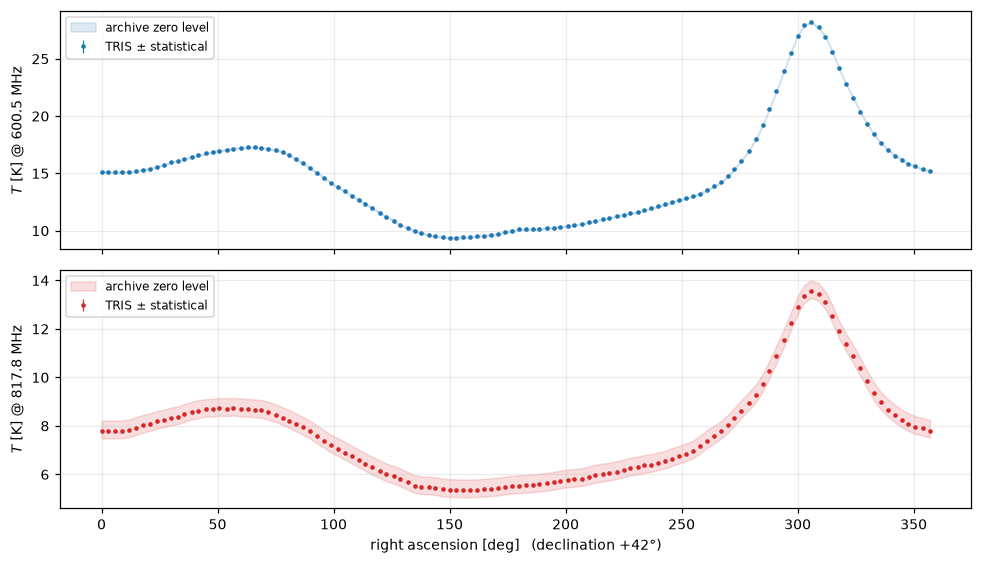

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
for ax, (freq, ring), colour in zip(axes, RINGS.items(), ("tab:blue", "tab:red")):
    ax.errorbar(ring.ra_deg, ring.temperature_k, yerr=ring.statistical_uncertainty_k,
                fmt=".", ms=4, color=colour, label="TRIS ± statistical")
    zero = ring.zero_level_uncertainty_k
    lo, hi = (zero, zero) if np.isscalar(zero) else (zero.negative_k, zero.positive_k)
    ax.fill_between(ring.ra_deg, ring.temperature_k - lo, ring.temperature_k + hi,
                    color=colour, alpha=0.15, label="archive zero level")
    ax.set_ylabel(f"$T$ [K] @ {ring.effective_frequency_mhz:.1f} MHz")
    ax.legend(loc="upper left")
    ax.grid(alpha=0.25)
axes[1].set_xlabel("right ascension [deg]   (declination +42°)")
# axes[0].set_title("The absolute rings stage 1 fits — the zero level dwarfs the "
                #   "statistical errors")
fig.tight_layout()

#### Where `tris.zero_level_sigma_k = 0.5` comes from

The published zero level is one fully correlated offset. Stage 1 carries it as an
explicit nuisance parameter with a Gaussian prior — exactly equivalent to the rank-1
noise term, but it also hands back the fitted offset.

The catch is that the 820 MHz zero level is **asymmetric**, and limTOD deliberately
refuses to symmetrise it. A single Gaussian width has to cover both rings without
claiming a precision the 820 MHz ring does not have.

In [4]:
chosen = float(config.require("tris.zero_level_sigma_k"))
print(f"{'ring':>6}  {'archive zero level':<34}{'covered by 0.5 K?':>18}")
for freq, ring in RINGS.items():
    z = ring.zero_level_uncertainty_k
    text = (f"{float(z):.3f} K (symmetric)" if np.isscalar(z)
            else f"+{z.positive_k:.3f} / -{z.negative_k:.3f} K (ASYMMETRIC)")
    widest = float(z) if np.isscalar(z) else max(z.positive_k, z.negative_k)
    print(f"{freq:6d}  {text:<34}{'yes' if chosen >= widest else 'NO':>18}")
print(f"\ntris.zero_level_sigma_k = {chosen} K: one symmetric prior wide enough for both,")
print("recorded as a decision rather than silently symmetrising +0.430/-0.300.")

  ring  archive zero level                 covered by 0.5 K?
   600  0.066 K (symmetric)                              yes
   820  +0.430 / -0.300 K (ASYMMETRIC)                   yes

tris.zero_level_sigma_k = 0.5 K: one symmetric prior wide enough for both,
recorded as a decision rather than silently symmetrising +0.430/-0.300.


---
### The temperature convention

The archive never states Rayleigh–Jeans vs thermodynamic, nor whether the CMB monopole is
included. The two rings share an RA grid, so the Galactic spectral index between them is a
clean per-sample discriminator: only one treatment gives synchrotron. Stage 1's template
is built with `to_tris_temperature_convention`, so this has to come out right or every
kelvin downstream is wrong.

CMB monopole: thermodynamic 2.72548 K, RJ-equivalent 2.7111 K at 600.5 MHz
treatment                        min   median     max
CMB monopole left in           -2.39    -2.10   -1.81
CMB monopole removed (RJ)      -3.12    -2.91   -2.63

Synchrotron is -2.5..-3.1. Only the second row is physical, so TRIS
temperatures are Rayleigh-Jeans and INCLUDE the CMB monopole.


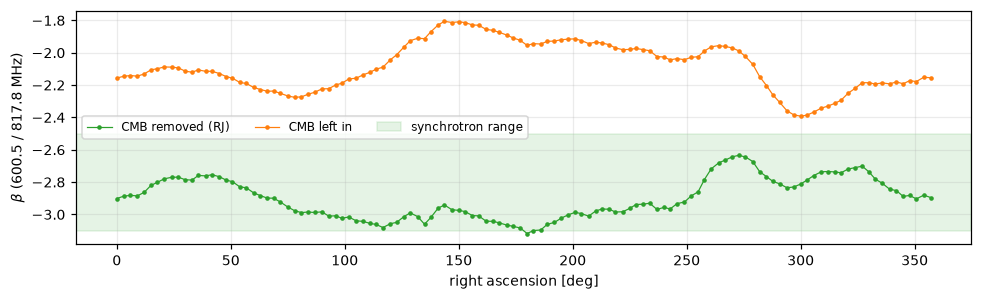

In [5]:
nu6, nu8 = ring600.effective_frequency_mhz, ring820.effective_frequency_mhz
assert np.allclose(ring600.ra_deg, ring820.ra_deg)

with_cmb = np.log(ring600.temperature_k / ring820.temperature_k) / np.log(nu6 / nu8)
without = tris.galactic_spectral_index(ring600.temperature_k, nu6,
                                       ring820.temperature_k, nu8)

print(f"CMB monopole: thermodynamic {tris.CMB_T0_K:.5f} K, "
      f"RJ-equivalent {tris.cmb_monopole_rj_k(nu6):.4f} K at {nu6} MHz")
print(f"{'treatment':<28}{'min':>8}{'median':>9}{'max':>8}")
print(f"{'CMB monopole left in':<28}{with_cmb.min():8.2f}{np.median(with_cmb):9.2f}"
      f"{with_cmb.max():8.2f}")
print(f"{'CMB monopole removed (RJ)':<28}{without.min():8.2f}{np.median(without):9.2f}"
      f"{without.max():8.2f}")
print("\nSynchrotron is -2.5..-3.1. Only the second row is physical, so TRIS")
print("temperatures are Rayleigh-Jeans and INCLUDE the CMB monopole.")

fig, ax = plt.subplots()
ax.plot(ring600.ra_deg, without, ".-", ms=4, color="tab:green",
        label="CMB removed (RJ)")
ax.plot(ring600.ra_deg, with_cmb, ".-", ms=4, color="tab:orange",
        label="CMB left in")
ax.axhspan(-3.1, -2.5, color="tab:green", alpha=0.12, label="synchrotron range")
ax.set_xlabel("right ascension [deg]")
ax.set_ylabel(r"$\beta$ (600.5 / 817.8 MHz)")
ax.legend(ncol=3); ax.grid(alpha=0.25)
fig.tight_layout()

---
### The beam

Stage 1 builds the beam from the archive's own principal-plane cuts, never a Gaussian:
the cuts run to 176° and −49 dB, and the Gaussian has no shoulders at all. The
below-horizon response is small but not negligible against the published 0.066 K
systematic, which is why the horizon mask is on.

archive table HPBW: E 19.155 deg, H 23.366 deg  (the ring header's '18 deg' is -6.0% off)



Blocker 1 — beam.beam_deg = 21.2605 deg (mean of E and H = 21.2603)
  bayesian_func.nside_for_beam -> 8, config pins 16  -> differ: nside_new follows the TRIS map grid; recorded in the manifest, not enforced


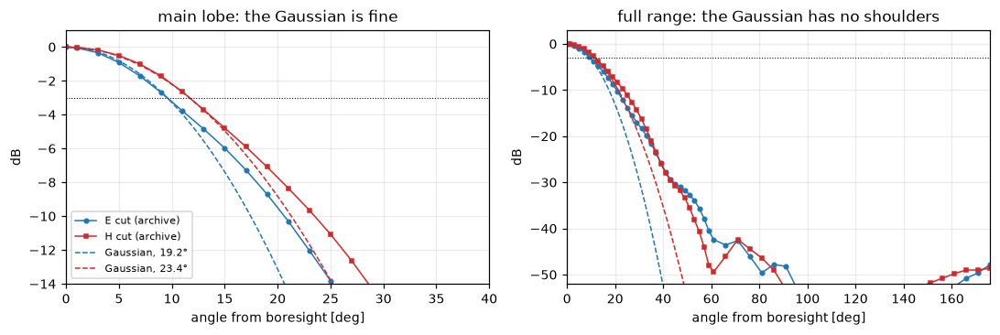

In [6]:
e_fwhm, h_fwhm = cuts.half_power_full_width_deg()
half_power_db = -10 * np.log10(2)
print(f"archive table HPBW: E {e_fwhm:.3f} deg, H {h_fwhm:.3f} deg  "
      f"(the ring header's '18 deg' is {100*(18/e_fwhm-1):+.1f}% off)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
fine = np.linspace(0, 60, 400)
for ax, span in zip(axes, [(0, 40, -14, 1), (0, 176, -52, 3)]):
    ax.plot(cuts.angle_deg, cuts.e_plane_db, "o-", ms=3, color="tab:blue",
            label="E cut (archive)")
    ax.plot(cuts.angle_deg, cuts.h_plane_db, "s-", ms=3, color="tab:red",
            label="H cut (archive)")
    ax.plot(fine, half_power_db * (2 * fine / e_fwhm) ** 2, "--", color="tab:blue",
            label=f"Gaussian, {e_fwhm:.1f}°")
    ax.plot(fine, half_power_db * (2 * fine / h_fwhm) ** 2, "--", color="tab:red",
            label=f"Gaussian, {h_fwhm:.1f}°")
    ax.axhline(half_power_db, color=COLORS["ink"], lw=0.7, ls=":")
    ax.set_xlim(span[0], span[1]); ax.set_ylim(span[2], span[3])
    ax.set_xlabel("angle from boresight [deg]"); ax.set_ylabel("dB")
    ax.grid(alpha=0.25)
axes[0].legend()
axes[0].set_title("main lobe: the Gaussian is fine")
axes[1].set_title("full range: the Gaussian has no shoulders")
fig.tight_layout()

In [7]:
NSIDE_BEAM = 128
cut_beam = tris.tris_cut_beam_map(cuts, nside=NSIDE_BEAM, normalization="peak")
gauss_beam = tris.approximate_tris_gaussian_beam_map(nside=NSIDE_BEAM,
                                                     normalization="peak")
theta = np.rad2deg(hp.pix2ang(NSIDE_BEAM, np.arange(hp.nside2npix(NSIDE_BEAM)))[0])
order = np.argsort(theta)
mask = tris.tris_horizon_mask(NSIDE_BEAM)

print(f"{'beam':<16}{'θ<10°':>9}{'θ<20°':>9}{'θ<30°':>9}{'θ<45°':>9}"
      f"{'below horizon':>16}{'ground @300K':>14}")
for name, beam in (("Gaussian", gauss_beam), ("archive cuts", cut_beam)):
    weight = beam / beam.sum()
    cumulative = np.cumsum(weight[order])
    below = float(weight[mask == 0].sum())
    cums = [cumulative[theta[order] < lim][-1] for lim in (10, 20, 30, 45)]
    print(f"{name:<16}" + "".join(f"{c:9.4f}" for c in cums)
          + f"{below:16.2e}{below*300:14.3f} K")
print("\nbeam.apply_horizon_mask =", config.require("beam.apply_horizon_mask"),
      "-- the cut beam's ground pickup is comparable to the 0.066 K systematic.")

beam                θ<10°    θ<20°    θ<30°    θ<45°   below horizon  ground @300K
Gaussian           0.4917   0.9260   0.9965   1.0000        2.77e-20         0.000 K
archive cuts       0.3809   0.8107   0.9660   0.9970        1.16e-04         0.035 K

beam.apply_horizon_mask = True -- the cut beam's ground pickup is comparable to the 0.066 K systematic.


---
### The prior template

There is no true sky for real data, so
**GSM2008 is used as both the prior template and the reference "truth"**. That is
circular by construction and stage 1's manifest records it as such.

What makes it still worth doing is the number below. Forward-modelling GSM2008 through
the same geometry and beam that stage 1 uses gives a *measured* offset against the
absolutely-calibrated rings — and stage 1's fitted zero level should come out at
roughly that value, because a tight per-pixel prior leaves the nuisance offset as the
only place a template error can go. That correspondence is the real check on stage 1,
and Part C makes it.

In [8]:
from limTOD import generate_TOD_sky

NSIDE_SKY = int(config.require("tris.nside"))
horizon = tris.tris_horizon_mask(NSIDE_SKY)
beam_sky = tris.tris_cut_beam_map(cuts, nside=NSIDE_SKY, normalization="peak")

templates, profiles, offsets = {}, {}, {}
for freq, ring in RINGS.items():
    nu = ring.effective_frequency_mhz
    templates[freq] = stage1.gsm2008_template(nu, NSIDE_SKY)   # the stage 1 template
    g = tris.tris_zenith_geometry(ring.ra_deg)
    profiles[freq] = generate_TOD_sky(beam_sky, templates[freq], g.lst_deg,
                                      g.latitude_deg, g.azimuth_deg, g.elevation_deg,
                                      g.selfrot_deg, normalize_beam=True,
                                      horizontal_mask=horizon)
    offsets[freq] = profiles[freq] - ring.temperature_k

print(f"{'nu [MHz]':>9}{'mean GSM2008 - TRIS':>22}{'scatter rms':>13}{'max |Δ|':>10}")
for freq, d in offsets.items():
    print(f"{freq:9d}{d.mean():+22.3f}{d.std():13.3f}{np.abs(d).max():10.3f}")
print("\nGSM2008 runs COLD against the absolute rings. Stage 1's fitted zero level")
print("should land near the negative of these means:",
      {f: round(-float(d.mean()), 2) for f, d in offsets.items()}, "K")

 nu [MHz]   mean GSM2008 - TRIS  scatter rms   max |Δ|
      600                -1.950        0.570     4.425
      820                -0.577        0.302     1.627

GSM2008 runs COLD against the absolute rings. Stage 1's fitted zero level
should land near the negative of these means: {600: 1.95, 820: 0.58} K


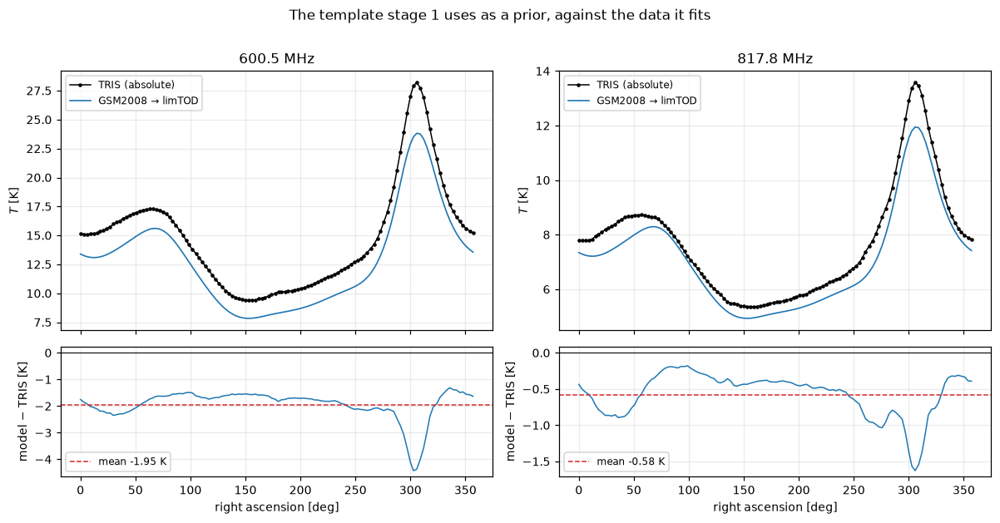

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharex="col",
                         gridspec_kw={"height_ratios": [2, 1]})
for col, (freq, ring) in enumerate(RINGS.items()):
    top, bot = axes[0, col], axes[1, col]
    top.plot(ring.ra_deg, ring.temperature_k, ".-", ms=4, color=COLORS["data"],
             label="TRIS (absolute)")
    top.plot(ring.ra_deg, profiles[freq], color="tab:blue",
             label="GSM2008 → limTOD")
    bot.plot(ring.ra_deg, offsets[freq], color="tab:blue")
    bot.axhline(0, color=COLORS["ink"], lw=0.7)
    bot.axhline(offsets[freq].mean(), color="tab:red", ls="--",
                label=f"mean {offsets[freq].mean():+.2f} K")
    top.set_ylabel("$T$ [K]"); bot.set_ylabel("model − TRIS [K]")
    bot.set_xlabel("right ascension [deg]")
    top.set_title(f"{ring.effective_frequency_mhz:.1f} MHz")
    top.legend(); bot.legend()
    top.grid(alpha=0.25); bot.grid(alpha=0.25)
fig.suptitle("The template stage 1 uses as a prior, against the data it fits", y=1.01)
fig.tight_layout()

---
### Pixelisation: what 120 samples can and cannot support

The beam is 19.2° × 23.4°, and a 120-sample ring measures roughly 15 independent numbers
because the beam suppresses harmonics above $m\sim8$. The table below is the honest
accounting of what each candidate `tris.nside` asks for.

`tris.nside` is the grid stage 1 *solves* on, and the ratio of
pixels to samples is what decides how much of the answer is prior rather than data.

In [10]:
working = int(config.require("tris.nside"))
target = int(config.require("beam.nside_new"))
half_width = float(config.require("tris.dec_half_width_deg"))
dec = tris.tris_zenith_geometry(ring600.ra_deg).boresight_dec_deg
n_samples = ring600.ra_deg.size

print(f"{'nside':>7}{'pixel [deg]':>13}{'E FWHM/pix':>12}{'H FWHM/pix':>12}"
      f"{'pixels in band':>16}{'samples/pixel':>15}   note")
for nside in (4, 8, 16, 32, 64):
    pixel_deg = hp.nside2resol(nside, arcmin=True) / 60
    n_band = tris.tris_ring_pixels(nside, dec_deg=dec,
                                   half_width_deg=half_width).size
    note = []
    if nside == working:
        note.append("tris.nside (stage 1 solves here)")
    if nside == target:
        note.append("beam.nside_new (stage 3 target)")
    print(f"{nside:7d}{pixel_deg:13.2f}{e_fwhm/pixel_deg:12.2f}{h_fwhm/pixel_deg:12.2f}"
          f"{n_band:16d}{n_samples/n_band:15.4f}   {', '.join(note)}")
print(f"\nThe ring has {n_samples} samples and about 15 independent numbers in them.")
print("At every nside in this table the pixels outnumber the data, so the map is")
print("prior-dominated by construction -- 03_diagnostics.ipynb measures by how much.")

  nside  pixel [deg]  E FWHM/pix  H FWHM/pix  pixels in band  samples/pixel   note
      4        14.66        1.31        1.59             104         1.1538   
      8         7.33        2.61        3.19             400         0.3000   
     16         3.66        5.23        6.38            1632         0.0735   tris.nside (stage 1 solves here), beam.nside_new (stage 3 target)
     32         1.83       10.45       12.75            6460         0.0186   
     64         0.92       20.91       25.51           25704         0.0047   

The ring has 120 samples and about 15 independent numbers in them.
At every nside in this table the pixels outnumber the data, so the map is
prior-dominated by construction -- 03_diagnostics.ipynb measures by how much.


---
## 02 — ARCADE 2

ARCADE 2 is a balloon-borne, absolutely calibrated radiometer. It is excluded from every fit (`sed.exclude_maps`:
it reaches only 16–17 of the 120 ring samples), but stage 2 beam-matches it, and this section checks how its files
must be handled: the pixelisation the maps arrive on, and how they mark the sky they never observed.

### 3.15 GHz

In [11]:
with fits.open(RES / "ARCADE2_315.fits") as hdul:
    hdul.info()
    print(hdul[1].header)   # HEALPix maps store data in a binary table, usually HDU 1

Filename: /Users/user/Documents/Codes/project3/moonrunes/res/ARCADE2_315.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      20   ()      
  1  Archive Map Table    1 BinTableHDU     31   3072R x 2C   [E, E]   


XTENSION= 'BINTABLE'           /binary table extension                          BITPIX  =                    8 /8-bit bytes                                     NAXIS   =                    2 /2-dimensional binary table                      NAXIS1  =                    8 /width of table in bytes                         NAXIS2  =                 3072 /number of rows in table                         PCOUNT  =                    0 /size of special data area                       GCOUNT  =                    1 /one data group (required keyword)               TFIELDS =                    2 /number of fields in each row                    COMMENT                                                                         COMMENT  *** End of mandatory fields ***                                        COMMENT                                                                         COMMENT                                                                         COMMENT  *** Column names ***           

nside: 16
npix:  3072


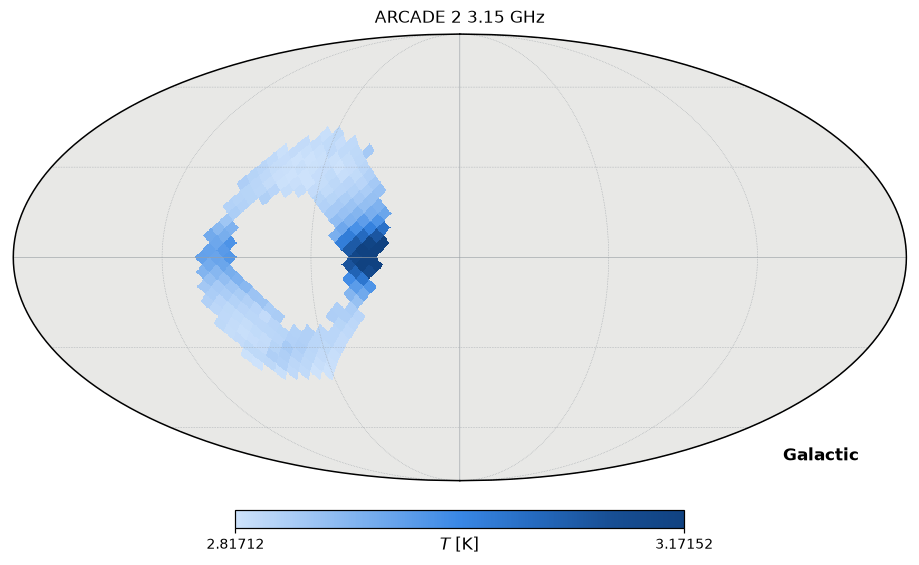

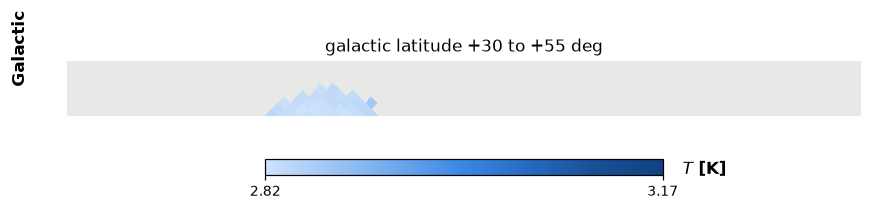

In [12]:
arcade315 = hp.read_map(RES / "ARCADE2_315.fits")
# Check these explicitly before doing anything else -- they matter:
print("nside:", hp.get_nside(arcade315))
print("npix: ", hp.get_map_size(arcade315))

# Percentile limits, matching every other map in this notebook.
# NOTE: ~93% of these pixels are exact zero (unobserved sky stored as
# data), so they sit at the bottom of the ramp and compress the real
# range. Section 02 measures that; this is only how it looks.
lo_a, hi_a = np.percentile(arcade315[arcade315 != 0], [2, 98])

# Unobserved sky is stored as exact 0.0 in these files. Plot it as NaN so it
# renders like TRIS's unobserved sky rather than as a very cold measurement --
# the array itself is untouched, this is display only.
arcade315_shown = np.where(arcade315 == 0, np.nan, arcade315)

hp.mollview(arcade315_shown, title="ARCADE 2 3.15 GHz", unit="$T$ [K]", coord="G", min=lo_a, max=hi_a, **MAP_KW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
# latra is GALACTIC latitude here, not TRIS's equatorial dec +42 band.
hp.cartview(arcade315_shown, latra=[30, 55], unit="$T$ [K]",
            title="galactic latitude +30 to +55 deg", coord="G", min=lo_a, max=hi_a, **MAP_KW)
plt.show()

### 3.41 GHz

In [13]:
with fits.open(RES / "ARCADE2_341.fits") as hdul:
    hdul.info()
    print(hdul[1].header)   # HEALPix maps store data in a binary table, usually HDU 1

Filename: /Users/user/Documents/Codes/project3/moonrunes/res/ARCADE2_341.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      20   ()      
  1  Archive Map Table    1 BinTableHDU     31   3072R x 2C   [E, E]   


XTENSION= 'BINTABLE'           /binary table extension                          BITPIX  =                    8 /8-bit bytes                                     NAXIS   =                    2 /2-dimensional binary table                      NAXIS1  =                    8 /width of table in bytes                         NAXIS2  =                 3072 /number of rows in table                         PCOUNT  =                    0 /size of special data area                       GCOUNT  =                    1 /one data group (required keyword)               TFIELDS =                    2 /number of fields in each row                    COMMENT                                                                         COMMENT  *** End of mandatory fields ***                                        COMMENT                                                                         COMMENT                                                                         COMMENT  *** Column names ***           

nside: 16
npix:  3072


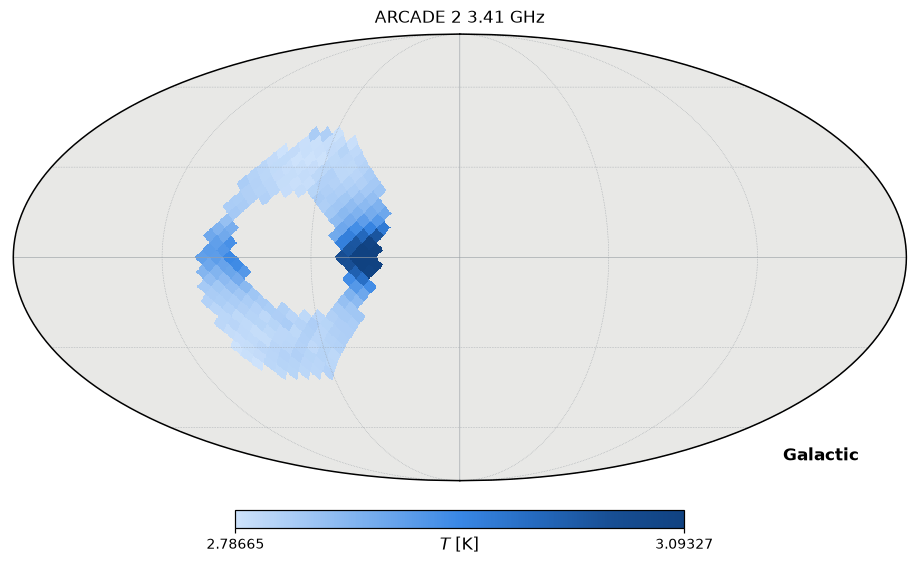

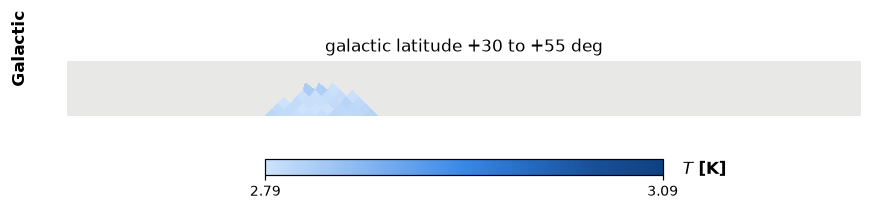

In [14]:
arcade341 = hp.read_map(RES / "ARCADE2_341.fits")
# Check these explicitly before doing anything else -- they matter:
print("nside:", hp.get_nside(arcade341))
print("npix: ", hp.get_map_size(arcade341))

# Percentile limits, matching every other map in this notebook.
# NOTE: ~93% of these pixels are exact zero (unobserved sky stored as
# data), so they sit at the bottom of the ramp and compress the real
# range. Section 02 measures that; this is only how it looks.
lo_a, hi_a = np.percentile(arcade341[arcade341 != 0], [2, 98])

# Unobserved sky is stored as exact 0.0 in these files. Plot it as NaN so it
# renders like TRIS's unobserved sky rather than as a very cold measurement --
# the array itself is untouched, this is display only.
arcade341_shown = np.where(arcade341 == 0, np.nan, arcade341)

hp.mollview(arcade341_shown, title="ARCADE 2 3.41 GHz", unit="$T$ [K]", coord="G", min=lo_a, max=hi_a, **MAP_KW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
# latra is GALACTIC latitude here, not TRIS's equatorial dec +42 band.
hp.cartview(arcade341_shown, latra=[30, 55], unit="$T$ [K]",
            title="galactic latitude +30 to +55 deg", coord="G", min=lo_a, max=hi_a, **MAP_KW)
plt.show()

### Are the unobserved pixels marked, or just zero?

`hp.UNSEEN` is the HEALPix sentinel for "no data here". If a partial-sky map does not use
it, an unobserved pixel is indistinguishable from a genuinely cold one, and every mean,
ratio or fit taken over the map is silently wrong.

This matters directly for Step 0 of the SED pipeline, which has to smooth ARCADE 2 down
to the TRIS beam: `hp.smoothing` works through a global spherical harmonic transform and
knows nothing about masks, so whatever these pixels contain gets spread across the mask
boundary into the data.

In [15]:
for label, m in (("3.15 GHz", arcade315), ("3.41 GHz", arcade341)):
    npix = m.size
    zero_marked = int(np.sum(m == 0))
    print(f"ARCADE 2 {label} map")
    print("  Any UNSEEN?", np.any(m == hp.UNSEEN))
    print("  Any NaN?   ", np.any(np.isnan(m)))
    print(f"  Exact zeros (suspicious if widespread): {zero_marked}/{npix}"
          f" = {zero_marked / npix * 100:.1f}% of pixels")
    print()

ARCADE 2 3.15 GHz map
  Any UNSEEN? False
  Any NaN?    False
  Exact zeros (suspicious if widespread): 2852/3072 = 92.8% of pixels

ARCADE 2 3.41 GHz map
  Any UNSEEN? False
  Any NaN?    False
  Exact zeros (suspicious if widespread): 2840/3072 = 92.4% of pixels



Neither sentinel is present and most of the sky is exact zero, so **the unobserved pixels
are plain zeros**: the mask has to be reconstructed from the zeros before anything else
happens to these maps. Stage 2's masked smoothing does exactly
this — zero the masked pixels, smooth a binary weight map with the same kernel, divide,
then re-mask where the smoothed weight drops too low.

Two more things the header and the plots settle:

* the maps arrive **`NESTED` at nside 16** — `hp.read_map` reorders to `RING` on the way
  in, which is why the plots come out right without anything being said about it. Note
  how coarse that is: nside 16 is a 3.7° pixel, against Haslam's nside 512;
* the header carries **no `COORDSYS`**, so the `coord="G"` passed to the plotting calls
  is an assumption made here, not something the file states (Part B confirms it against
  the sky).

The `cartview` panels are cut on **galactic** latitude, so they are not TRIS's
declination strip — TRIS's
dec +42° band is equatorial and would need a frame conversion to appear here.

---
## 03 — Haslam 408 MHz

The map the whole pipeline exists to calibrate: the one untrusted point in the SED, at
408 MHz, against which the power law fitted to the four trusted TRIS and ARCADE 2 points
is evaluated.

This is the copy downloaded into `res/`. It is not what stage 2 reads — `paths.haslam_map`
is `null`, which means stage 2 takes the destriped/desourced Remazeilles (2015) map from
the astropy cache `pygdsm` populates. So treat this section as a look at the archive
product, not as a check on what stage 2 loaded.

In [16]:
with fits.open(RES / "HASLAM.fits") as hdul:
    hdul.info()
    print(hdul[1].header)   # HEALPix maps store data in a binary table, usually HDU 1

Filename: /Users/user/Documents/Codes/project3/moonrunes/res/HASLAM.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   ()      
  1                1 BinTableHDU     42   3072R x 1C   [1024E]   


XTENSION= 'BINTABLE'           /Written by IDL:  Mon Nov 17 15:46:41 2014       BITPIX  =                    8 /                                                NAXIS   =                    2 /Binary table                                    NAXIS1  =                 4096 /Number of bytes per row                         NAXIS2  =                 3072 /Number of rows                                  PCOUNT  =                    0 /Random parameter count                          GCOUNT  =                    1 /Group count                                     TFIELDS =                    1 /Number of columns                               TFORM1  = '1024E   '           /Real*4 (floating point)                         TTYPE1  = 'TEMPERATURE '       /label for field   1                             PIXTYPE = 'HEALPIX '           / HEALPIX pixelisation                           ORDERING= 'RING    '           / Pixel ordering scheme, either RING or NESTED   NSIDE   =                  512 / Healpix

nside: 512
npix:  3145728


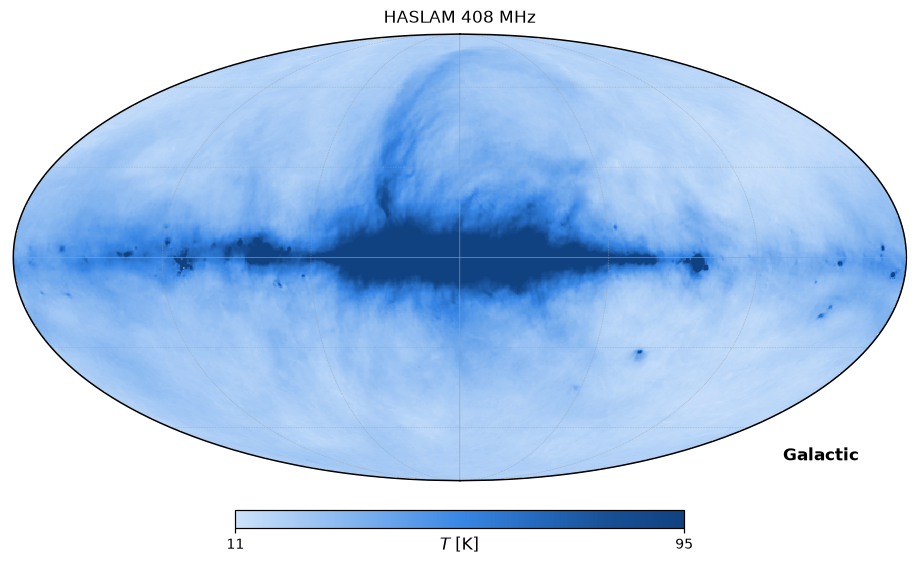

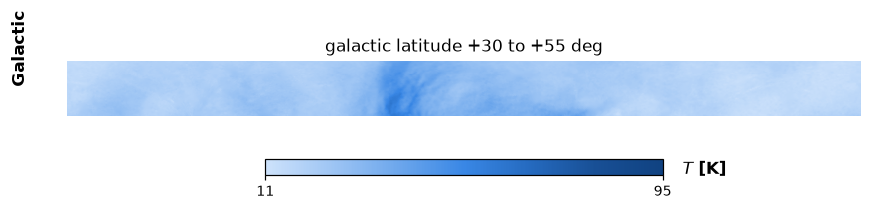

In [17]:
haslam = hp.read_map(RES / "HASLAM.fits")
# Check these explicitly before doing anything else -- they matter:
print("nside:", hp.get_nside(haslam))
print("npix: ", hp.get_map_size(haslam))

# min/max by hand: the galactic plane runs to thousands of K and
# swamps a linear scale.
lo_h, hi_h = 11, 95

hp.mollview(haslam, title="HASLAM 408 MHz", unit="$T$ [K]", coord="G", min=lo_h, max=hi_h, **MAP_KW)
hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
# latra is GALACTIC latitude here, not TRIS's equatorial dec +42 band.
hp.cartview(haslam, latra=[30, 55], unit="$T$ [K]",
            title="galactic latitude +30 to +55 deg", coord="G", min=lo_h, max=hi_h, **MAP_KW)
plt.show()

In [18]:
print("HASLAM 408 MHz map")
print("  Any UNSEEN?", np.any(haslam == hp.UNSEEN))
print("  Any NaN?   ", np.any(np.isnan(haslam)))
print("  Any exact zero (suspicious if widespread)?", int(np.sum(haslam == 0)))

HASLAM 408 MHz map
  Any UNSEEN? False
  Any NaN?    False
  Any exact zero (suspicious if widespread)? 0


Full sky, no sentinels and no zeros — the opposite situation to ARCADE 2, so none of the
mask handling above applies to it. The header states `RING` at nside 512 and
`COORDSYS = GALACTIC`, which is the one native frame among the three datasets: Haslam is
galactic, the TRIS maps are equatorial, and ARCADE 2 declines to say (Part B).

---
## 04 TRIS maps

The maps stage 1 made from the drift rings — the 600 and 820 MHz points of the SED, and
the only absolutely calibrated ones with spatial structure. Section 01 looked at the
*rings*; this loads what the map-maker turned them into.

Same treatment as ARCADE 2 and Haslam: what the file contains, the pixelisation, the
maps, and how the sky it never saw is marked.

Two things about these products are deliberate and worth having in mind before the
numbers appear. The grid is **coarse on purpose** — the beam is 19–23°, so there is no
information to put on a fine grid.
And the pixels are selected **by beam response**, not by a declination cut: a pixel is
kept if the beam response at it exceeds `tris.beam_response_threshold` of the peak for at
least one observation.

In [19]:
from moonrunes.stage1_tris_maps import load_stage1

products = load_stage1(config)                    # nside 16, the configured run
products8 = load_stage1(                          # nside 8, the coarser comparison
    config,
    maps_path=REPO / "outputs" / "stage1_nside8" / "tris_maps_tris_haslam_v0.npz",
    manifest_path=REPO / "outputs" / "stage1_nside8" / "stage1_manifest.json",
)
GRIDS = {8: products8, 16: products}
print(products.maps_path.name, "and", products.manifest_path.name, "\n")

# The npz is the analogue of the FITS header dump above: what is in the file.
print(f"  {'array':26s}{'dtype':10s}shape")
for key, arr in products.arrays.items():
    print(f"  {key:26s}{str(arr.dtype):10s}{arr.shape}")

print("\nrun     ", products.manifest["run_name"], "written", products.manifest["written_utc"])
print("blocker 2", products.manifest["blocker_2_substitute"]["prior_equals_truth"],
      "= prior_equals_truth")

tris_maps_tris_haslam_v0.npz and stage1_manifest.json 

  array                     dtype     shape
  nside                     int64     ()
  pixel_indices             int64     (1272,)
  band_mask                 bool      (3072,)
  freq_mhz                  float64   (2,)
  effective_freq_mhz        float64   (2,)
  ref_freq_mhz              float64   ()
  sky_k                     float64   (2, 1272)
  sky_sigma_k               float64   (2, 1272)
  prior_mean_k              float64   (2, 1272)
  prior_sigma_k             float64   (2, 1272)
  truth_k                   float64   (2, 1272)
  zero_level_k              float64   (2,)
  zero_level_sigma_k        float64   (2,)
  zero_level_prior_sigma_k  float64   (2,)
  ra_deg                    float64   (2, 120)
  data_k                    float64   (2, 120)
  residual_k                float64   (2, 120)
  beam_coverage             float64   (2, 120)
  sky_full_k                float64   (2, 3072)
  sky_sigma_full_k          float64

In [20]:
sky_full = products["sky_full_k"]          # (Nfreq, npix), NaN outside the selection
eff = products["effective_freq_mhz"]
npix = sky_full.shape[1]

# Check these explicitly before doing anything else -- they matter:
print("nside:", products.nside)
print("npix: ", npix)
print("freqs:", ", ".join(f"{f:.0f} MHz (nu_eff {e:.1f})"
                          for f, e in zip(products.frequencies_mhz, eff)))
print("frame: equatorial -- stage 3 is what rotates this into the galactic frame")

sel = products.diagnostics(600)["pixel_selection"]
print(f"\npixel selection: beam response > {sel['threshold']:g} of peak, "
      f"for at least one observation")
print(f"  {sel['n_pixels']} pixels kept ({sel['sky_fraction']:.1%} of sky), "
      f"{sel['beam_power_retained']:.4%} of beam power retained")
print(f"  {sel['samples_per_pixel']:.3f} samples per pixel "
      f"-- 120 samples spread over {sel['n_pixels']} parameters")

print(f"\n{'nu [MHz]':>9}{'observed pixels':>18}{'sky fraction':>15}"
      f"{'min [K]':>10}{'median [K]':>12}{'max [K]':>10}")
for i, freq in enumerate(products.frequencies_mhz):
    m = sky_full[i]
    observed = int(np.isfinite(m).sum())
    print(f"{freq:9.0f}{observed:18d}{observed / npix:15.3f}"
          f"{np.nanmin(m):10.3f}{np.nanmedian(m):12.3f}{np.nanmax(m):10.3f}")

nside: 16
npix:  3072
freqs: 600 MHz (nu_eff 600.5), 820 MHz (nu_eff 817.8)
frame: equatorial -- stage 3 is what rotates this into the galactic frame

pixel selection: beam response > 0.01 of peak, for at least one observation
  1272 pixels kept (41.4% of sky), 99.6054% of beam power retained
  0.094 samples per pixel -- 120 samples spread over 1272 parameters

 nu [MHz]   observed pixels   sky fraction   min [K]  median [K]   max [K]
      600              1272          0.414     6.167      11.502   133.495
      820              1272          0.414     4.223       6.534    51.277


In [21]:
products.frequencies_mhz

array([600., 820.])

plotting nside 16 maps (3072 pixels, 3.665 deg/pixel)


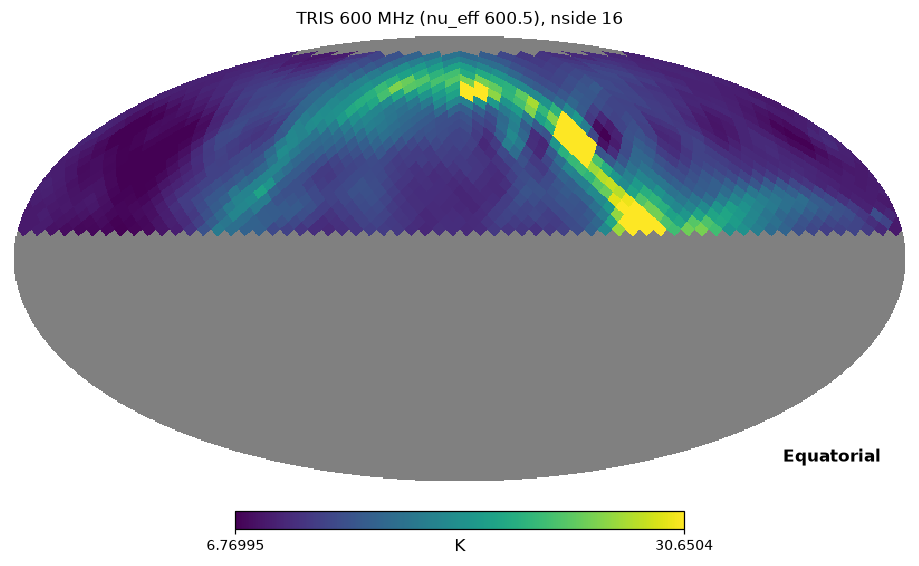

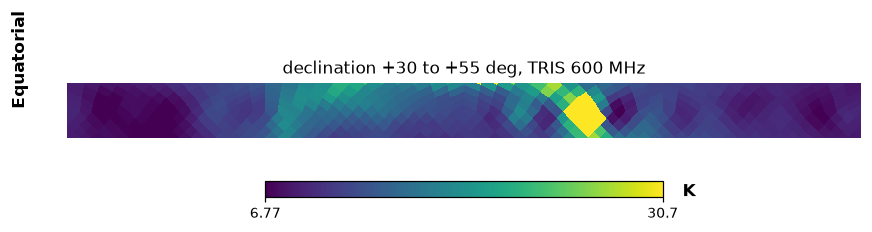

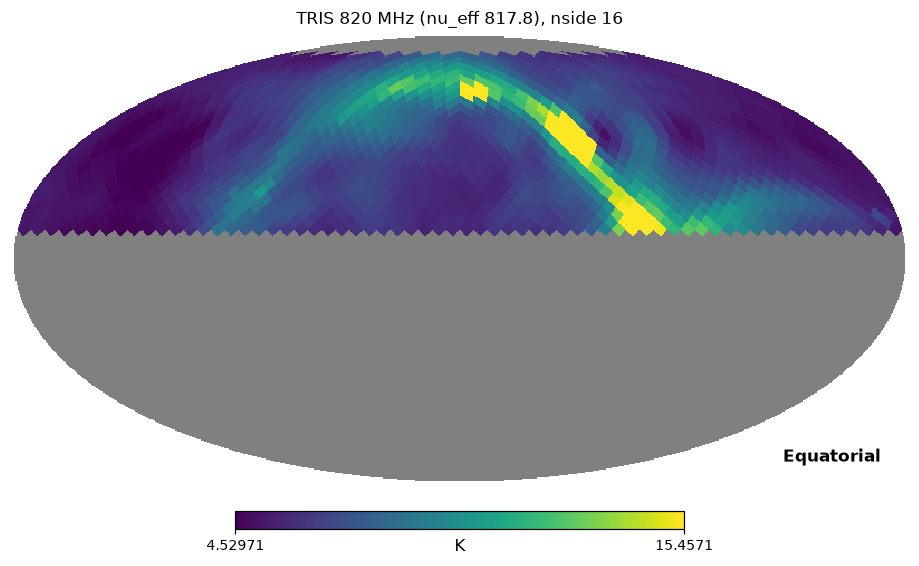

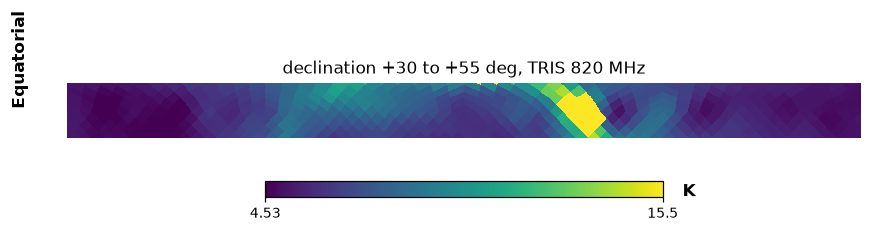

In [22]:
print(f"plotting nside {products.nside} maps "
      f"({npix} pixels, {hp.nside2resol(products.nside, arcmin=True) / 60:.3f} deg/pixel)")

for i, freq in enumerate(products.frequencies_mhz):
    m = sky_full[i]
    # Colour limits from percentiles rather than by hand: the galactic plane runs to
    # hundreds of K at 600 MHz and swamps a linear scale, exactly as it does in Haslam.
    lo, hi = np.nanpercentile(m, [2, 98])
    # No norm= here: healpy only understands "hist", "log" and "symlog" and falls back
    # to linear for anything else, so norm="auto" was never doing anything.
    hp.mollview(m, unit="K", coord="C", min=lo, max=hi,
                title=f"TRIS {freq:.0f} MHz (nu_eff {eff[i]:.1f}), nside {products.nside}")
    # latra is DECLINATION here, not galactic latitude -- these maps are equatorial,
    # so unlike sections 02 and 03 this really is a TRIS declination strip.
    hp.cartview(m, latra=[30, 55], unit="K", coord="C", min=lo, max=hi,
                title=f"declination +30 to +55 deg, TRIS {freq:.0f} MHz")
    if freq==600.:
        m_tris_600 = m
    else:
        m_tris_820 = m
plt.show()

#### Is that plotted correctly?

Three things have to hold for these panels to mean what they look like, and none of them
is stated by the npz: the pixel **ordering** (RING vs NESTED), the **frame** the pixel
indices were built in, and whether `coord="C"` is therefore the right thing to pass. Each
one is silent when wrong — a NESTED map read as RING still plots, it just plots scrambled
sky — so all three are measured here rather than assumed.

The ordering test also doubles as a check on the beam-response selection. TRIS drifts
through **all** right ascensions at a fixed elevation, so whatever the beam sees at one RA
it sees at every RA: the retained set must come out as a **pure declination band**, with no
RA structure in it. If the selection had RA dependence, something would be wrong with the
pointing or the beam projection.

In [23]:
from astropy.coordinates import SkyCoord
import astropy.units as u

check = sky_full[0]
npix_all = 12 * products.nside**2

# 1. The grid is what it claims to be.
print(f"nside {products.nside}: npix {check.size} == 12 x nside^2 ({npix_all}) "
      f"-> {check.size == npix_all}")

# 2. Ordering. Read the retained pixel indices both ways and ask which one gives a
#    declination band -- the only shape a full-RA drift scan can produce.
print("\nordering: does the retained set form a declination band?")
for nest in (False, True):
    dec = 90 - np.degrees(hp.pix2ang(products.nside, products.pixel_indices,
                                     nest=nest)[0])
    all_dec = 90 - np.degrees(hp.pix2ang(products.nside, np.arange(npix_all),
                                         nest=nest)[0])
    inside = int(((all_dec >= dec.min()) & (all_dec <= dec.max())).sum())
    label = "NESTED" if nest else "RING"
    verdict = ("CONTIGUOUS" if inside == products.pixel_indices.size
               else f"ragged ({inside - products.pixel_indices.size} holes)")
    print(f"  as {label:6s}: dec {dec.min():+7.2f} .. {dec.max():+7.2f}   {verdict}")

# 3. And no RA structure: every pixel inside the band, at any RA, must be retained.
dec = 90 - np.degrees(hp.pix2ang(products.nside, products.pixel_indices)[0])
geometry = tris.tris_zenith_geometry(products["ra_deg"][0])
half_width = 0.5 * (dec.max() - dec.min())
print(f"\nband centre {0.5 * (dec.min() + dec.max()):+.2f} deg vs boresight "
      f"{geometry.boresight_dec_deg:+.4f} deg")
print(f"band half-width {half_width:.2f} deg -- how far from boresight the beam still "
      f"reaches {sel['threshold']:g} of peak")

# 4. Frame. Treat every pixel centre as equatorial, convert to galactic, and ask where
#    the brightest sky sits. If the map were really galactic, the hot pixels would land
#    anywhere but b = 0.
theta, phi = hp.pix2ang(products.nside, np.arange(check.size))
b_deg = SkyCoord(ra=np.degrees(phi) * u.deg, dec=(90 - np.degrees(theta)) * u.deg,
                 frame="icrs").galactic.b.deg
observed = np.isfinite(check)
hottest = observed & (check > np.nanpercentile(check, 99))
print(f"\nhottest 1% of observed pixels: median |b| = "
      f"{np.median(np.abs(b_deg[hottest])):.2f} deg")
print(f"all observed pixels:           median |b| = "
      f"{np.median(np.abs(b_deg[observed])):.2f} deg")
print("-> the bright structure is the galactic plane, so the pixels are equatorial")
print("   and coord='C' (which labels, and does NOT rotate) is the right call.")

nside 16: npix 3072 == 12 x nside^2 (3072) -> True

ordering: does the retained set form a declination band?
  as RING  : dec   +9.59 ..  +75.34   CONTIGUOUS
  as NESTED: dec  -38.68 ..  +87.08   ragged (1256 holes)

band centre +42.47 deg vs boresight +42.4333 deg
band half-width 32.87 deg -- how far from boresight the beam still reaches 0.01 of peak

hottest 1% of observed pixels: median |b| = 2.14 deg
all observed pixels:           median |b| = 28.91 deg
-> the bright structure is the galactic plane, so the pixels are equatorial
   and coord='C' (which labels, and does NOT rotate) is the right call.


All of it holds: the grid is a valid nside 16 HEALPix map, the indices are **RING**, the
retained set is a **contiguous declination band with no RA structure** — the only shape a
full-RA drift scan can make — and the hottest 1% of pixels sit at a small median |b|
against ~30° for the band as a whole, so the Galaxy is where an equatorial map should put
it.

The band's half-width is the physically interesting number: it is how far off boresight
the beam still returns 1% of its peak, measured rather than assumed.

These maps are coarse by design and largely prior-driven; Part C measures by how much.

### How is the sky it never saw marked?

The same question asked of ARCADE 2, and the third distinct answer. A TRIS map is
partial-sky by construction — the beam only ever reaches part of the sky from a fixed
elevation.

In [24]:
for i, freq in enumerate(products.frequencies_mhz):
    m = sky_full[i]
    nan_count = int(np.isnan(m).sum())
    print(f"TRIS {freq:.0f} MHz map")
    print("  Any UNSEEN?", np.any(m == hp.UNSEEN))
    print("  Any NaN?   ", np.any(np.isnan(m)),
          f"-- {nan_count}/{npix} = {nan_count / npix * 100:.1f}% of pixels")
    print("  Exact zeros (suspicious if widespread):", int(np.sum(m == 0)))
    print()

print("band_mask in the npz says the same thing without the sentinel:",
      int(products['band_mask'].sum()), "observed pixels")

TRIS 600 MHz map
  Any UNSEEN? False
  Any NaN?    True -- 1800/3072 = 58.6% of pixels
  Exact zeros (suspicious if widespread): 0

TRIS 820 MHz map
  Any UNSEEN? False
  Any NaN?    True -- 1800/3072 = 58.6% of pixels
  Exact zeros (suspicious if widespread): 0

band_mask in the npz says the same thing without the sentinel: 1272 observed pixels


So the three datasets mark unobserved sky three different ways, and nothing in any file
says which convention it used:

| dataset | unobserved sky | mask recoverable from |
|---|---|---|
| **TRIS** (stage 1) | `NaN` — and an explicit `band_mask` in the npz | either; the `band_mask` is the reliable one |
| **ARCADE 2** | exact `0.0` | the zeros, and only the zeros |
| **Haslam** | nothing — full sky | n/a |

None of them uses `hp.UNSEEN`. Beam matching needs a boolean mask per dataset, and this
table is where each one comes from.

The other thing these maps carry that the others do not is a **per-pixel posterior σ**
(`sky_sigma_k`), which the SED fit wants as its weights.

## Check if HASLAM and TRIS have the same masking pattern

In [25]:
maps_to_check = {
    'Haslam': haslam,
    'TRIS 600 MHz': m_tris_600,
    'TRIS 820 MHz': m_tris_820,
}

for name, m in maps_to_check.items():
    n_zero = np.sum(m == 0)
    n_unseen = np.sum(m == hp.UNSEEN)
    n_nan = np.sum(np.isnan(m))
    pct_zero = n_zero / len(m) * 100
    print(f'{name}: exact-zero={n_zero} ({pct_zero:.2f}%), '
          f'UNSEEN={n_unseen}, NaN={n_nan}')

Haslam: exact-zero=0 (0.00%), UNSEEN=0, NaN=0
TRIS 600 MHz: exact-zero=0 (0.00%), UNSEEN=0, NaN=1800
TRIS 820 MHz: exact-zero=0 (0.00%), UNSEEN=0, NaN=1800


### The annulus

TRIS is a drift scan: the horn is parked and the sky rotates past it, so it sees every
right ascension at one band of declination. The footprint therefore has to be an
**annulus** — and from the celestial pole it should look like one literally.

The left panel is the coverage alone. The right is the temperature with the **Galactic
plane traced over it**: the plane is not a defect in the annulus, it is the brightest
thing in the radio sky at these frequencies, and it crosses the band twice.

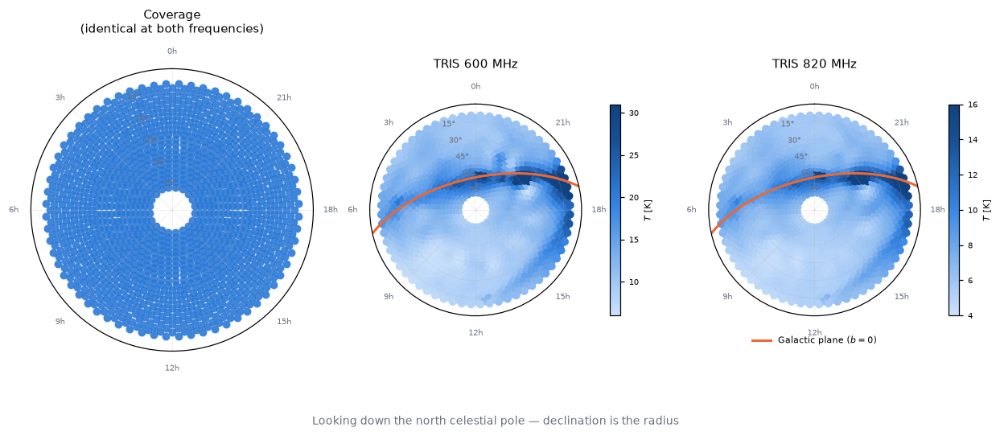

observed pixels per RA quadrant (an annulus must be flat across RA):
  RA   0- 90 deg:   318
  RA  90-180 deg:   318
  RA 180-270 deg:   318
  RA 270-360 deg:   318


In [26]:
sky = {f: products["sky_full_k"][products.index(f)] for f in (600, 820)}

# One colour scale PER FREQUENCY.  820 MHz is roughly half the temperature of
# 600 MHz -- synchrotron falls as nu^beta -- so a scale shared across frequency
# would flatten the 820 panel into a single tone and hide its structure.
LIMITS = {f: (np.floor(np.nanpercentile(m, 2)), np.ceil(np.nanpercentile(m, 98)))
          for f, m in sky.items()}
lo, hi = LIMITS[600]

# Azimuthal equidistant about the north celestial pole: radius is co-declination,
# so it is LINEAR in dec and both edges of the band stay visible.  An orthographic
# view squashes the outer edge to nothing -- the annulus then reads as a filled disc.
theta_all, phi_all = hp.pix2ang(products.nside, np.arange(sky[600].size))
co_dec = np.degrees(theta_all)
ra_rad = phi_all
seen = np.isfinite(sky[600])
size = (60.0 / products.nside) ** 2 * 3

plane = SkyCoord(l=np.linspace(0, 360, 1440) * u.deg, b=np.zeros(1440) * u.deg,
                 frame="galactic").icrs
north = plane.dec.deg > 0

fig, axes = plt.subplots(1, 3, figsize=(14, 5.0),
                         subplot_kw={"projection": "polar"})
for ax in axes:
    ax.set_theta_zero_location("N")
    ax.set_rlim(0, 90)
    ax.set_rticks([15, 30, 45, 60, 75])
    ax.set_yticklabels(["75°", "60°", "45°", "30°", "15°"],
                       color="#6b7280")
    ax.set_xticks(np.radians(np.arange(0, 360, 45)))
    ax.set_xticklabels([f"{h}h" for h in range(0, 24, 3)],
                       color="#6b7280")
    ax.grid(alpha=0.25, lw=0.5)
    ax.set_facecolor("white")

axes[0].scatter(ra_rad[seen], co_dec[seen], s=size, c="#2a78d6", linewidths=0,
                alpha=0.9)
axes[0].set_title("Coverage\n(identical at both frequencies)", pad=12)

for ax, freq in zip(axes[1:], (600, 820)):
    vlo, vhi = LIMITS[freq]
    sc = ax.scatter(ra_rad[seen], co_dec[seen], s=size, c=sky[freq][seen],
                    cmap=SEQ, vmin=vlo, vmax=vhi, linewidths=0)
    ax.plot(np.radians(plane.ra.deg[north]), 90 - plane.dec.deg[north],
            color="#eb6834", lw=2, label="Galactic plane ($b=0$)")
    ax.set_title(f"TRIS {freq} MHz", pad=12)
    cb = fig.colorbar(sc, ax=ax, shrink=0.62, pad=0.10)
    cb.set_label("$T$ [K]")
axes[2].legend(loc="lower center",
               bbox_to_anchor=(0.5, -0.18))
fig.suptitle("Looking down the north celestial pole — declination is the radius",
             color="#6b7280", y=0.03)
plt.show()

print("observed pixels per RA quadrant (an annulus must be flat across RA):")
ra_deg_all = np.degrees(phi_all)
for lo_ra, hi_ra in ((0, 90), (90, 180), (180, 270), (270, 360)):
    q = seen & (ra_deg_all >= lo_ra) & (ra_deg_all < hi_ra)
    print(f"  RA {lo_ra:3d}-{hi_ra:3d} deg: {int(q.sum()):5d}")

### nside 8 against nside 16

Both grids, same data, same beam-response threshold. The maps are plotted on a **shared
colour scale** so the panels are directly comparable — a per-panel scale would make two
different skies look alike.

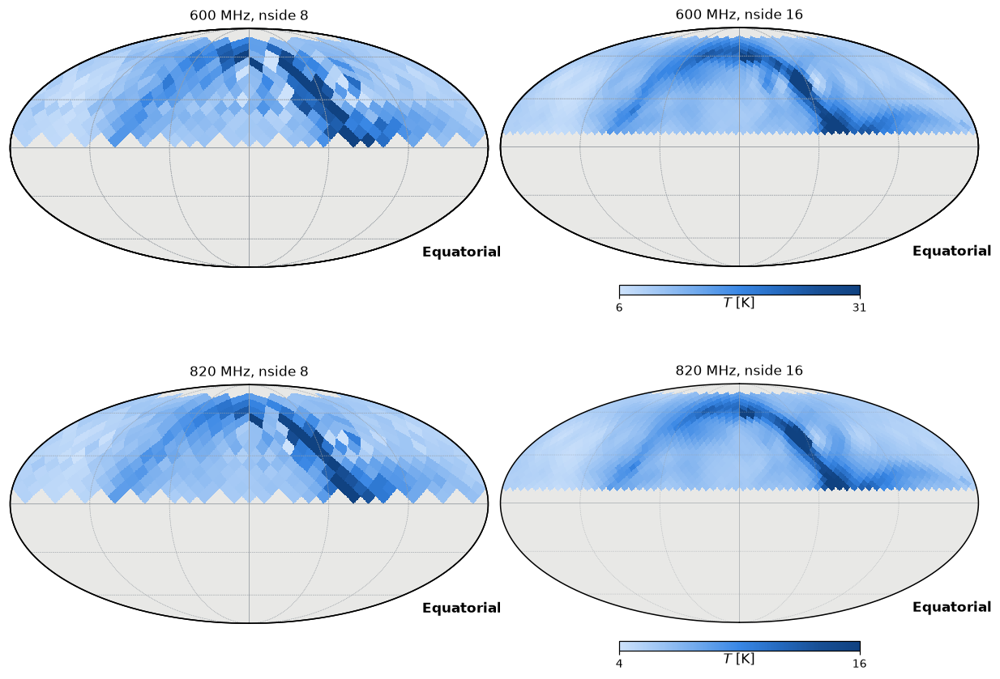


600 MHz                   nside 8    nside 16
pixels retained                344        1272
sky fraction                 0.448       0.414
beam power kept            0.99728     0.99605
zero level [K]             +1.7385     +1.7369
zero level sigma            0.0825      0.0428
reduced chi2                  5.65       16.14
sigma shrinkage              0.874       0.998
pixels tightened               202          23

820 MHz                   nside 8    nside 16
pixels retained                344        1272
sky fraction                 0.448       0.414
beam power kept            0.99728     0.99605
zero level [K]             +0.4836     +0.5158
zero level sigma            0.0527      0.0271
reduced chi2                  2.58        5.88
sigma shrinkage              0.909       0.999
pixels tightened               193           7


In [27]:
# Rows are frequency, columns are grid.  Each ROW carries its own colour scale
# (see above); the two grids within a row share one, which is what makes the
# left-right comparison honest.
fig = plt.figure(figsize=(11, 8))
panel = 1
for freq in (600, 820):
    vlo, vhi = LIMITS[freq]
    for nside, prod in GRIDS.items():
        m = prod["sky_full_k"][prod.index(freq)]
        hp.mollview(m, coord="C", min=vlo, max=vhi, unit="$T$ [K]",
                    title=f"{freq} MHz, nside {nside}", sub=(2, 2, panel),
                    fig=fig.number, cbar=(panel % 2 == 0), **MAP_KW)
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
        panel += 1
plt.show()

for freq in (600, 820):
    print(f"\n{freq} MHz{'':14}{'nside 8':>12}{'nside 16':>12}")
    rows = [
        ("pixels retained",  lambda p: p.diagnostics(freq)["pixel_selection"]["n_pixels"], "{:d}"),
        ("sky fraction",     lambda p: p.diagnostics(freq)["pixel_selection"]["sky_fraction"], "{:.3f}"),
        ("beam power kept",  lambda p: p.diagnostics(freq)["pixel_selection"]["beam_power_retained"], "{:.5f}"),
        ("zero level [K]",   lambda p: p.diagnostics(freq)["zero_level_k"], "{:+.4f}"),
        ("zero level sigma", lambda p: p.diagnostics(freq)["zero_level_sigma_k"], "{:.4f}"),
        ("reduced chi2",     lambda p: p.diagnostics(freq)["reduced_chi_square"], "{:.2f}"),
        ("sigma shrinkage",  lambda p: p.diagnostics(freq)["sigma_shrinkage_median"], "{:.3f}"),
        ("pixels tightened", lambda p: p.diagnostics(freq)["pixels_shrunk_gt_5pct"], "{:d}"),
    ]
    for label, get, fmt in rows:
        print(f"{label:<22}{fmt.format(get(products8)):>12}{fmt.format(get(products)):>12}")

#### Where the annulus sits, and what each grid resolves

The profile below is the one place the two grids can be compared without the eye doing
the work. Declination is the only coordinate the coverage depends on, so a profile
against it says everything about the footprint: where the band starts and stops, and how
sharply.

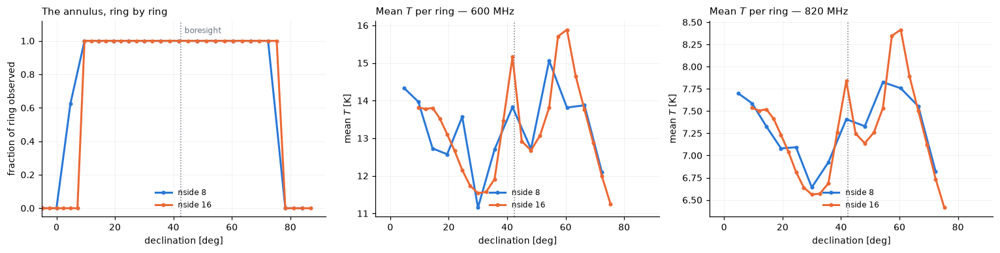

nside  8: band  +4.78 .. +72.39 deg   centre +38.58   offset from boresight -3.85 deg
nside 16: band  +9.59 .. +75.34 deg   centre +42.47   offset from boresight +0.03 deg

mean T over the band at each frequency, and the index between them:
  nside  8: 13.211 K at 600,  7.287 K at 820  ->  beta = -1.926
  nside 16: 13.178 K at 600,  7.247 K at 820  ->  beta = -1.936


In [28]:
# HEALPix pixel centres sit on discrete iso-latitude RINGS, so bin on the rings
# themselves.  Uniform declination bins put zero pixels in some bins at coarse
# nside, which draws holes in a footprint that has none.
def ring_profile(prod, nside, freq):
    m = prod["sky_full_k"][prod.index(freq)]
    # Round BOTH sides before matching: the ring declinations come back with
    # float noise, so comparing raw values against rounded ones matches nothing.
    dec_all = np.round(90 - np.degrees(hp.pix2ang(nside, np.arange(m.size))[0]), 6)
    observed_here = np.isfinite(m)
    rings = np.unique(dec_all)
    frac = np.array([observed_here[dec_all == r].mean() for r in rings])
    mean_t = np.array([np.nanmean(m[(dec_all == r) & observed_here])
                       if (observed_here & (dec_all == r)).any() else np.nan
                       for r in rings])
    return rings, frac, mean_t

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

for nside, prod in GRIDS.items():
    colour = GRID_COLOUR[nside]
    rings, frac, _ = ring_profile(prod, nside, 600)      # coverage is the same
    axes[0].plot(rings, frac, color=colour, lw=2, marker="o", ms=3,
                 label=f"nside {nside}")
    for ax, freq in zip(axes[1:], (600, 820)):
        rings, _, mean_t = ring_profile(prod, nside, freq)
        good = np.isfinite(mean_t)
        ax.plot(rings[good], mean_t[good], color=colour, lw=2, marker="o", ms=3,
                label=f"nside {nside}")

axes[0].set_ylabel("fraction of ring observed")
axes[0].set_ylim(-0.05, 1.12)
axes[0].set_title("The annulus, ring by ring", loc="left")
axes[1].set_ylabel("mean $T$ [K]")
axes[1].set_title("Mean $T$ per ring — 600 MHz", loc="left")
axes[2].set_ylabel("mean $T$ [K]")
axes[2].set_title("Mean $T$ per ring — 820 MHz", loc="left")
for ax in axes:
    ax.set_xlabel("declination [deg]")
    ax.set_xlim(-5, 92)
    ax.grid(alpha=0.18, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="lower center")
    ax.axvline(geometry.boresight_dec_deg, color="#6b7280", ls=":", zorder=0)
axes[0].annotate("boresight", xy=(geometry.boresight_dec_deg, 1.06),
                 xytext=(4, 0), textcoords="offset points", fontsize=8,
                 color="#6b7280", va="center")
fig.tight_layout()
plt.show()

for nside, prod in GRIDS.items():
    dec = 90 - np.degrees(hp.pix2ang(nside, prod.pixel_indices)[0])
    print(f"nside {nside:2d}: band {dec.min():+6.2f} .. {dec.max():+6.2f} deg   "
          f"centre {0.5*(dec.min()+dec.max()):+6.2f}   "
          f"offset from boresight "
          f"{0.5*(dec.min()+dec.max()) - geometry.boresight_dec_deg:+.2f} deg")

print("\nmean T over the band at each frequency, and the index between them:")
for nside, prod in GRIDS.items():
    t6 = np.nanmean(prod["sky_full_k"][prod.index(600)])
    t8 = np.nanmean(prod["sky_full_k"][prod.index(820)])
    beta = np.log(t6 / t8) / np.log(600.5 / 817.8)
    print(f"  nside {nside:2d}: {t6:6.3f} K at 600, {t8:6.3f} K at 820  ->  "
          f"beta = {beta:+.3f}")

---
### Summary

#### 01 — the TRIS rings

* **Two absolute rings**, 120 samples each on a shared, non-uniform RA grid, each with one
  0.000 K row that forces an uncertainty floor.
* **A zero level** that dwarfs the statistical errors and is asymmetric at 820 MHz —
  carried as a nuisance parameter with a 0.5 K symmetric prior, recorded as a decision.
* **A beam from the archive's own cuts**, with real below-horizon response that the
  horizon mask removes. TRIS is the coarsest of the datasets, so its beam sets the common
  resolution everything else is matched to.
* **Rayleigh–Jeans temperatures including the CMB monopole**, settled by the physics
  rather than a header.
* **GSM2008 as prior *and* truth**, measured here as ~1.9 K cold at 600 MHz and ~0.6 K
  cold at 820 MHz. Read the offset as a statement about GSM2008, not about the archive's zero point.

#### 02 — ARCADE 2

The data is there, and three properties of the files decide how it has to be handled:

* **the sky it never saw is stored as exact zero**, with no `UNSEEN` and no `NaN`. The
  mask has to be rebuilt from the zeros, and rebuilt *before* smoothing;
* **`NESTED` at nside 16**, a 3.7° pixel. Coarse next to Haslam's nside 512, though still
  fine against the ~23° beam everything is being smoothed to;
* **no `COORDSYS` in the header**, so the galactic frame assumed in the plots here is
  unconfirmed here (Part B confirms it against the sky).

#### 03 — Haslam 408 MHz

Full sky at nside 512, `RING`, `COORDSYS = GALACTIC`, no sentinels and no zero pixels.
The galactic plane runs to thousands of K, hence the hand-set colour limits. This is the
`res/` copy.

#### 04 — the TRIS maps

Stage 1's products at **nside 16** — coarse on purpose, since the beam is 19–23° — **equatorial**, covering **41.4% of the sky**. Pixels
are selected by **beam response** (kept if the response exceeds 1% of peak at any one
observation), not by a declination cut; that retains 99.60% of the beam power and comes
out as a clean band because the scan covers all RA. `NaN` off-selection, with an explicit
`band_mask` alongside, and a per-pixel posterior σ the SED fit should weight by.

#### What sections 02–04 add up to

The three datasets agree on nothing that matters operationally: three pixelisations (nside 16, 512, 16), three
frames (unstated, galactic, equatorial), and three ways of marking unobserved sky (zeros, nothing, `NaN`). Beam
matching reconciles the pixelisations and the masks; Part B settles the frames against the sky.

---
## 05 — Every map in `res/`, side by side

This section discovers what is in `res/` each time it runs, so a file added there shows up
without editing anything:

* **every `*.fits` HEALPix map** gets one panel. The grid is 2 columns with as many rows as
  the maps need. Each map is drawn in its own declared frame, with this notebook's palette
  (`MAP_KW`), graticule and percentile colour limits, and with unobserved sky in the
  recessive grey;
* **every map is also cut along the TRIS stripe** (where TRIS data exist: stage 1's footprint,
  Dec ≈ +8° to +77°) in a second figure. It is
  the same rectangular plate-carrée slice as the per-map `cartview` panels above, but each
  pixel is looked up at its own RA/Dec, so the vertical axis is truly declination, not
  Galactic latitude. RA increases to the left;
* **every TRIS drift ring** (`TRIS_absolute_*.txt` files that read as rings) becomes a row
  in the table, describing the stage 1 map it turns into. Point sets and the beam profile
  are recognised and listed as skipped.

**How each file is read**, detected from the file itself:

* a standard HEALPix table → `hp.read_map`;
* an image in the FITS-standard **HPX projection** (CHIPASS) → converted back to HEALPix pixel
  for pixel, with a check that the mapping is exactly one-to-one;
* a HEALPix table **without layout keywords** (Rhodes/HartRAO: no `NSIDE`, `ORDERING` or
  column name) → nside from the table size, and RING vs NESTED chosen from the data: the
  ordering in which neighbouring pixels correlate best.

**Where each number comes from**, in order of preference: header keywords (`FREQ`,
`RESTFREQ`, `TUNIT1`/`BUNIT`, `BEAMSIZE`/`BEAMSZ`/`BMAJ`, `COORDSYS`/`SKYCOORD`, the HPX
`CTYPE`), then the header's free-text comments (e.g. `Coordinate system - Equatorial`), then
the filename for the frequency, then `EXTERNAL_METADATA` below, with its source. Anything
still unknown prints as `?`. **A plane check runs on every map**: the brightest pixels,
read in the stated frame, should lie on b ≈ 0. A large value means the frame is wrong.

**Unobserved sky** is detected from the data: NaN, any value below −10²⁰ (`hp.UNSEEN`,
CHIPASS's −1.0e30 / −1.1e30), the FITS null −32768, the header's `TNULL` value, and exact
zeros once they cover more than 1% of the sky (ARCADE 2's convention).

**CMB.** Section 06 compares temperatures with the CMB removed, and the surveys differ:
most include it, Rhodes/HartRAO has it removed (measured: 0.17 K at |b| > 40°), and WMAP's
foreground-cleaned map *is* CMB anisotropy, with the monopole removed. Each map carries a
`cmb` flag saying which.

**The TRIS stripe** is overlaid in orange. It is where TRIS data exist: stage 1's footprint,
every pixel the beam reaches (Dec ≈ +8° to +77° at nside 16). The boresight, Dec +42.4°,
is dashed. The edges are computed from the stage 1 product, so they follow `tris.nside`.
The stripe is drawn in each map's own frame, so on Galactic maps it appears curved.
(Section 04's cartviews use a narrower Dec +30° to +55° window.)

In [29]:
import re
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
import astropy.units as u

FITS_NULL = -32768.0
SENTINEL_BELOW = -1e20            # hp.UNSEEN (-1.6375e30) and CHIPASS's -1.0e30 / -1.1e30
ZERO_AS_MASK_FRACTION = 0.01      # exact zeros over >1% of the sky are a mask, not sky
UNIT_TO_KELVIN = {"K": 1.0, "KELVIN": 1.0, "KELVINS": 1.0, "MK": 1e-3}
FRAME_WORDS = {"G": "G", "GAL": "G", "GALACTIC": "G", "C": "C", "Q": "C", "EQ": "C",
               "EQUATORIAL": "C", "CELESTIAL": "C", "E": "E", "ECLIPTIC": "E"}

# Facts the files do not carry themselves, keyed by filename, each with its source.
# cmb: "included" (subtract it), "removed" (already gone), "anisotropy" (CMB-only map,
# no foreground to compare).  A file missing from here is still read and plotted; the
# table shows "?" for what it lacks, and section 06 assumes the CMB is included.
EXTERNAL_METADATA = {
    "HASLAM.fits": dict(name="Haslam 408 MHz", cmb="included",
                        source="CMB included: config haslam.remove_cmb_monopole"),
    "HASLAM_DESTRIPED_ONLY.fits": dict(
        name="Haslam 408 MHz, destriped only", cmb="included",
        source="Remazeilles et al. 2015, destriped but not desourced"),
    "MAIPU_45mhZ.fits": dict(
        name="Maipu + MU 45 MHz", unit="K", fwhm="4.6° × 2.4° (Maipu) / 3.6° (MU)",
        cmb="included", source="LAMBDA fg_maipu_info; Guzmán et al. 2011"),
    "LWA_35MHz.fits": dict(name="LWA1 35 MHz", frame="C", cmb="included",
                           source="LAMBDA fg_lwa1_radio_maps_info: Equatorial; Dowell et al. 2017"),
    "LWA_80MHz.fits": dict(name="LWA1 80 MHz", frame="C", cmb="included",
                           source="LAMBDA fg_lwa1_radio_maps_info: Equatorial; Dowell et al. 2017"),
    "STOCKERT_VILLA_1400MHZ.fits": dict(
        name="Stockert + Villa-Elisa 1420 MHz", unit="mK", freq_mhz=1420.0, fwhm="35.4′",
        cmb="included", source="LAMBDA fg_stockert_villa_info; Reich 1982, Testori et al. 2001"),
    "CHIPASS_1400MHz.fits": dict(
        name="CHIPASS 1400 MHz", unit="mK", fwhm="14.4′", cmb="included",
        source="LAMBDA fg_chipass_info; Calabretta et al. 2014. CMB measured as included "
               "(matches Stockert to +0.01 K), whatever the page summary says"),
    "RHODES_HARTRAO_2326MHz.fits": dict(
        name="Rhodes/HartRAO 2326 MHz", cmb="removed",
        source="Jonas et al. 1998, Platania et al. 2003 (header). CMB measured as removed "
               "(0.17 K at |b| > 40°)"),
    "ARCADE2_315.fits": dict(name="ARCADE 2 3.15 GHz", unit="K", thermodynamic=True,
                             cmb="included", source="LAMBDA arcade_maps_info (K thermodynamic)"),
    "ARCADE2_341.fits": dict(name="ARCADE 2 3.41 GHz", unit="K", thermodynamic=True,
                             cmb="included", source="LAMBDA arcade_maps_info (K thermodynamic)"),
    "WMAP_Q_BAND.fits": dict(
        name="WMAP Q band, foreground-cleaned", freq_mhz=40700.0, fwhm="0.49°", frame="G",
        thermodynamic=True, cmb="anisotropy",
        source="WMAP 9-yr: Q band 40.7 GHz, 0.49° beam, Galactic, mK thermodynamic; "
               "foreground-cleaned, monopole removed"),
}

def header_text(path):
    # All keywords (later HDUs win) and all COMMENT/HISTORY lines, from every HDU.
    keys, lines = {}, []
    with fits.open(path, memmap=True) as hdul:
        for hdu in hdul:
            for k in hdu.header:
                if k in ("COMMENT", "HISTORY"):
                    continue
                keys[k] = hdu.header[k]
            lines += [str(c) for c in hdu.header.get("COMMENT", [])]
            lines += [str(c) for c in hdu.header.get("HISTORY", [])]
    return keys, lines

def comment_value(lines, label):
    # "Frequency - 2326 MHz"-style free text in the header comments.
    for line in lines:
        hit = re.match(rf"\s*{label}\s*[-:=]\s*(.+)", line, flags=re.I)
        if hit:
            return hit.group(1).strip()
    return None

def neighbour_corr(m, nside, nest):
    nb_ = hp.get_all_neighbours(nside, np.arange(m.size), nest=nest)[0]
    ok = (nb_ >= 0) & np.isfinite(m) & np.isfinite(m[nb_]) & (m != 0) & (m[nb_] != 0)
    return np.corrcoef(m[ok], m[nb_[ok]])[0, 1]

def read_sky(path):
    # Returns (RING map as float, nside, how it was read, frame hint, frame-hint source).
    with fits.open(path, memmap=True) as hdul:
        h0 = hdul[0].header
        ctype = str(h0.get("CTYPE1", ""))
        if h0.get("NAXIS", 0) == 2 and ctype.endswith("-HPX"):
            img, wcs = np.asarray(hdul[0].data, dtype=float), WCS(h0)
            nside = img.shape[1] // 5                    # the HPX layout is 5 nside wide
            lon, lat = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)), lonlat=True)
            x, y = wcs.world_to_pixel_values(lon, lat)
            xi, yi = np.rint(x).astype(int), np.rint(y).astype(int)
            assert np.unique(yi * img.shape[1] + xi).size == xi.size, \
                f"{path.name}: HPX image is not a one-to-one HEALPix layout"
            hint = {"GLON": "G", "RA--": "C", "ELON": "E"}.get(ctype[:4])
            return img[yi, xi], nside, "HPX image → HEALPix, 1:1", hint, f"CTYPE1 {ctype}"
        tables = [i for i, h in enumerate(hdul) if isinstance(h, fits.BinTableHDU)]
        if not tables:
            raise ValueError(f"{path.name}: neither a HEALPix table nor an HPX image")
        t = tables[0]
        th = hdul[t].header
        if "NSIDE" in th and th.get("TTYPE1"):
            sky = hp.read_map(path, field=0, hdu=t, dtype=np.float64)
            return sky, hp.get_nside(sky), f"HEALPix table, {str(th.get('ORDERING', '?')).strip()}", None, None
        # A HEALPix table without layout keywords: size gives nside, the data give order.
        assert str(th["TFORM1"]).strip().endswith("E"), f"{path.name}: unexpected TFORM1"
        repeat = int(re.match(r"\s*(\d*)", str(th["TFORM1"])).group(1) or 1)
        npix = int(th["NAXIS2"]) * repeat
        offset = hdul.fileinfo(t)["datLoc"]
    raw = np.fromfile(path, dtype=">f4", count=npix, offset=offset).astype(float)
    nside = hp.npix2nside(npix)
    r, n = neighbour_corr(raw, nside, False), neighbour_corr(raw, nside, True)
    sky = raw if r >= n else hp.reorder(raw, n2r=True)
    how = f"table w/o layout keys; {'RING' if r >= n else 'NESTED'} from data ({max(r, n):.2f} vs {min(r, n):.2f})"
    return sky, nside, how, None, None

def frequency_mhz(keys, lines, filename):
    for key, scale in (("FREQ", None), ("RESTFREQ", 1e-6), ("FREQUENC", None)):
        if key in keys:
            text = str(keys[key]).strip()
            hit = re.match(r"([\d.]+(?:[eE][+-]?\d+)?)", text)
            if hit:
                value = float(hit.group(1))
                if scale:
                    return value * scale, f"header {key}"
                return value * (1e3 if "GHZ" in text.upper() else 1.0), f"header {key}"
    text = comment_value(lines, "Frequency")
    if text:
        hit = re.match(r"([\d.]+)\s*(MHZ|GHZ)", text.upper())
        if hit:
            return float(hit.group(1)) * (1e3 if hit.group(2) == "GHZ" else 1.0), "header comment"
    hit = re.search(r"(\d+(?:\.\d+)?)\s*(MHZ|GHZ)", filename.upper())
    if hit:
        return float(hit.group(1)) * (1e3 if hit.group(2) == "GHZ" else 1.0), "filename"
    return None, None

def beam_fwhm(keys, lines):
    if "BEAMSIZE" in keys:                              # Haslam: arcmin
        return f"{float(keys['BEAMSIZE']):.0f}′", "header BEAMSIZE"
    if "BEAMSZ" in keys:                                # ARCADE 2: degrees
        return f"{float(keys['BEAMSZ']):.1f}°", "header BEAMSZ"
    if "BMAJ" in keys:                                  # LWA1: degrees
        bmin = keys.get("BMIN", keys["BMAJ"])
        text = (f"{float(keys['BMAJ']):.2f}°" if float(bmin) == float(keys["BMAJ"])
                else f"{float(keys['BMAJ']):.2f}° × {float(bmin):.2f}°")
        return text, "header BMAJ/BMIN"
    text = comment_value(lines, "Resolution")
    if text:
        return text, "header comment"
    return None, None

def map_unit(keys, lines):
    for key in ("TUNIT1", "BUNIT"):
        if str(keys.get(key, "")).strip():
            return str(keys[key]).strip(), f"header {key}"
    text = comment_value(lines, "Pixel Units")
    return (text, "header comment") if text else (None, None)

def map_frame(keys, lines, hint, hint_src):
    for key in ("COORDSYS", "SKYCOORD"):
        if key in keys:
            word = str(keys[key]).strip().upper()
            return FRAME_WORDS.get(word, FRAME_WORDS.get(word[:1])), f"header {key}"
    if hint:
        return hint, hint_src
    text = comment_value(lines, "Coordinate system")
    if text and text.upper() in FRAME_WORDS:
        return FRAME_WORDS[text.upper()], "header comment"
    return None, None

def unobserved_mask(sky, keys):
    mask = ~np.isfinite(sky) | (sky < SENTINEL_BELOW) | (sky == FITS_NULL)
    if "TNULL1" in keys and float(keys["TNULL1"]) != 0.0:
        mask |= sky == float(keys["TNULL1"])
    zeros = sky == 0
    if zeros.mean() > ZERO_AS_MASK_FRACTION or keys.get("TNULL1") == 0:
        mask |= zeros
    return mask

def plane_check(sky, nside, frame):
    # Median |b| of the brightest 0.5% of observed pixels, read in the stated frame.
    good = np.flatnonzero(np.isfinite(sky))
    top = good[np.argsort(sky[good])[-max(50, good.size // 200):]]
    theta, phi = hp.pix2ang(nside, top)
    if frame and frame != "G":
        theta, phi = hp.Rotator(coord=[frame, "G"])(theta, phi)
    return float(np.median(np.abs(90.0 - np.degrees(theta))))

def describe(path):
    keys, lines = header_text(path)
    extra = EXTERNAL_METADATA.get(path.name, {})
    sky, nside, how, hint, hint_src = read_sky(path)

    freq, freq_src = frequency_mhz(keys, lines, path.name)
    if freq is None and "freq_mhz" in extra:
        freq, freq_src = extra["freq_mhz"], "external"
    elif freq is not None and "freq_mhz" in extra and abs(extra["freq_mhz"] - freq) > 1:
        freq, freq_src = extra["freq_mhz"], f"external ({freq_src} says {freq:g})"
    unit, unit_src = map_unit(keys, lines)
    if unit is None and "unit" in extra:
        unit, unit_src = extra["unit"], "external"
    fwhm, fwhm_src = beam_fwhm(keys, lines)
    if fwhm is None and "fwhm" in extra:
        fwhm, fwhm_src = extra["fwhm"], "external"
    frame, frame_src = map_frame(keys, lines, hint, hint_src)
    if frame is None and "frame" in extra:
        frame, frame_src = extra["frame"], "external"

    masked = unobserved_mask(sky, keys)
    scale = UNIT_TO_KELVIN.get(str(unit).upper()) if unit else None
    shown = np.where(masked, np.nan, sky * (scale if scale else 1.0))
    used_external = any("external" in (s or "") for s in (freq_src, unit_src, fwhm_src, frame_src))
    return dict(file=path.name, name=extra.get("name", path.stem), freq_mhz=freq,
                nside=nside, how=how, frame=frame, frame_src=frame_src, unit=unit,
                in_kelvin=scale is not None, fwhm=fwhm, fwhm_src=fwhm_src, freq_src=freq_src,
                unit_src=unit_src, cmb=extra.get("cmb", "included"),
                thermodynamic=extra.get("thermodynamic", False),
                external=extra.get("source") if (used_external or "cmb" in extra) else None,
                n_unobserved=int(masked.sum()), sky=shown,
                plane_b=plane_check(shown, nside, frame))

MAPS = sorted((describe(p) for p in sorted(RES.glob("*.fits"))),
              key=lambda m: (m["freq_mhz"] is None, m["freq_mhz"] or 0.0))

# The TRIS products: classify each text file by trying to read it as a ring.
TRIS_RINGS, SKIPPED = [], []
for path in sorted(RES.glob("TRIS_*.txt")):
    try:
        ring = tris.read_tris_ring(path)
        TRIS_RINGS.append((path.name, ring))
    except Exception as err:
        SKIPPED.append((path.name, type(err).__name__))

print(f"res/: {len(MAPS)} HEALPix maps, {len(TRIS_RINGS)} TRIS rings, "
      f"{len(SKIPPED)} other TRIS files skipped")
print(f"  {'file':<30}{'nside':>6}  {'read as':<44}{'frame':>6}{'unit':>6}{'unobserved':>12}"
      f"{'plane |b|':>11}  cmb")
for m in MAPS:
    print(f"  {m['file']:<30}{m['nside']:6d}  {m['how']:<44}{m['frame'] or '?':>6}"
          f"{m['unit'] or '?':>6}{m['n_unobserved']:12d}{m['plane_b']:10.1f}°  {m['cmb']}")
for name, ring in TRIS_RINGS:
    print(f"  {name:<30} ring: {ring.ra_deg.size} samples, ν_eff {ring.effective_frequency_mhz:.1f} MHz")
for name, why in SKIPPED:
    print(f"  {name:<30} not a ring ({why}) -- skipped")
for m in MAPS:
    if m["frame"] is None:
        print(f"WARNING: {m['file']} states no frame and has none in EXTERNAL_METADATA; drawn as Galactic")
    elif m["plane_b"] > 15 and m["cmb"] != "anisotropy":
        print(f"WARNING: {m['file']}: brightest pixels sit {m['plane_b']:.0f}° off the plane in the "
              f"stated frame ({m['frame']}, {m['frame_src']}) -- the frame is probably wrong")

res/: 21 HEALPix maps, 2 TRIS rings, 2 other TRIS files skipped
  file                           nside  read as                                      frame  unit  unobserved  plane |b|  cmb
  LWA_35MHz.fits                   256  HEALPix table, RING                              C     K      140800       1.9°  included
  LWA1_38.fits                     256  HEALPix table, RING                              ?     K      140800      28.1°  included
  LWA1_40.fits                     256  HEALPix table, RING                              ?     K      140800      28.5°  included
  LWA1_45.fits                     256  HEALPix table, RING                              ?     K      140800      27.8°  included
  MAIPU_45mhZ.fits                  64  HEALPix table, NESTED                            G     K        1877       1.5°  included
  LWA1_50.fits                     256  HEALPix table, RING                              ?     K      140800      26.9°  included
  LWA1_60.fits                 

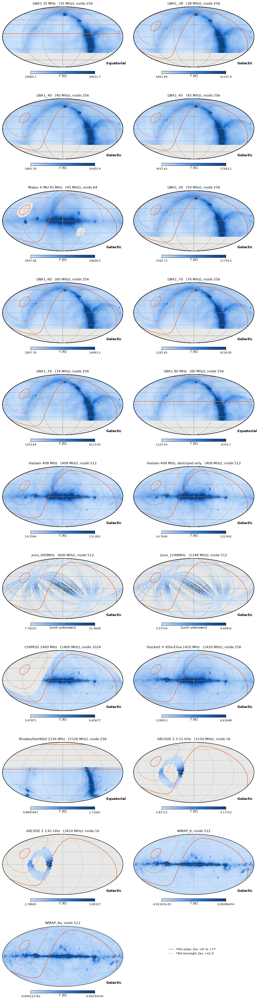

In [30]:
# The TRIS stripe: where TRIS data exist (stage 1's footprint), from edge to edge.
_band = stage1.load_stage1(config)["band_mask"].astype(bool)
_band_nside = hp.npix2nside(_band.size)
_, _band_dec = hp.pix2ang(_band_nside, np.flatnonzero(_band), lonlat=True)
_half_pixel = hp.nside2resol(_band_nside, arcmin=True) / 120.0
TRIS_STRIP_DEC = (float(_band_dec.min() - _half_pixel), float(_band_dec.max() + _half_pixel))
TRIS_BORESIGHT_DEC = tris.TRIS_SITE_LATITUDE_DEG
STRIP_COLOUR = "#eb6834"
ASTROPY_FRAME = {"G": "galactic", "C": "icrs", "E": "barycentrictrueecliptic"}

def draw_dec_line(dec_deg, frame, **kw):
    # A line of constant declination in the map's own frame.  Split it wherever it wraps
    # across the lon = 180° edge, or it streaks across the whole map.
    ra = np.linspace(0.0, 360.0, 1441)
    coords = SkyCoord(ra=ra * u.deg, dec=np.full(ra.size, dec_deg) * u.deg)
    coords = coords.transform_to(ASTROPY_FRAME[frame]).spherical
    lon = (coords.lon.deg + 180.0) % 360.0 - 180.0
    breaks = np.flatnonzero(np.abs(np.diff(lon)) > 180.0) + 1
    for lon_seg, lat_seg in zip(np.split(lon, breaks), np.split(coords.lat.deg, breaks)):
        hp.projplot(lon_seg, lat_seg, lonlat=True, **kw)

N_COLS = 2
n_rows = int(np.ceil(len(MAPS) / N_COLS))
fig = plt.figure(figsize=(6 * N_COLS, 4.2 * n_rows))
for k, m in enumerate(MAPS):
    frame = m["frame"] or "G"
    lo, hi = np.nanpercentile(m["sky"], [2, 98])     # percentile limits, as everywhere here
    unit = "$T$ [K]" if m["in_kelvin"] else f"[{m['unit'] or 'unit unknown'}]"
    freq = "" if m["freq_mhz"] is None else f"   ({m['freq_mhz']:g} MHz)"
    hp.mollview(m["sky"], coord=frame, sub=(n_rows, N_COLS, k + 1), fig=fig.number,
                min=lo, max=hi, unit=unit, title=f"{m['name']}{freq}, nside {m['nside']}",
                **MAP_KW)
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
    for dec in TRIS_STRIP_DEC:
        draw_dec_line(dec, frame, color=STRIP_COLOUR)
    draw_dec_line(TRIS_BORESIGHT_DEC, frame, color=STRIP_COLOUR, ls="--")

handles = [plt.Line2D([], [], color=STRIP_COLOUR),
           plt.Line2D([], [], color=STRIP_COLOUR, ls="--")]
labels = [f"TRIS stripe, Dec {TRIS_STRIP_DEC[0]:+.0f}° to {TRIS_STRIP_DEC[1]:+.0f}°",
          f"TRIS boresight, Dec +{TRIS_BORESIGHT_DEC:.1f}°"]
if len(MAPS) % N_COLS:          # an empty last slot: put the legend there
    fig.legend(handles, labels, loc="center",
               bbox_to_anchor=(0.75, 0.5 / n_rows))
else:
    fig.legend(handles, labels, loc="lower center", ncol=2)
plt.show()

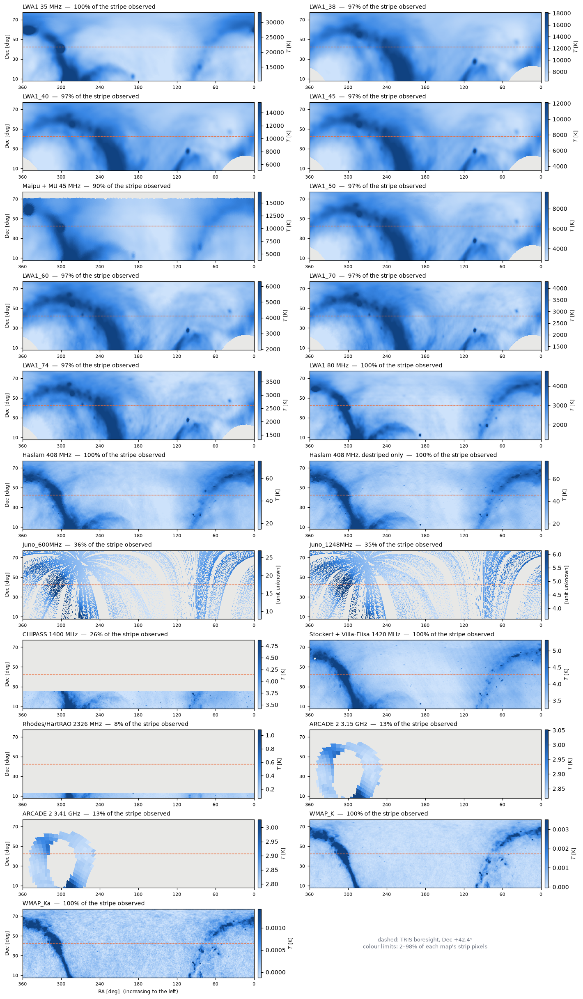

In [31]:
# The TRIS stripe, cut out of every map as a rectangular RA/Dec slice: the same plate-carrée
# view as the per-map cartview panels above, but sampled pixel by pixel at each RA/Dec,
# so latra really is declination, and drawn on axes that show RA and Dec.
STRIP_RA = np.linspace(360.0, 0.0, 1801)                 # left -> right: RA decreasing
STRIP_DEC = np.linspace(TRIS_STRIP_DEC[0], TRIS_STRIP_DEC[1], 281)

def strip_image(m):
    ra2d, dec2d = np.meshgrid(STRIP_RA, STRIP_DEC)
    theta, phi = np.radians(90.0 - dec2d).ravel(), np.radians(ra2d).ravel()
    frame = m["frame"] or "G"
    if frame != "C":
        theta, phi = hp.Rotator(coord=["C", frame])(theta, phi)   # RA/Dec -> map frame
    pix = hp.ang2pix(m["nside"], theta, phi)                       # nearest pixel, as cartview
    return m["sky"][pix].reshape(ra2d.shape)

slice_cmap = SEQ.copy()
slice_cmap.set_bad(MAP_KW["badcolor"])     # unobserved: the notebook's recessive grey
# SEQ paints values below vmin WHITE (healpy needs that for its page background). On a
# slice that turns the coldest 2% of sky into fake holes, so clip to the ramp's ends here.
slice_cmap.set_under(SEQ(0.0))
slice_cmap.set_over(SEQ(1.0))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(6.4 * N_COLS, 2.0 * n_rows),
                         squeeze=False, constrained_layout=True)
for ax, m in zip(axes.flat, MAPS):
    img = strip_image(m)
    seen = np.isfinite(img)
    lo, hi = (np.percentile(img[seen], [2, 98]) if seen.any() else (0.0, 1.0))
    im = ax.imshow(np.ma.masked_invalid(img), origin="lower", aspect="auto", cmap=slice_cmap,
                   vmin=lo, vmax=hi, interpolation="nearest",
                   extent=[STRIP_RA[0], STRIP_RA[-1], STRIP_DEC[0], STRIP_DEC[-1]])
    ax.axhline(TRIS_BORESIGHT_DEC, color=STRIP_COLOUR, ls="--")
    ax.set_xticks(np.arange(360, -1, -60)); ax.set_yticks(np.arange(10, 80, 20))
    ax.set_title(f"{m['name']}  —  {100 * seen.mean():.0f}% of the stripe observed",
                 loc="left")
    unit = "$T$ [K]" if m["in_kelvin"] else f"[{m['unit'] or 'unit unknown'}]"
    fig.colorbar(im, ax=ax, pad=0.01, fraction=0.04).set_label(unit)
for ax in axes[-1]:
    ax.set_xlabel("RA [deg]  (increasing to the left)")
for ax in axes[:, 0]:
    ax.set_ylabel("Dec [deg]")
for ax in axes.flat[len(MAPS):]:
    ax.axis("off")
    ax.text(0.5, 0.5, f"dashed: TRIS boresight, Dec +{TRIS_BORESIGHT_DEC:.1f}°\n"
            "colour limits: 2–98% of each map's strip pixels",
            ha="center", va="center", fontsize=8.5, color="#6b7280", transform=ax.transAxes)
plt.show()

#### Frequencies, grids and beams

* **Beam nside.** Only TRIS has a beam that is a HEALPix map. limTOD builds it from the
  archive cuts at the map's nside, then up-samples it to `tris.nside_hires` (the `→`
  value). Every other survey publishes its beam as a FWHM only, so its beam nside and
  beam resolution are `—`.
* **Frame** is each map's own coordinate system, and where it was found: a keyword
  (`COORDSYS`, or ARCADE 2's `SKYCOORD`, which healpy does not read), the HPX `CTYPE`, a
  header comment, or `EXTERNAL_METADATA` (the LWA1 maps declare none). The TRIS stage 1
  maps store no frame at all: they are equatorial by construction.
* **Resolution.** "Res." is the HEALPix pixel size, `hp.nside2resol(nside)`, of that grid.
* **The TRIS rows** describe the stage 1 maps the rings turn into. The files in `res/` are
  the rings themselves.

In [32]:
def pixel_deg(nside):
    return hp.nside2resol(nside, arcmin=True) / 60.0

def fmt_deg(d):
    return f"{d * 60:.1f}′" if d < 1 else f"{d:.2f}°"

FRAME_NAME = {"G": "Galactic", "C": "Equatorial", "E": "Ecliptic"}

def frame_label(code, source):
    return f"{FRAME_NAME.get(code, '?')} ({source})" if code else "? (not stated)"

rows = [dict(freq=m["freq_mhz"], name=m["name"], beam_nside=None, nside=m["nside"],
             frame=frame_label(m["frame"], m["frame_src"]),
             fwhm=m["fwhm"], fwhm_src=m["fwhm_src"],
             note=m["external"] or "") for m in MAPS]

if TRIS_RINGS:
    beam_cut_files = sorted(RES.glob("TRIS_Beam_Profile*.txt"))
    if beam_cut_files:
        e_hpbw, h_hpbw = tris.read_tris_beam_cuts(beam_cut_files[0]).half_power_full_width_deg()
        tris_fwhm, tris_src = f"{e_hpbw:.2f}° (E) × {h_hpbw:.2f}° (H)", beam_cut_files[0].name
    else:
        tris_fwhm, tris_src = None, None
    tris_nside = int(config.require("tris.nside"))
    hires = int(config.require("tris.nside_hires"))
    for name, ring in TRIS_RINGS:
        nominal = re.search(r"(\d+)", name)          # the file's nominal label, e.g. 820
        label = nominal.group(1) if nominal else f"{ring.effective_frequency_mhz:.0f}"
        rows.append(dict(freq=ring.effective_frequency_mhz,
                         name=f"TRIS {label} MHz (stage 1 map)",
                         beam_nside=(tris_nside, hires), nside=tris_nside,
                         frame=frame_label("C", "by construction, not stored"), fwhm=tris_fwhm,
                         fwhm_src=tris_src, note=f"from {name}; nside = tris.nside"))
rows.sort(key=lambda r: (r["freq"] is None, r["freq"] or 0.0))

header = (f"{'freq [MHz]':>10}  {'map':<34}{'frame (from)':<40}{'beam nside':>11}{'map nside':>10}"
          f"{'beam res.':>11}{'beam width (FWHM)':>32}{'map res.':>10}   beam width from")
print(header)
print("-" * len(header))
for r in rows:
    freq = "?" if r["freq"] is None else f"{r['freq']:.1f}"
    beam_nside = "—" if r["beam_nside"] is None else f"{r['beam_nside'][0]} (→{r['beam_nside'][1]})"
    beam_res = "—" if r["beam_nside"] is None else fmt_deg(pixel_deg(r["beam_nside"][0]))
    print(f"{freq:>10}  {r['name']:<34}{r['frame']:<40}{beam_nside:>11}{r['nside']:>10}{beam_res:>11}"
          f"{r['fwhm'] or '?':>32}{fmt_deg(pixel_deg(r['nside'])):>10}   "
          f"{r['fwhm_src'] or '?'}")
notes = [(r["name"], r["note"]) for r in rows if r["note"]]
if notes:
    print("\nnot in the file itself:")
    for name, note in notes:
        print(f"  {name:<34} {note}")

freq [MHz]  map                               frame (from)                             beam nside map nside  beam res.               beam width (FWHM)  map res.   beam width from
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
      35.0  LWA1 35 MHz                       Equatorial (external)                             —       256          —                           4.65°     13.7′   header BMAJ/BMIN
      38.0  LWA1_38                           ? (not stated)                                    —       256          —                           4.28°     13.7′   header BMAJ/BMIN
      40.0  LWA1_40                           ? (not stated)                                    —       256          —                           4.07°     13.7′   header BMAJ/BMIN
      45.0  LWA1_45                           ? (not stated)                                    —     

---
## 06 — The TRIS TOD each map predicts

Every map in `res/`, the ones section 05 discovered, is observed the way TRIS observed the
sky. limTOD's own simulator, `generate_TOD_sky`, sweeps the TRIS beam across each map and
returns the time-ordered data (TOD) that map predicts at each of the ring's 120 samples.
This is the same forward model section 01 used for GSM2008, applied to the real surveys.
Comparing the TODs puts every survey on the one footing TRIS itself provides.

**Stage 1's forward model, so the comparison is like-for-like with the map-maker:**

* **Geometry:** TRIS zenith geometry at the ring's own RA samples (Dec +42.4°, E plane
  rolled 7°). limTOD's simulator points the beam in the equatorial frame, so each map is
  rotated Galactic → equatorial first.
* **Grid:** the sky on the stage 1 grid, nside `tris.nside` (16).
* **Beam:** built from the archive's E/H cuts at that nside, up-sampled to
  `tris.nside_hires`, with the horizon mask. This is the same beam stage 1 uses,
  including its pixel-sized blocks (see the "how is the TRIS beam resolution decided"
  discussion). `TOD_NSIDE` below changes the grid in one place.

**Partial maps.** ARCADE 2, and the blank caps in Maipu and Stockert, are handled with two
simulator runs per map: one on the masked sky with the unobserved pixels at zero, and one
on the observed-fraction map. The ratio is the beam average over **observed** sky only,
and the second run is each sample's **coverage**: the fraction of the beam that landed on
observed sky. Samples with coverage below `MIN_COVERAGE` = 0.5, the same majority rule as
stage 2's weight floor, are drawn dotted and left out of the comparisons. The TRIS beam
is wider than ARCADE 2's observed ring, so ARCADE 2 never gets above about 65% coverage.
Its TODs are therefore **partial-beam** averages, usable only across the stretch of RA where
its ring crosses the TRIS beam's path (Dec ≈ +42°).

**Units, for the comparisons.** Each TOD is first plotted in its map's own temperature.
To compare across frequencies, the CMB is removed in Rayleigh-Jeans terms, according to
each map's `cmb` flag from section 05:

* **included**: $T - T_{\mathrm{CMB,RJ}}(\nu)$, or $T_A(T) - T_A(T_0)$ for a thermodynamic map
  (ARCADE 2);
* **removed** (Rhodes/HartRAO): used as it is;
* **anisotropy** (WMAP's foreground-cleaned map): plotted, but left out of the comparisons,
  since it has no foreground to compare.

A map is also left out of the comparisons if no sample reaches `MIN_COVERAGE`: a survey
that stops short of the TRIS beam's path cannot be compared with it. The comparison cell says
which maps were left out and why. The TRIS rings are the real data at 600.5 and 817.8 MHz,
and they are drawn as the reference.

In [33]:
from limTOD import generate_TOD_sky

TOD_NSIDE = int(config.require("tris.nside"))          # stage 1's grid
TOD_NSIDE_HIRES = int(config.require("tris.nside_hires"))
DEGRADE_FIRST = 64        # bring big maps to this nside before rotating (speed only)
# A sample is compared only if at least half the beam fell on observed sky: the same
# majority rule as stage 2's weight floor.  ARCADE 2 never exceeds ~0.65 -- the TRIS beam
# is wider than its observed ring -- so a stricter cut would leave it with nothing.
MIN_COVERAGE = 0.5

ref_name, REF_RING = TRIS_RINGS[0]                     # both rings share one RA grid
GEOM = tris.tris_zenith_geometry(REF_RING.ra_deg)
TOD_RA = np.asarray(REF_RING.ra_deg)
BEAM_TOD = tris.tris_cut_beam_map(tris.read_tris_beam_cuts(RES / "TRIS_Beam_Profile.txt"),
                                  nside=TOD_NSIDE, normalization="peak")
HORIZON_TOD = tris.tris_horizon_mask(TOD_NSIDE)

def observe(sky_eq):
    # One limTOD sweep of the TRIS beam over an equatorial map.
    return np.asarray(generate_TOD_sky(
        BEAM_TOD, sky_eq, GEOM.lst_deg, GEOM.latitude_deg, GEOM.azimuth_deg,
        GEOM.elevation_deg, GEOM.selfrot_deg, nside_hires=TOD_NSIDE_HIRES,
        normalize_beam=True, horizontal_mask=HORIZON_TOD))

def equatorial_pair(m):
    # (sum of observed values, observed fraction) per TOD_NSIDE pixel, in equatorial.
    observed = np.isfinite(m["sky"])
    filled, weight = np.where(observed, m["sky"], 0.0), observed.astype(float)
    if m["nside"] > DEGRADE_FIRST:                      # mean over children, zeros included
        filled, weight = hp.ud_grade(filled, DEGRADE_FIRST), hp.ud_grade(weight, DEGRADE_FIRST)
    frame = m["frame"] or "G"
    if frame != "C":
        rot = hp.Rotator(coord=[frame, "C"])
        filled, weight = rot.rotate_map_pixel(filled), rot.rotate_map_pixel(weight)
    return hp.ud_grade(filled, TOD_NSIDE), hp.ud_grade(weight, TOD_NSIDE)

def rj_excess(t_k, m):
    # Rayleigh-Jeans temperature with the CMB removed, per the map's own cmb flag.
    nu = m["freq_mhz"]
    if m["cmb"] == "removed":
        return t_k
    if m["thermodynamic"]:                                       # e.g. ARCADE 2
        x = lambda t: (6.62607015e-34 * nu * 1e6) / (1.380649e-23 * t)
        t_a = lambda t: t * x(t) / np.expm1(x(t))
        return t_a(t_k) - t_a(2.72548)
    return t_k - tris.cmb_monopole_rj_k(nu)

TODS = {}
for m in MAPS:
    if not m["in_kelvin"] or m["freq_mhz"] is None:
        print(f"{m['name']}: unit or frequency unknown -- simulated but not compared")
    filled, weight = equatorial_pair(m)
    summed, coverage = observe(filled), observe(weight)
    with np.errstate(invalid="ignore", divide="ignore"):
        tod = np.where(coverage > 0, summed / coverage, np.nan)
    TODS[m["name"]] = dict(map=m, tod=tod, coverage=coverage,
                           good=coverage >= MIN_COVERAGE)
    print(f"{m['name']:<34} coverage {coverage.min():.3f}–{coverage.max():.3f}; "
          f"{int((coverage >= MIN_COVERAGE).sum()):3d}/{coverage.size} samples ≥ {MIN_COVERAGE}")

LWA1 35 MHz                        coverage 1.000–1.000; 120/120 samples ≥ 0.5


LWA1_38                            coverage 0.970–1.000; 120/120 samples ≥ 0.5


LWA1_40                            coverage 0.970–1.000; 120/120 samples ≥ 0.5


LWA1_45                            coverage 0.970–1.000; 120/120 samples ≥ 0.5


Maipu + MU 45 MHz                  coverage 0.996–0.996; 120/120 samples ≥ 0.5


LWA1_50                            coverage 0.970–1.000; 120/120 samples ≥ 0.5


... (11 outputs left out)

ARCADE 2 3.15 GHz                  coverage 0.000–0.638;  16/120 samples ≥ 0.5


ARCADE 2 3.41 GHz                  coverage 0.000–0.648;  17/120 samples ≥ 0.5
WMAP_K: unit or frequency unknown -- simulated but not compared


WMAP_K                             coverage 1.000–1.000; 120/120 samples ≥ 0.5
WMAP_Ka: unit or frequency unknown -- simulated but not compared


WMAP_Ka                            coverage 1.000–1.000; 120/120 samples ≥ 0.5


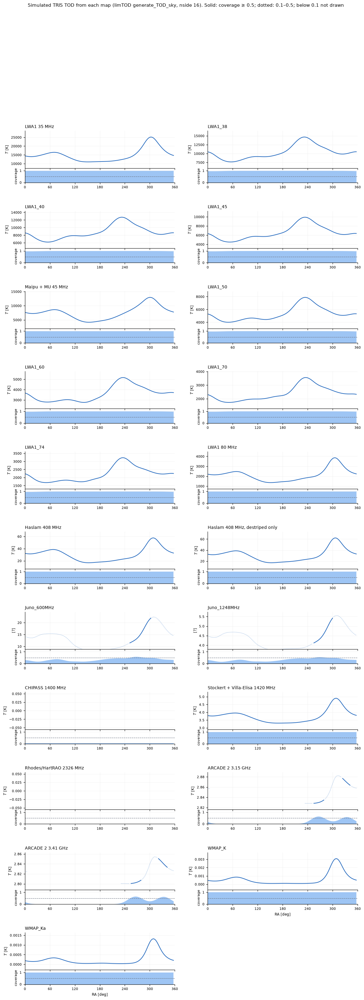

In [34]:
# One panel per map: the TOD in the map's own temperature, with the coverage underneath.
N_COLS = 2
n_rows = int(np.ceil(len(TODS) / N_COLS))
fig = plt.figure(figsize=(6.4 * N_COLS, 3.0 * n_rows))
outer = fig.add_gridspec(n_rows, N_COLS, hspace=0.55, wspace=0.22)
for k, (name, d) in enumerate(TODS.items()):
    inner = outer[k // N_COLS, k % N_COLS].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.08)
    ax, axc = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
    good = d["good"]
    # Below ~10% coverage the ratio divides by almost nothing and is noise; don't draw it.
    faint = ~good & (d["coverage"] >= 0.1)
    ax.plot(TOD_RA, np.where(good, d["tod"], np.nan), "-", color="#256abf")
    ax.plot(TOD_RA, np.where(faint, d["tod"], np.nan), ":", color="#256abf", alpha=0.6)
    if good.any():                                  # scale to what can be compared
        lo_t, hi_t = np.nanmin(d["tod"][good]), np.nanmax(d["tod"][good])
        pad = 0.25 * (hi_t - lo_t) if hi_t > lo_t else 0.05 * abs(hi_t)
        ax.set_ylim(lo_t - pad, hi_t + pad)
    unit = "$T$ [K]" if d["map"]["in_kelvin"] else f"[{d['map']['unit'] or '?'}]"
    ax.set_ylabel(unit)
    ax.set_title(f"{name}", loc="left")
    ax.tick_params(labelbottom=False)
    axc.fill_between(TOD_RA, 0, d["coverage"], color="#9ec5f4", lw=0)
    axc.axhline(MIN_COVERAGE, color="#6b7280", ls="--")
    axc.set_ylim(0, 1.05); axc.set_ylabel("coverage")
    for a in (ax, axc):
        a.set_xlim(0, 360); a.set_xticks(np.arange(0, 361, 60))
        a.grid(alpha=0.18, lw=0.6); a.set_axisbelow(True)
        for side in ("top", "right"):
            a.spines[side].set_visible(False)
    if k // N_COLS == n_rows - 1 or k + N_COLS >= len(TODS):
        axc.set_xlabel("RA [deg]")
fig.suptitle(f"Simulated TRIS TOD from each map (limTOD generate_TOD_sky, nside {TOD_NSIDE}). "
             f"Solid: coverage ≥ {MIN_COVERAGE}; dotted: 0.1–{MIN_COVERAGE}; below 0.1 not drawn",
             y=0.995)
plt.show()

#### Against each other, and against what TRIS actually measured

Every TOD on one plot, against RA. Each CMB-subtracted TOD is divided by its own mean over
the samples every map covers, so amplitude and frequency drop out and only the RA
structure remains. Where the curves agree, the surveys see the same sky through the TRIS
beam. Where they split, one survey's structure, zero level or scanning differs from the
rest. The real TRIS rings are drawn dashed, for reference.

The table underneath also gives each TOD's spectral index against the TRIS 600 MHz ring,
$\beta = \ln[T_\mathrm{map}/T_\mathrm{TRIS\,600}] / \ln(\nu_\mathrm{map}/600.5\ \mathrm{MHz})$,
with both temperatures CMB-subtracted. Synchrotron gives −2.5 to −3.0.

left out of the comparison: Juno_600MHz -- unit or frequency unknown
left out of the comparison: Juno_1248MHz -- unit or frequency unknown
left out of the comparison: CHIPASS 1400 MHz -- no sample reaches coverage 0.5 (max 0.06)
left out of the comparison: Rhodes/HartRAO 2326 MHz -- no sample reaches coverage 0.5 (max 0.01)
left out of the comparison: WMAP_K -- unit or frequency unknown
left out of the comparison: WMAP_Ka -- unit or frequency unknown


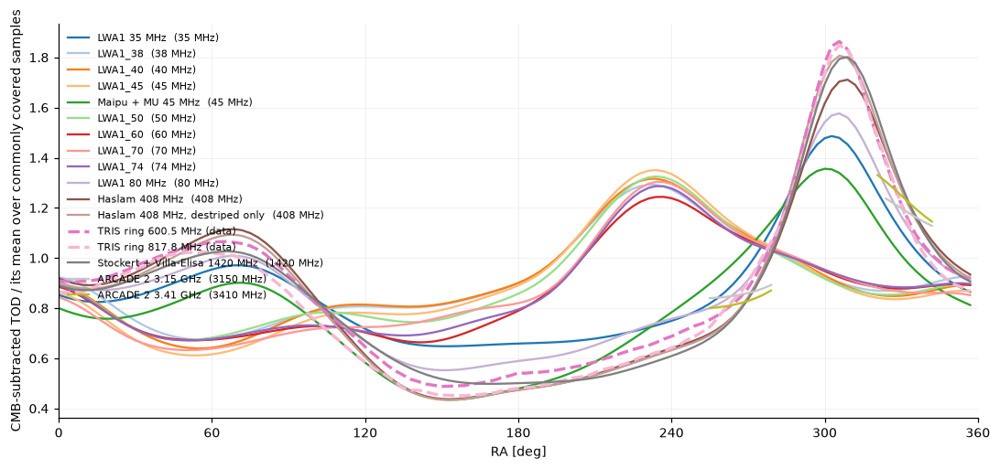

TOD                                       ν [MHz]      mean       min       max  peak RA   β vs TRIS600 (median, 16–84%)
LWA1 35 MHz                                  35.0 14880.908 10973.455 25151.999    302.8            -2.51 (-2.57, -2.46)
LWA1_38                                      38.0 10318.317  7641.093 14646.928    231.0            -2.44 (-2.63, -2.28)
LWA1_40                                      40.0  8749.753  6185.408 12724.720    233.8            -2.41 (-2.63, -2.25)
LWA1_45                                      45.0  6539.005  4486.771  9907.205    233.8            -2.41 (-2.64, -2.23)
Maipu + MU 45 MHz                            45.0  7596.348  4154.165 12940.882    300.0            -2.48 (-2.55, -2.45)
LWA1_50                                      50.0  5317.960  4001.602  7876.247    233.8            -2.44 (-2.66, -2.28)
LWA1_60                                      60.0  3583.686  2756.461  5163.888    237.0            -2.47 (-2.68, -2.30)
LWA1_70                         

In [35]:
REF600 = next(r for n, r in TRIS_RINGS if "600" in n)
ref600_ex = np.asarray(REF600.temperature_k) - tris.cmb_monopole_rj_k(REF600.effective_frequency_mhz)
nu600 = REF600.effective_frequency_mhz

def left_out_because(d):
    m = d["map"]
    if m["cmb"] == "anisotropy":
        return "CMB-anisotropy map: no foreground to compare"
    if not m["in_kelvin"] or m["freq_mhz"] is None:
        return "unit or frequency unknown"
    if not d["good"].any():
        return f"no sample reaches coverage {MIN_COVERAGE} (max {d['coverage'].max():.2f})"
    return None

compared = {n: d for n, d in TODS.items() if left_out_because(d) is None}
for n, d in TODS.items():
    if left_out_because(d):
        print(f"left out of the comparison: {n} -- {left_out_because(d)}")
common = (np.all([d["good"] for d in compared.values()], axis=0) if compared
          else np.zeros(TOD_RA.size, bool))

series = {}                                   # name -> (frequency, CMB-subtracted TOD, usable)
for name, d in compared.items():
    series[name] = (d["map"]["freq_mhz"], rj_excess(d["tod"], d["map"]), d["good"])
for name, ring in TRIS_RINGS:                 # the real TRIS data, as reference
    ex = np.asarray(ring.temperature_k) - tris.cmb_monopole_rj_k(ring.effective_frequency_mhz)
    series[f"TRIS ring {ring.effective_frequency_mhz:.1f} MHz (data)"] = (
        ring.effective_frequency_mhz, ex, np.ones(ex.size, bool))

order = sorted(series, key=lambda n: series[n][0])
# One distinct categorical colour per curve (tab10 up to 10 curves, tab20 beyond).
palette = plt.get_cmap("tab10" if len(order) <= 10 else "tab20").colors
colour = {name: palette[k % len(palette)] for k, name in enumerate(order)}

fig, ax_s = plt.subplots()
norm_on = common if common.any() else np.ones(TOD_RA.size, bool)
for name in order:
    nu, ex, ok = series[name]
    is_data = "(data)" in name
    shape = ex / np.nanmean(ex[norm_on & ok])
    ax_s.plot(TOD_RA, np.where(ok, shape, np.nan), "--" if is_data else "-",
              lw=2.2 if is_data else 1.5, color=colour[name],
              label=f"{name}" + ("" if is_data else f"  ({nu:g} MHz)"))
ax_s.set_xlabel("RA [deg]")
ax_s.set_ylabel("CMB-subtracted TOD / its mean over commonly covered samples")
ax_s.set_xlim(0, 360); ax_s.set_xticks(np.arange(0, 361, 60))
ax_s.grid(alpha=0.18, lw=0.6); ax_s.set_axisbelow(True)
for side in ("top", "right"):
    ax_s.spines[side].set_visible(False)
ax_s.legend(loc="upper left")
fig.tight_layout()
plt.show()

print(f"{'TOD':<40}{'ν [MHz]':>9}{'mean':>10}{'min':>10}{'max':>10}{'peak RA':>9}"
      f"{'β vs TRIS600 (median, 16–84%)':>32}")
for name in order:
    nu, ex, ok = series[name]
    t = ex[ok]
    if t.size == 0:
        print(f"{name:<40}{nu:9.1f}   no sample with coverage ≥ {MIN_COVERAGE}")
        continue
    with np.errstate(invalid="ignore", divide="ignore"):
        beta = np.log(ex / ref600_ex) / np.log(nu / nu600)
    b = beta[ok & np.isfinite(beta)]
    btxt = "—" if ("600" in name and "(data)" in name) or b.size == 0 else \
        f"{np.median(b):+.2f} ({np.percentile(b, 16):+.2f}, {np.percentile(b, 84):+.2f})"
    print(f"{name:<40}{nu:9.1f}{t.mean():10.3f}{t.min():10.3f}{t.max():10.3f}"
          f"{TOD_RA[ok][np.argmax(t)]:9.1f}{btxt:>32}")
print("\nTemperatures are CMB-subtracted, in K (RJ), over each TOD's usable samples.")
print(f"The shape panel normalises every curve over the {int(common.sum())} samples that ALL "
      f"maps cover (RA {TOD_RA[common].min():.0f}–{TOD_RA[common].max():.0f}°)."
      if common.any() else "No sample is covered by every map; shapes use all samples.")

#### The same comparison, scaled by a power law instead of by the mean

Here every CMB-subtracted TOD is brought to one reference frequency with a fixed spectral
index, instead of being divided by its own mean:

$$T_\mathrm{scaled}(\mathrm{RA}) = T(\mathrm{RA}) \left(\frac{\nu_\mathrm{ref}}{\nu}\right)^{\beta},
\qquad \beta = -2.7, \quad \nu_\mathrm{ref} = 408\ \mathrm{MHz}$$

$\nu_\mathrm{ref}$ is Haslam's frequency, the one the calibration targets, so Haslam is
drawn unscaled and everything stays in kelvin. Unlike the mean-normalised version, this
keeps each survey's **absolute level**. A survey whose true spectrum is flatter or
steeper than −2.7 between its frequency and 408 MHz lands above or below the others
by an overall factor. A zero-level offset shows up too, most visibly where the sky is
faint. Exactly how far apart the curves sit depends on the assumed β, and the longer
the lever arm, the more it matters: Maipu and ARCADE 2 are a factor of 8–9 from 408 MHz.

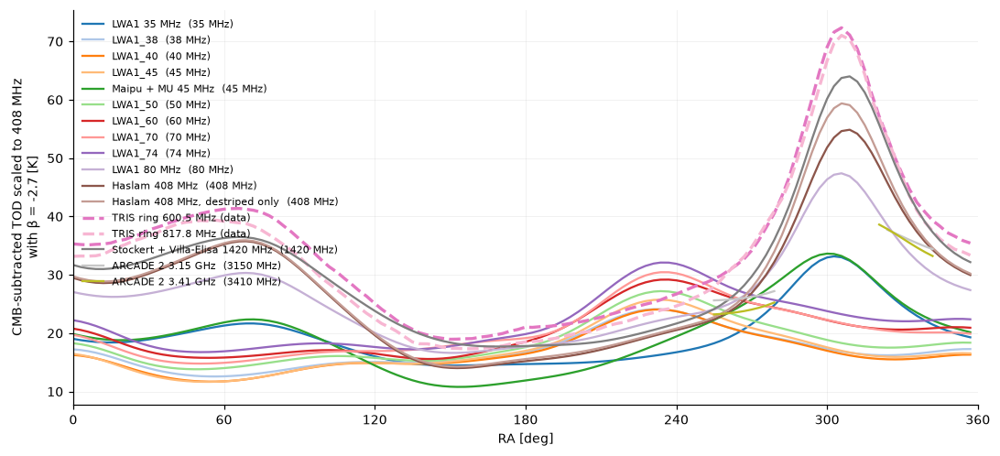

Each TOD scaled to 408 MHz with β = -2.7, against the TRIS 600 MHz ring scaled the same way (median over each TOD's usable samples):
  LWA1 35 MHz                              median   18.73 K   ratio to TRIS 600 0.59
  LWA1_38                                  median   16.36 K   ratio to TRIS 600 0.49
  LWA1_40                                  median   15.71 K   ratio to TRIS 600 0.46
  LWA1_45                                  median   16.09 K   ratio to TRIS 600 0.47
  Maipu + MU 45 MHz                        median   19.55 K   ratio to TRIS 600 0.57
  LWA1_50                                  median   17.57 K   ratio to TRIS 600 0.52
  LWA1_60                                  median   19.81 K   ratio to TRIS 600 0.58
  LWA1_70                                  median   19.39 K   ratio to TRIS 600 0.56
  LWA1_74                                  median   21.06 K   ratio to TRIS 600 0.63
  LWA1 80 MHz                              median   26.29 K   ratio to TRIS 600 0.77
  Haslam 408 MHz 

In [36]:
SCALE_BETA = -2.7
SCALE_REF_MHZ = 408.0

fig, ax = plt.subplots()
for name in order:
    nu, ex, ok = series[name]
    is_data = "(data)" in name
    scaled = ex * (SCALE_REF_MHZ / nu) ** SCALE_BETA
    ax.plot(TOD_RA, np.where(ok, scaled, np.nan), "--" if is_data else "-",
            lw=2.2 if is_data else 1.5, color=colour[name],
            label=f"{name}" + ("" if is_data else f"  ({nu:g} MHz)"))
ax.set_xlabel("RA [deg]")
ax.set_ylabel(f"CMB-subtracted TOD scaled to {SCALE_REF_MHZ:g} MHz\n"
              f"with β = {SCALE_BETA} [K]")
ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.grid(alpha=0.18, lw=0.6); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

ref_curve = series[next(n for n in order if "600" in n and "(data)" in n)]
ref_scaled = ref_curve[1] * (SCALE_REF_MHZ / ref_curve[0]) ** SCALE_BETA
print(f"Each TOD scaled to {SCALE_REF_MHZ:g} MHz with β = {SCALE_BETA}, against the TRIS 600 MHz "
      f"ring scaled the same way (median over each TOD's usable samples):")
for name in order:
    nu, ex, ok = series[name]
    scaled = ex * (SCALE_REF_MHZ / nu) ** SCALE_BETA
    if ok.any():
        print(f"  {name:<40} median {np.median(scaled[ok]):7.2f} K   "
              f"ratio to TRIS 600 {np.median(scaled[ok] / ref_scaled[ok]):.2f}")

#### Spectral index against RA

For each map, the spectral index between it and the TRIS 600 MHz ring at every sample:

$$\beta(\mathrm{RA}) = \frac{\ln\left[T_\mathrm{map}(\mathrm{RA}) / T_\mathrm{TRIS\,600}(\mathrm{RA})\right]}{\ln\left(\nu_\mathrm{map} / 600.5\ \mathrm{MHz}\right)}$$

Both temperatures are CMB-subtracted, as above, and the same maps are included. The shaded
band is the usual synchrotron range, −3.0 to −2.5.

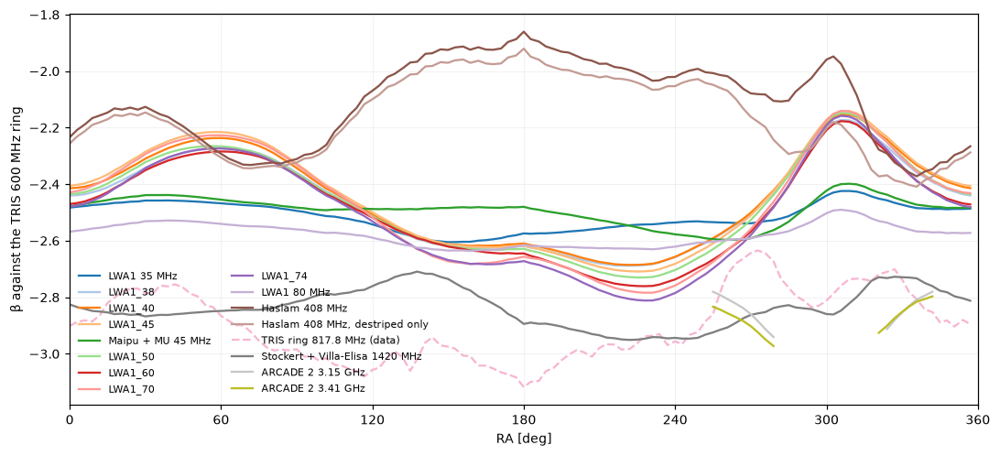

In [37]:
fig, ax = plt.subplots()
# ax.axhspan(-3.0, -2.5, color="0.92", lw=0, zorder=0, label="synchrotron, −3.0 to −2.5")
for name in order:
    nu, ex, ok = series[name]
    if "600" in name and "(data)" in name:
        continue                                   # the reference itself
    with np.errstate(invalid="ignore", divide="ignore"):
        beta = np.log(ex / ref600_ex) / np.log(nu / nu600)
    ax.plot(TOD_RA, np.where(ok, beta, np.nan), "--" if "(data)" in name else "-",
            color=colour[name], label=name)
ax.set_xlabel("RA [deg]")
ax.set_ylabel("β against the TRIS 600 MHz ring")
ax.set_xlim(0, 360); ax.set_xticks(np.arange(0, 361, 60))
ax.grid(alpha=0.18, lw=0.6)
ax.legend(ncol=2, loc="lower left")
fig.tight_layout()
plt.show()

---
## 07 — The nside of every file this notebook loads

One table of every data file read above, with the nside **stored in the file** (from
the loaded array, not from config), followed by the grids the notebook puts them on.
Built from what the sections above actually loaded, so a new file in `res/` shows up
here too.

In [38]:
def nside_row(source, nside, note=""):
    res = f"{hp.nside2resol(nside, arcmin=True) / 60:.3f}°" if nside else "—"
    npix = f"{hp.nside2npix(nside):,}" if nside else "—"
    print(f"  {source:<52}{nside or '—':>7}{npix:>13}{res:>10}  {note}")

print(f"  {'file':<52}{'nside':>7}{'npix':>13}{'pixel':>10}")
print("Files in res/ (section 05; ARCADE 2 and Haslam are also read in sections 02-03)")
for m in MAPS:
    nside_row(f"res/{m['file']}", m["nside"], m["how"])
for name, ring in TRIS_RINGS:
    nside_row(f"res/{name}", None, f"not HEALPix: drift ring, {ring.ra_deg.size} samples")
for name, ring in RINGS.items():
    nside_row(f"{ARCHIVE.name}/TRIS_absolute_{name}.txt", None,
              f"not HEALPix: drift ring, {ring.ra_deg.size} samples")
nside_row(f"{ARCHIVE.name}/TRIS_Beam_Profile.txt", None, "not HEALPix: E/H-plane cuts")

print("\nStage 1 products (section 04)")
for p in {id(g): g for g in GRIDS.values()}.values():
    nside_row(str(p.maps_path.relative_to(REPO)), hp.npix2nside(p["sky_full_k"].shape[1]))

print("\nGrids this notebook builds (not files)")
nside_row("TRIS beam map, beam plot (section 01)", NSIDE_BEAM)
nside_row("TRIS beam + GSM sky for TODs (section 01)", NSIDE_SKY, "tris.nside")
nside_row("TOD simulations of res/ maps (section 06)", TOD_NSIDE, "tris.nside")
nside_row("  ...beam up-sampled to", TOD_NSIDE_HIRES, "tris.nside_hires")
nside_row("  ...maps first degraded to", DEGRADE_FIRST, "speed only, above this nside")


  file                                                  nside         npix     pixel
Files in res/ (section 05; ARCADE 2 and Haslam are also read in sections 02-03)
  res/LWA_35MHz.fits                                      256      786,432    0.229°  HEALPix table, RING
  res/LWA1_38.fits                                        256      786,432    0.229°  HEALPix table, RING
  res/LWA1_40.fits                                        256      786,432    0.229°  HEALPix table, RING
  res/LWA1_45.fits                                        256      786,432    0.229°  HEALPix table, RING
  res/MAIPU_45mhZ.fits                                     64       49,152    0.916°  HEALPix table, NESTED
  res/LWA1_50.fits                                        256      786,432    0.229°  HEALPix table, RING
  res/LWA1_60.fits                                        256      786,432    0.229°  HEALPix table, RING
  res/LWA1_70.fits                                        256      786,432    0.229°  HEALP

# Part B — Coordinate frames

| | |
|---|---|
| **Reads** | Haslam and ARCADE 2 in `res/`, the TRIS rings, `outputs/stage1_nside8/`, `configs/run_pipeline.yaml` |
| **Writes** | a JSON summary of the frame checks |
| **Feeds the paper** | nothing directly; checks the frame handling every ring TOD relies on |



## Coordinate frames: Haslam, ARCADE 2 and TRIS into one frame

TRIS is equatorial (RA/Dec, LST-based). Haslam and ARCADE 2 have to be in the same frame
before any pixel of one is compared with a pixel of another. This notebook works in order:

1. **What each input actually declares**, read from its own header, not from convention.
   Each declaration is then checked against the sky.
2. **Pixel ordering**, because healpy's rotations need RING.
3. **Which rotation method, for each map**, following healpy's own guidance and checked
   by a round trip.
4. **Sanity check.** Do known sources land where the literature puts them after rotation?
5. **ARCADE 2's exact-zero mask, checked again after rotation.**

It stops there. Beam matching and smoothing are a separate step. The rotation code is
in `src/moonrunes/frames.py`.

In [1]:
%matplotlib inline
import os
os.environ["TQDM_DISABLE"] = "1"
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
warnings.filterwarnings("ignore", category=UserWarning)
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white"})

from moonrunes.config import load_config
from moonrunes import frames
from moonrunes.stage1_tris_maps import import_limtod_tris
from moonrunes.stage2_beam_matching import observed_mask

config = load_config(REPO / "configs" / "run_pipeline.yaml")
tris = import_limtod_tris(config)
FITS = {
    "Haslam 408 MHz":    config.resolve_path("paths.haslam_map_fits"),
    "ARCADE 2 3.15 GHz": config.resolve_path("paths.arcade2_map_3150"),
    "ARCADE 2 3.41 GHz": config.resolve_path("paths.arcade2_map_3410"),
}
ARCADE = {k: v for k, v in FITS.items() if k.startswith("ARCADE")}
STAGE1 = REPO / "outputs" / "stage1_nside8"

---
### 1. What each input declares

Every HDU is scanned for `COORDSYS` (the HEALPix standard) and for `SKYCOORD`. This matters
because ARCADE 2 does **not** write `COORDSYS`, which is why it has so far been recorded as
"frame unstated". It does, however, write `SKYCOORD`.

In [2]:
print(f"{'file':<20}{'frame':>7}  {'stated as':<34}{'ORDERING':>9}{'NSIDE':>7}")
DECLARED = {}
for name, path in FITS.items():
    d = frames.declared_frame(path)
    DECLARED[name] = d
    stated = ", ".join(f"HDU{s['hdu']} {s['keyword']}={s['value']!r}"
                       for s in d["statements"]) or "(nothing)"
    print(f"{name:<20}{str(d['frame']):>7}  {stated:<34}{d['ordering']:>9}{d['nside']:>7}")

# TRIS: stage 1 writes .npz + JSON, not FITS.  Look for anything frame-like in both.
manifest = json.loads((STAGE1 / "stage1_manifest.json").read_text())
npz = np.load(next(STAGE1.glob("*.npz")))
hits = [k for k in list(npz.files) + list(json.dumps(manifest).split('"'))
        if any(w in k.lower() for w in ("coord", "frame", "galactic", "equatorial", "icrs"))]
print(f"\nTRIS stage 1       arrays {npz.files}")
print(f"                   frame-like keys in npz or manifest: {hits or 'none'}")
print("                   ra_deg is present: the grid is indexed by right ascension")

file                  frame  stated as                          ORDERING  NSIDE
Haslam 408 MHz            G  HDU1 COORDSYS='GALACTIC'               RING    512
ARCADE 2 3.15 GHz         G  HDU0 SKYCOORD='Galactic', HDU1 SKYCOORD='Galactic'   NESTED     16
ARCADE 2 3.41 GHz         G  HDU0 SKYCOORD='Galactic', HDU1 SKYCOORD='Galactic'   NESTED     16

TRIS stage 1       arrays ['nside', 'pixel_indices', 'band_mask', 'freq_mhz', 'effective_freq_mhz', 'ref_freq_mhz', 'sky_k', 'sky_sigma_k', 'prior_mean_k', 'prior_sigma_k', 'truth_k', 'zero_level_k', 'zero_level_sigma_k', 'zero_level_prior_sigma_k', 'ra_deg', 'data_k', 'residual_k', 'beam_coverage', 'sky_full_k', 'sky_sigma_full_k']
                   frame-like keys in npz or manifest: none
                   ra_deg is present: the grid is indexed by right ascension


**What the headers say.** Haslam and both ARCADE 2 files declare **Galactic**, and none of the
HDUs contradicts another. The stage 1 TRIS product declares **nothing**. It is equatorial by
construction (limTOD sets the boresight to `RA = LST, dec = site latitude` and builds its
operator on an equatorial pixel grid), but no file records that.

A header is a label, so each label is tested against the sky next.

#### TRIS: does the ring peak where the Galactic plane crosses dec +42°?

astropy's frame transforms are independent of healpy's rotation matrices, so astropy gives
the right ascensions at which b = 0 crosses the ring's declination. The ring's own brightest
samples should sit there.

ring dec 42.43°: b = 0 at RA 74.9° (l = 164°), 310.8° (l = 82°)
600 MHz ring: brightest sample at RA 305.8° (28.19 K)
820 MHz ring: brightest sample at RA 305.8° (13.57 K)


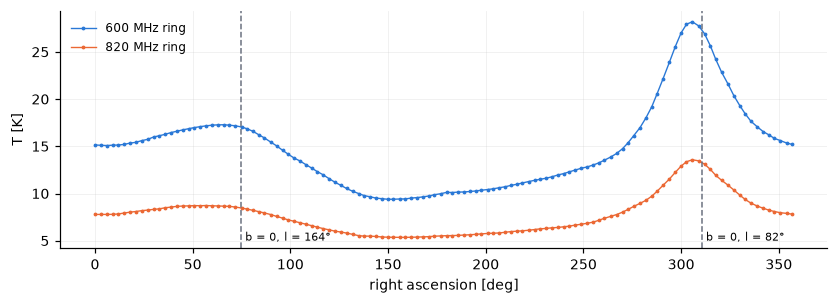

In [3]:
dec_ring = tris.TRIS_SITE_LATITUDE_DEG
ra_grid = np.arange(0, 360, 0.05)
b_grid = SkyCoord(ra=ra_grid * u.deg, dec=np.full_like(ra_grid, dec_ring) * u.deg).galactic.b.deg
crossings = ra_grid[np.flatnonzero(np.diff(np.sign(b_grid)))]
l_cross = SkyCoord(ra=crossings * u.deg, dec=[dec_ring] * len(crossings) * u.deg).galactic.l.deg
print(f"ring dec {dec_ring:.2f}°: b = 0 at RA " +
      ", ".join(f"{r:.1f}° (l = {l:.0f}°)" for r, l in zip(crossings, l_cross)))

ARCHIVE = config.resolve_path("paths.tris_archive_dir")
fig, ax = plt.subplots()
for freq, colour in ((600, "#2a78d6"), (820, "#eb6834")):
    ring = tris.read_tris_ring(ARCHIVE / f"TRIS_absolute_{freq}.txt")
    ra, t = np.asarray(ring.ra_deg), np.asarray(ring.temperature_k)
    print(f"{freq} MHz ring: brightest sample at RA {ra[np.argmax(t)]:.1f}° ({t.max():.2f} K)")
    ax.plot(ra, t, ".-", ms=3, color=colour, label=f"{freq} MHz ring")
for r, l in zip(crossings, l_cross):
    ax.axvline(r, color="#6b7280", ls="--")
    ax.text(r + 2, ax.get_ylim()[0] + 0.5, f"b = 0, l = {l:.0f}°", fontsize=7.5, va="bottom")
ax.set_xlabel("right ascension [deg]"); ax.set_ylabel("T [K]")
ax.grid(alpha=0.18, lw=0.6); ax.legend(loc="upper left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

The ring's brightest sample, at both frequencies, is 5° from the Cygnus crossing
(l ≈ 82°). That is where the Cygnus X complex actually sits, and 5° is well inside an 18°
beam. So the TRIS RA axis is genuinely equatorial, and **TRIS needs no rotation**.

One residual caveat: the archive does not state an epoch. RA = LST is epoch-of-date, and
healpy's `C` is J2000. Precession is about 0.014° per year, so a decade is 0.14°. That is
negligible against 3° samples and 7° pixels, but it is recorded here rather than assumed away.

#### Haslam and ARCADE 2: is the bright emission at low |b| in the files' own frame?

If a file really is Galactic, its brightest pixels sit on b ≈ 0 when read in its own
frame. If it were equatorial, reading it as Galactic would scatter them.

In [4]:
for name, path in FITS.items():
    sky = hp.read_map(path, field=0)
    valid = observed_mask(sky, "zeros" if name.startswith("ARCADE") else "full")
    idx = np.flatnonzero(valid)
    top = idx[np.argsort(sky[idx])[-20:]]
    lon, lat = hp.pix2ang(hp.get_nside(sky), top, lonlat=True)
    # the same pixels, if the file were in fact equatorial
    b_if_eq = SkyCoord(ra=lon * u.deg, dec=lat * u.deg).galactic.b.deg
    print(f"{name:<18} 20 brightest pixels: median |lat| read as Galactic {np.median(np.abs(lat)):5.1f}°"
          f"   ...as if equatorial, median |b| {np.median(np.abs(b_if_eq)):5.1f}°")

Haslam 408 MHz     20 brightest pixels: median |lat| read as Galactic   2.1°   ...as if equatorial, median |b|   7.0°
ARCADE 2 3.15 GHz  20 brightest pixels: median |lat| read as Galactic   4.8°   ...as if equatorial, median |b|  50.8°
ARCADE 2 3.41 GHz  20 brightest pixels: median |lat| read as Galactic   4.8°   ...as if equatorial, median |b|  50.6°


Both readings agree with the headers. The brightest emission sits on the Galactic plane in
each file's own frame. Read as equatorial, it would move off the plane by a median of about
50° for ARCADE 2. For Haslam the move is only about 7°, because its brightest pixels are Cas A
and the Galactic-centre region, and those happen to land near the plane either way. The
decisive test for Haslam is therefore the landmark check in section 4.
All three FITS maps need **Galactic → equatorial** (`hp.Rotator(coord=['G', 'C'])`).

---
### 2. Pixel ordering

healpy's rotations index pixels in RING. ARCADE 2 is stored NESTED. `hp.read_map` reads
`ORDERING` and reorders to RING by default, which this pipeline relies on. That is checked
here rather than trusted.

In [5]:
for name, path in FITS.items():
    stored = hp.read_map(path, nest=None)          # exactly as on disk
    default = hp.read_map(path)                    # what the pipeline reads
    order = DECLARED[name]["ordering"]
    expected = hp.reorder(stored, n2r=True) if order == "NESTED" else stored
    print(f"{name:<18} on disk {order:<7} -> hp.read_map gives RING: "
          f"{np.array_equal(default, expected)}")
print("\nEvery consumer (stage 2's load_input_map included) reads through hp.read_map,")
print("so the rotated maps stay RING and nothing converts back to NESTED.")

Haslam 408 MHz     on disk RING    -> hp.read_map gives RING: True
ARCADE 2 3.15 GHz  on disk NESTED  -> hp.read_map gives RING: True
ARCADE 2 3.41 GHz  on disk NESTED  -> hp.read_map gives RING: True

Every consumer (stage 2's load_input_map included) reads through hp.read_map,
so the rotated maps stay RING and nothing converts back to NESTED.


---
### 3. Which rotation, per map

healpy's documentation does not choose by nside. It chooses by two properties of the map:

* `rotate_map_alms`: *"generally the best strategy to rotate/change reference frame of
  maps. If the input map is band-limited … the map rotation will be invertible."*
* `rotate_map_pixel`: *"A case where pixel space rotation is better is for heavily masked
  maps where the spherical harmonics transform is not well defined … Due to interpolation,
  this function generally suppresses the signal at high angular scales."*

| map | nside | pixel | beam | mask | → method |
|---|---|---|---|---|---|
| Haslam | 512 | 0.11° | 0.93° | none | harmonic: band-limited, full sky |
| ARCADE 2 | 16 | 3.7° | 11.6° | 93% exact zero | pixel: heavily masked |

For Haslam the choice is tested directly with a G → C → G round trip, which would return
the input exactly for a perfect rotation.

In [6]:
haslam = hp.read_map(FITS["Haslam 408 MHz"])
to_g = hp.Rotator(coord=["C", "G"])
haslam_eq = frames.rotate_full_sky(haslam)                     # harmonic
trip_alm = to_g.rotate_map_alms(haslam_eq) - haslam
trip_pix = to_g.rotate_map_pixel(hp.Rotator(coord=["G", "C"]).rotate_map_pixel(haslam)) - haslam
print(f"{'Haslam G->C->G':<16}{'rms [K]':>9}{'max |Δ| [K]':>13}{'rms / map rms':>15}")
for label, d in (("harmonic", trip_alm), ("pixel", trip_pix)):
    print(f"{label:<16}{d.std():9.3f}{np.abs(d).max():13.1f}{d.std() / haslam.std():15.1e}")
print(f"\nrotated map: min {haslam_eq.min():.2f} K (input {haslam.min():.2f} K), "
      f"max {haslam_eq.max():.0f} K (input {haslam.max():.0f} K)")

Haslam G->C->G    rms [K]  max |Δ| [K]  rms / map rms
harmonic            0.080         33.0        2.1e-03
pixel               0.525        311.4        1.3e-02

rotated map: min 11.02 K (input 10.98 K), max 4863 K (input 4779 K)


The harmonic route is about 6× better in rms and 10× better in the worst pixel. The pixel
route loses peak brightness on compact sources through bilinear interpolation. The
harmonic route overshoots the brightest source (Cas A) by about 2%, which is Gibbs ringing
at a near-point source. It stays positive everywhere, and the map is about to be smoothed
to a 23° beam. **Haslam: harmonic.**

---
### 4. Sanity check: do known sources land where the literature says?

Three compact, bright 408 MHz sources, at their literature ICRS positions:

| source | RA | Dec | reference |
|---|---|---|---|
| Sgr A* (the Galactic centre) | 17h45m40.04s | −29°00′28.1″ | Reid & Brunthaler 2004, ApJ 616, 872 |
| Cas A | 23h23m24s | +58°48′54″ | SIMBAD |
| Tau A (Crab) | 05h34m31.94s | +22°00′52.2″ | SIMBAD |

In the **rotated** map, the brightest pixel within 5° of each position should be at
that position, to within about a beam (0.93°). The **unrotated** map, read as though it
were already equatorial, is the control. There the search should find nothing special.

In [7]:
LANDMARKS = {
    "Sgr A* (Galactic centre)": (266.41683, -29.00781),
    "Cas A":                    (350.85000, +58.81500),
    "Tau A (Crab)":             (83.63308, +22.01450),
}
SEARCH_DEG, BEAM_DEG = 5.0, 0.9333
print(f"{'':<26}{'':<12}{'peak RA':>9}{'peak Dec':>10}{'T [K]':>9}{'offset':>9}{'in beams':>10}  verdict")
CHECK = {}
for label, sky in (("rotated", haslam_eq), ("unrotated", haslam)):
    for src, r in frames.source_offsets_deg(sky, LANDMARKS, SEARCH_DEG).items():
        ok = r["offset_deg"] < BEAM_DEG
        CHECK[label, src] = ok
        print(f"{src:<26}{label:<12}{r['peak_lon_deg']:9.2f}{r['peak_lat_deg']:+10.2f}"
              f"{r['peak_k']:9.0f}{r['offset_deg']:8.2f}°{r['offset_deg'] / BEAM_DEG:10.2f}  "
              f"{'AT LITERATURE POSITION' if ok else 'not there'}")
peak = np.argmax(haslam_eq)
print(f"\nglobal maximum of the rotated map: RA {hp.pix2ang(512, peak, lonlat=True)[0]:.2f}°, "
      f"Dec {hp.pix2ang(512, peak, lonlat=True)[1]:+.2f}°  (Cas A)")

# The whole plane, not just three points: astropy's b for every rotated pixel.
ra_pix, dec_pix = hp.pix2ang(512, np.arange(haslam_eq.size), lonlat=True)
b_pix = SkyCoord(ra=ra_pix * u.deg, dec=dec_pix * u.deg).galactic.b.deg
print(f"median T at astropy |b| < 2°: rotated {np.median(haslam_eq[np.abs(b_pix) < 2]):.1f} K, "
      f"unrotated {np.median(haslam[np.abs(b_pix) < 2]):.1f} K   "
      f"(|b| > 60°: {np.median(haslam_eq[np.abs(b_pix) > 60]):.1f} K)")
assert all(CHECK["rotated", s] for s in LANDMARKS), "a landmark is not where it should be"
assert not any(CHECK["unrotated", s] for s in LANDMARKS), "the control should fail"

                                        peak RA  peak Dec    T [K]   offset  in beams  verdict
Sgr A* (Galactic centre)  rotated        266.48    -29.06     1919    0.08°      0.08  AT LITERATURE POSITION
Cas A                     rotated        350.76    +58.92     4863    0.11°      0.12  AT LITERATURE POSITION
Tau A (Crab)              rotated         83.50    +21.94      342    0.15°      0.16  AT LITERATURE POSITION
Sgr A* (Galactic centre)  unrotated      264.46    -24.62       20    4.72°      5.05  not there
Cas A                     unrotated      356.98    +55.49       29    4.70°      5.03  not there
Tau A (Crab)              unrotated       86.84    +18.60       39    4.54°      4.87  not there

global maximum of the rotated map: RA 350.76°, Dec +58.92°  (Cas A)


median T at astropy |b| < 2°: rotated 71.1 K, unrotated 23.4 K   (|b| > 60°: 19.6 K)


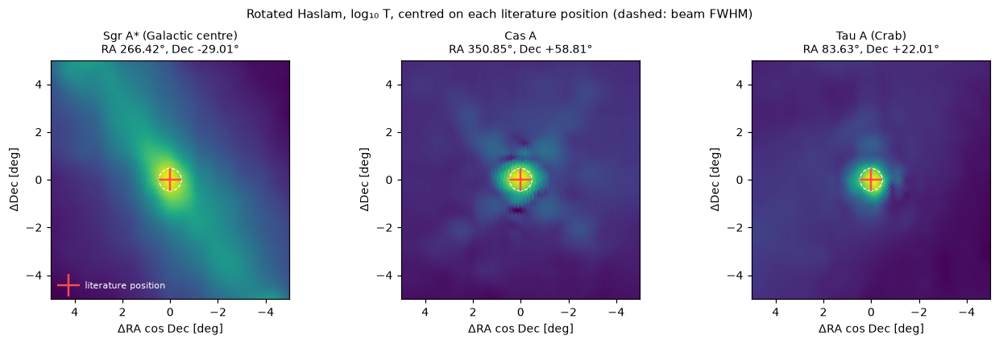

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (src, (ra0, dec0)) in zip(axes, LANDMARKS.items()):
    img = hp.gnomview(haslam_eq, rot=[ra0, dec0], reso=3.0, xsize=200, return_projected_map=True,
                      no_plot=True)
    half = 200 * 3.0 / 60 / 2
    ax.imshow(np.log10(img), origin="lower",
              extent=[half, -half, -half, half])       # RA increases to the left
    ax.plot(0, 0, "+", color="#ff4d4d", ms=18, mew=1.6, label="literature position")
    ax.add_patch(plt.Circle((0, 0), BEAM_DEG / 2, fill=False, color="w", ls="--"))
    ax.set_title(f"{src}\nRA {ra0:.2f}°, Dec {dec0:+.2f}°")
    ax.set_xlabel("ΔRA cos Dec [deg]"); ax.set_ylabel("ΔDec [deg]")
axes[0].legend(loc="lower left", labelcolor="w")
fig.suptitle("Rotated Haslam, log₁₀ T, centred on each literature position (dashed: beam FWHM)")
fig.tight_layout()
plt.show()

---
### 5. ARCADE 2: does the exact-zero mask survive the rotation?

`rotate_map_pixel` interpolates bilinearly over four neighbours. At the mask edge those
include zeros, so a plain rotation averages real 3 K sky with the 0 K fill and produces
pixels that are neither data nor mask. `frames.rotate_masked` rotates the zero-filled data
and the binary mask separately and divides one by the other. Each output pixel is then a
weighted mean over observed neighbours only. Pixels where less than half the interpolation
weight was observed are marked unobserved (the same 0.5 as stage 2's `weight_floor`).

Checks, on each band:

* no exact zeros and no non-finite values inside the rotated mask;
* every rotated value lies inside the original observed range. A zero leaking in would
  drag some below the minimum;
* the observed area is preserved, since a rotation preserves area;
* the mask is rebuilt independently from the `N_OBS` column and must agree;
* stage 2's own `observed_mask(..., "zeros")` reads the rotated map correctly;
* the plain rotation is shown too, to prove these checks can detect the failure.

In [9]:
haslam_eq_16 = hp.ud_grade(haslam_eq, 16)
ROTATED = {}
for name, path in ARCADE.items():
    t, n_obs = hp.read_map(path, field=0), hp.read_map(path, field=1)
    obs = observed_mask(t, "zeros")
    assert np.array_equal(obs, n_obs > 0), "zeros and N_OBS disagree before rotation"
    rot, obs_r, weight = frames.rotate_masked(t, obs)
    _, obs_from_nobs, _ = frames.rotate_masked(n_obs, n_obs > 0)
    naive = hp.Rotator(coord=["G", "C"]).rotate_map_pixel(t)
    ROTATED[name] = dict(t=t, obs=obs, rot=rot, obs_r=obs_r, weight=weight, naive=naive)

    inside = rot[obs_r]
    lo, hi = t[obs].min(), t[obs].max()
    leaked = (naive > 0) & (naive < lo)
    checks = {
        "no exact zeros inside mask":        int((inside == 0).sum()) == 0,
        "all finite inside mask":            bool(np.all(np.isfinite(inside))),
        "values inside original range":      bool(lo <= inside.min() and inside.max() <= hi),
        "N_OBS-derived mask agrees":         bool(np.array_equal(obs_r, obs_from_nobs)),
        "stage 2 observed_mask reads it":    bool(np.array_equal(observed_mask(rot, "zeros"), obs_r)),
    }
    print(f"{name}: observed {obs.sum()} -> {obs_r.sum()} pixels; range "
          f"[{lo:.4f}, {hi:.4f}] -> [{inside.min():.4f}, {inside.max():.4f}] K; "
          f"{int((weight[obs_r] < 0.999).sum())} edge pixels renormalised")
    for check, ok in checks.items():
        print(f"    {'PASS' if ok else 'FAIL'}  {check}")
    print(f"    plain rotate_map_pixel, for contrast: {leaked.sum()} pixels dragged below "
          f"{lo:.2f} K by the zero fill (lowest {naive[leaked].min():.1e} K)")

    back, obs_back, _ = frames.rotate_masked(rot, obs_r, frames=("C", "G"))
    both = obs & obs_back
    corr = np.corrcoef(rot[obs_r], haslam_eq_16[obs_r])[0, 1]
    corr_control = np.corrcoef(t[obs], haslam_eq_16[obs])[0, 1]
    print(f"    C->G round trip: rms {1e3 * np.std(back[both] - t[both]):.1f} mK "
          f"against a {1e3 * t[obs].std():.0f} mK signal rms")
    print(f"    correlation with rotated Haslam: {corr:.3f} rotated, "
          f"{corr_control:.3f} left unrotated\n")
    assert all(checks.values()), name

ARCADE 2 3.15 GHz: observed 220 -> 220 pixels; range [2.8024, 3.2259] -> [2.8033, 3.2178] K; 82 edge pixels renormalised
    PASS  no exact zeros inside mask
    PASS  all finite inside mask
    PASS  values inside original range
    PASS  N_OBS-derived mask agrees
    PASS  stage 2 observed_mask reads it
    plain rotate_map_pixel, for contrast: 158 pixels dragged below 2.80 K by the zero fill (lowest 2.5e-05 K)
    C->G round trip: rms 7.8 mK against a 85 mK signal rms
    correlation with rotated Haslam: 0.954 rotated, -0.081 left unrotated

ARCADE 2 3.41 GHz: observed 232 -> 234 pixels; range [2.7760, 3.1709] -> [2.7808, 3.1613] K; 83 edge pixels renormalised
    PASS  no exact zeros inside mask
    PASS  all finite inside mask
    PASS  values inside original range
    PASS  N_OBS-derived mask agrees
    PASS  stage 2 observed_mask reads it
    plain rotate_map_pixel, for contrast: 156 pixels dragged below 2.78 K by the zero fill (lowest 2.4e-05 K)
    C->G round trip: rms 7.2 mK 

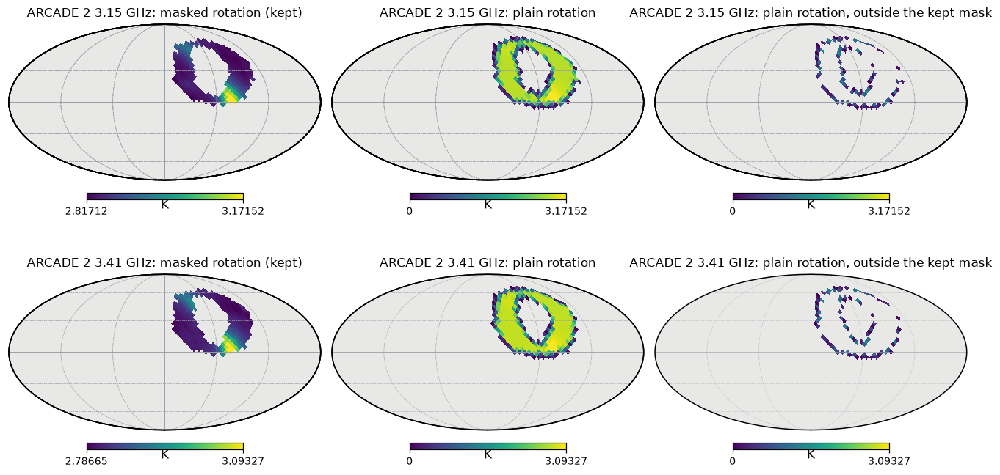

In [10]:
fig = plt.figure(figsize=(12, 6.2))
for row, (name, r) in enumerate(ROTATED.items()):
    lo, hi = np.percentile(r["t"][r["obs"]], [2, 98])
    naive = np.where(r["naive"] > 0, r["naive"], hp.UNSEEN)
    edge = np.where(r["obs_r"], hp.UNSEEN, naive)       # what the plain rotation adds
    for column, (title, m, kw) in enumerate((
            ("masked rotation (kept)", r["rot"], dict(min=lo, max=hi)),
            ("plain rotation", naive, dict(min=0, max=hi)),
            ("plain rotation, outside the kept mask", edge, dict(min=0, max=hi)))):
        hp.mollview(m, coord="C", sub=(2, 3, 3 * row + column + 1), fig=fig.number,
                    title=f"{name}: {title}", unit="K", notext=True,
                    badcolor="#e8e8e6", **kw)
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
plt.show()

---
### Verdict

**Headers (step 1)**

| input | declares | keyword | ordering | checked against the sky | action |
|---|---|---|---|---|---|
| Haslam 408 MHz | Galactic | `COORDSYS='GALACTIC'`, HDU 1 | RING, nside 512 | brightest pixels on b ≈ 0 | G → C, harmonic |
| ARCADE 2 3.15 GHz | Galactic | `SKYCOORD='Galactic'`, HDU 0 and 1 | NESTED → RING on read, nside 16 | brightest on b ≈ 0, l ≈ 31–39° | G → C, pixel, mask-aware |
| ARCADE 2 3.41 GHz | Galactic | `SKYCOORD='Galactic'`, HDU 0 and 1 | as above | as above | as above |
| TRIS stage 1 | **nothing** (npz + JSON) | none | RING, nside 8 | ring peaks 5° from the Cygnus b = 0 crossing | none: equatorial already |

ARCADE 2 had been recorded as "frame unstated" because it has no `COORDSYS`. It does state
Galactic, under a keyword healpy does not read. The TRIS product states nothing, and its
frame rests on limTOD's construction, now also confirmed against the sky.

**Sanity check (step 4).** In the rotated Haslam map, Sgr A*, Cas A and Tau A all peak
within about one 0.11° pixel of their literature positions, a small fraction of the 0.93°
beam. The global maximum is Cas A. In the unrotated control, the same searches find
only background at the edge of the search disc, about 4.5–4.7° away. Independently,
rotated ARCADE 2 correlates with rotated Haslam at 0.95, against about −0.07 unrotated.

**Mask (step 5).** The exact-zero mask survives: no zeros or non-finite values inside it,
every value within the original range, area preserved to within about 1%, and agreement
with the `N_OBS` mask. A plain rotation would have contaminated about 157 edge pixels per
band.

**Not done here:** beam matching and smoothing. The pixel rotation's bilinear
interpolation costs a little resolution at nside 16 (the round-trip rms above). That is
small next to the 23° smoothing that follows, but it is not zero.

# Part C — Stage-1 (TRIS map-making) diagnostics and prior-only runs

| | |
|---|---|
| **Reads** | `outputs/stage1/`, `outputs/stage1_nside16_high_noise/`, `outputs/stage1_nside16_prior_only/`, `res/`, `configs/run_pipeline.yaml` |
| **Writes** | inline figures |
| **Feeds the paper** | nothing directly; checks the stage-1 maps behind `fig3_method_tris_maps` |

The beam sections the introduction below mentions are in `tests_analysis/` Part K2.


## Stage 1 diagnostics

Reads `outputs/stage1/` and asks four questions in order, because a later one is
meaningless if an earlier one fails:

1. **Did the solve converge?** — not "did it finish". A solve can diverge silently and still
   return an answer, so stage 1 can cross-check
   limTOD's answer against an exact reference and refuse to write a product that fails.
2. **Does the model describe the ring?** — reduced χ² and the residuals.
3. **Did the data actually move the map?** — prior → posterior σ shrinkage and z-scores.
4. **Is the product fit to use?** — the degrade to `beam.nside_new`, and the
   spectral index between the two solved maps.

The beam diagnostics (the elliptical `tris_cuts` kernel against the 23.366° circular one) are in `tests_analysis/`
Part K2.

Run stage 1 first if `outputs/stage1/` is empty:

```
python run_pipeline.py --stage 1
```

In [1]:
%matplotlib inline
import os
os.environ["TQDM_DISABLE"] = "1"

import sys
import warnings
from pathlib import Path

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from scipy.stats import norm

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

warnings.filterwarnings("ignore", category=UserWarning)
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white"})

from moonrunes.config import load_config
from moonrunes.stage1_tris_maps import load_stage1, import_limtod_tris

config = load_config(REPO / "configs" / "run_pipeline.yaml")
tris = import_limtod_tris(config)
BORESIGHT_DEC = tris.TRIS_SITE_LATITUDE_DEG
# The default product is the nside 8 run.  outputs/stage1/ holds an older
# nside 16 solve, so load the nside 8 products explicitly.
DEFAULT_RUN = REPO / "outputs" / "stage1"
products = load_stage1(config,
                       maps_path=DEFAULT_RUN / "tris_maps_tris_haslam_v0.npz",
                       manifest_path=DEFAULT_RUN / "stage1_manifest.json")
manifest = products.manifest

# The archive's own per-sample statistical errors, which are what the solver
# weights by. The config floor replaces ONLY the single row published as
# 0.000 K; the other 119 samples keep their published value.
ARCHIVE = config.resolve_path("paths.tris_archive_dir")
_RING_FILE = {600: "TRIS_absolute_600.txt", 820: "TRIS_absolute_820.txt"}
STAT_ERR = {f: np.asarray(tris.read_tris_ring(ARCHIVE / fn).statistical_uncertainty_k,
                          dtype=float)
            for f, fn in _RING_FILE.items()}

FREQS = [int(f) for f in products.frequencies_mhz]
NSIDE = products.nside
NPIX_BAND = products.pixel_indices.size

print("maps     ", products.maps_path)
print("manifest ", products.manifest_path)
print("written  ", manifest["written_utc"])
print()
print(f"run '{manifest['run_name']}': {FREQS} MHz, nside {NSIDE}, "
      f"{NPIX_BAND} pixels in the band, "
      f"{products['data_k'].shape[1]} samples per ring")
print(f"mapmaker {manifest['config_used']['tris']['mapmaker']}, "
      f"solver {manifest['config_used']['tris']['solver']['method']}, "
      f"prior {manifest['config_used']['tris']['prior']['template']}")

maps      /Users/user/Documents/Codes/project3/moonrunes/outputs/stage1/tris_maps_tris_haslam_v0.npz
manifest  /Users/user/Documents/Codes/project3/moonrunes/outputs/stage1/stage1_manifest.json
written   2026-10-02T12:28:33+00:00

run 'tris_haslam_v0': [600, 820] MHz, nside 16, 1272 pixels in the band, 120 samples per ring
mapmaker prior_regularized, solver gmres, prior gsm2008


---
### 1. Did the solve converge?

Stage 1 solves the MAP system with limTOD's dense Wiener filter, factorising
$(A^\mathsf{T}N^{-1}A + P^{-1} + \epsilon I)$ directly.

`info == 0` alone is not evidence of anything, so stage 1 *can* compare every solve
against the exact matrix inversion lemma at a single frequency (the inner matrix is only
`n_samples × n_samples`). The discrepancy is quoted **in posterior σ**, which is the unit
in which a solver error either matters or does not: the residual norm is a poor proxy
here because the prior width spans an order of magnitude across the band.

**This cross-check is switched off** (`tris.solver.cross_check: false`). A product made with
it off records the comparison as `None`, and the cell below says so instead of giving a verdict.

In [2]:
print(f"{'nu':>5}{'backend':>10}{'σ from exact':>15}{'tolerance':>11}"
      f"{'time [s]':>10}   verdict")
for freq in FREQS:
    s = products.diagnostics(freq)["solver"]
    check = s.get("solver_vs_woodbury_sigma")
    if check is None:
        print(f"{freq:5d}{s['backend']:>10}{'—':>15}{'—':>11}{s['seconds']:10.3f}   "
              f"not checked (tris.solver.cross_check off)")
        continue
    ok = check < s["cross_check_max_sigma"]
    print(f"{freq:5d}{s['backend']:>10}{check:15.2e}"
          f"{s['cross_check_max_sigma']:11.1e}{s['seconds']:10.3f}   "
          f"{'verified' if ok else 'FAILED'}")
print(f"\nsolver: {products.diagnostics(FREQS[0])['solver']['method']}")
print("A dense direct solve has no iteration count and no info flag. The convergence")
print("statement is the comparison against the exact reference, when")
print("tris.solver.cross_check is on (it is off since 2026-10-14).")

   nu   backend   σ from exact  tolerance  time [s]   verdict
  600    limtod       5.31e-10    1.0e-04     0.061   verified
  820    limtod       1.46e-10    1.0e-04     0.055   verified

solver: wiener_filter_map (dense, direct)
A dense direct solve has no iteration count and no info flag. The convergence
statement is the comparison against the exact reference, when
tris.solver.cross_check is on (it is off since 2026-10-14).


---
### 2. Does the model describe the ring?

Reduced χ² is the first number to look at. Far above 1 means the prior and the operator
together cannot describe the ring — usually a sky template that is wrong at a level the
statistical errors can see. Part A measured exactly that: GSM2008 is ~1.9 K cold at
600 MHz.

   nu  reduced χ²  residual rms [K]  median stat. err [K]   ratio
  600       16.14            0.0562                0.0100     5.6
  820        5.88            0.0495                0.0110     4.5

The residual is several times the median statistical error and is coherent
in RA. That is a misspecified template, not a badly tuned solver.


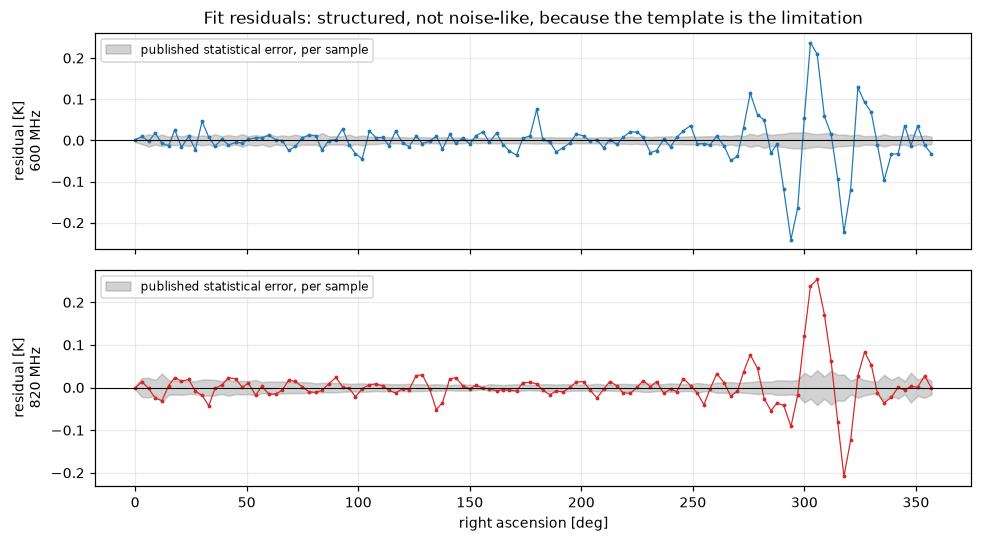

In [3]:
fig, axes = plt.subplots(len(FREQS), 1, figsize=(9, 2.5 * len(FREQS)), sharex=True)
axes = np.atleast_1d(axes)

print(f"{'nu':>5}{'reduced χ²':>12}{'residual rms [K]':>18}"
      f"{'median stat. err [K]':>22}{'ratio':>8}")
for ax, freq, colour in zip(axes, FREQS, ("tab:blue", "tab:red")):
    i = products.index(freq)
    d = products.diagnostics(freq)
    residual = products["residual_k"][i]
    ra = products["ra_deg"][i]
    # The ring's OWN per-sample errors, as the solver weights by them -- not the
    # single floor value. They run 4-20 mK at 600 MHz, so a flat band would
    # misstate the error on most samples.
    sigma = np.maximum(STAT_ERR[freq], float(d["uncertainty_floor_k"]))
    median_sigma = float(np.median(sigma))
    ax.fill_between(ra, -sigma, sigma, color="grey", alpha=0.35,
                    label="published statistical error, per sample")
    ax.plot(ra, residual, ".-", ms=3, color=colour)
    ax.axhline(0, color=COLORS["ink"], lw=0.7)
    ax.set_ylabel(f"residual [K]\n{freq} MHz")
    ax.legend(); ax.grid(alpha=0.25)
    print(f"{freq:5d}{d['reduced_chi_square']:12.2f}{d['residual_rms_k']:18.4f}"
          f"{median_sigma:22.4f}{d['residual_rms_k'] / median_sigma:8.1f}")
axes[-1].set_xlabel("right ascension [deg]")
axes[0].set_title("Fit residuals: structured, not noise-like, because the template "
                  "is the limitation")
fig.tight_layout()
print("\nThe residual is several times the median statistical error and is coherent")
print("in RA. That is a misspecified template, not a badly tuned solver.")

#### The uncertainties the solver actually uses

The archive publishes a statistical error for **every sample**, and all 120 of them go
into the fit — the noise vector the solver weights by is per-sample, not a single number.
The weights `1/σ²` therefore span a factor of ~25 across the ring at 600 MHz.

One row per ring is published as exactly `0.000 K`. That sample would otherwise carry
infinite weight, so `tris.uncertainty_floor_k` substitutes a value for it — and for it
alone. With `null` the substitute is the ring's smallest strictly positive error, which is
the most *optimistic* value in the ring; the marked point below is that sample.

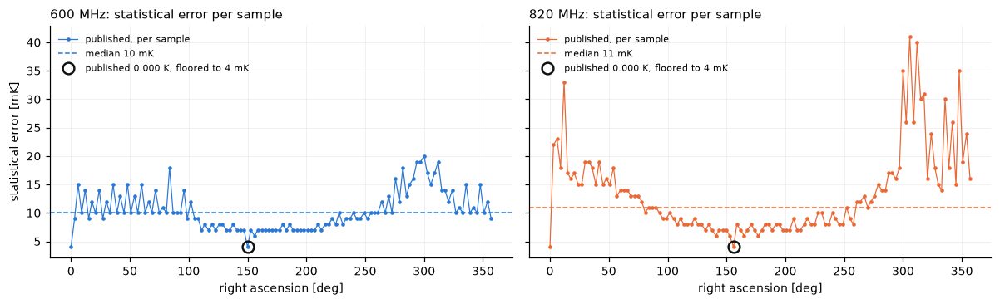

   nu  samples  mean [mK]  median [mK]    min    max  weight span  floored
  600      120      10.42        10.00    4.0   20.0          25x        1
  820      120      13.41        11.00    4.0   41.0         105x        1


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, freq, colour in zip(axes, FREQS, ("#2a78d6", "#eb6834")):
    ra = products["ra_deg"][products.index(freq)]
    published = STAT_ERR[freq]
    floor = float(products.diagnostics(freq)["uncertainty_floor_k"])
    used = np.maximum(published, floor)
    substituted = published <= 0

    ax.plot(ra, 1000 * used, ".-", ms=4, color=colour,
            label="published, per sample")
    ax.axhline(1000 * np.median(used), color=colour, ls="--",
               label=f"median {1000 * np.median(used):.0f} mK")
    ax.plot(ra[substituted], 1000 * used[substituted], "o", ms=9, mfc="none",
            mew=1.6, color="#111111",
            label=f"published 0.000 K, floored to {1000 * floor:.0f} mK")
    ax.set_xlabel("right ascension [deg]")
    ax.set_title(f"{freq} MHz: statistical error per sample", loc="left")
    ax.grid(alpha=0.18, lw=0.6); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="upper left")
axes[0].set_ylabel("statistical error [mK]")
fig.tight_layout()
plt.show()

print(f"{'nu':>5}{'samples':>9}{'mean [mK]':>11}{'median [mK]':>13}{'min':>7}{'max':>7}"
      f"{'weight span':>13}{'floored':>9}")
for freq in FREQS:
    published = STAT_ERR[freq]
    floor = float(products.diagnostics(freq)["uncertainty_floor_k"])
    used = np.maximum(published, floor)
    print(f"{freq:5d}{used.size:9d}{1000 * used.mean():11.2f}"
          f"{1000 * np.median(used):13.2f}{1000 * used.min():7.1f}"
          f"{1000 * used.max():7.1f}{(used.max() / used.min()) ** 2:12.0f}x"
          f"{int((published <= 0).sum()):9d}")

---
### 3. The zero level, and the degeneracy behind it

The zero-level column is all ones, and the sky monopole's response is `beam_coverage`,
which is essentially constant for a normalised beam on a zenith drift scan. So a free zero
level and a free sky monopole are **not separately measurable from one ring** — the split
is set by the priors.

`monopole_degeneracy` (≈1) says how bad that is; `implied_monopole_prior_sigma_k` says
whether the sky prior is tight enough at the monopole for the fitted offset to mean
anything. And Part A's measured GSM2008 deficit says where the offset should land if
it is absorbing the template error rather than measuring the archive.

   nu     fitted zero level [K]   prior σ   pull  GSM2008 deficit  monopole degen.  implied monopole σ
  600          +1.7369 ± 0.0428      0.50   +3.5             1.92      1.000000000              0.0581
  820          +0.5158 ± 0.0271      0.50   +1.0             0.56      1.000000000              0.0322

Read this as: with a per-pixel prior this tight, the nuisance offset is the only
place the template's kelvin-scale error can go. It is a model-mismatch amplitude.


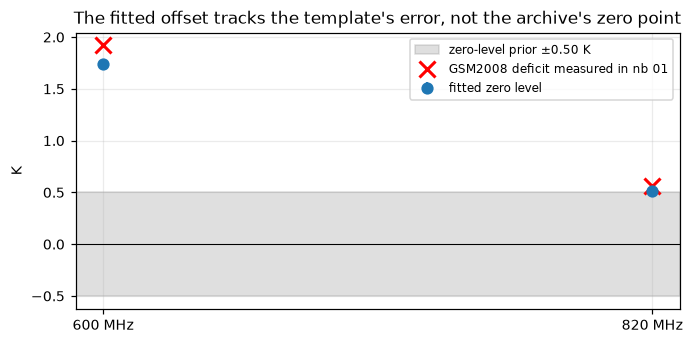

In [5]:
# Measured in Part A and in limTOD's own TRIS walkthrough:
# GSM2008 forward-modelled through this geometry runs cold against the absolute rings.
GSM2008_DEFICIT_K = {600: 1.92, 820: 0.56}

print(f"{'nu':>5}{'fitted zero level [K]':>26}{'prior σ':>10}{'pull':>7}"
      f"{'GSM2008 deficit':>17}{'monopole degen.':>17}{'implied monopole σ':>20}")
for freq in FREQS:
    d = products.diagnostics(freq)
    value = f"{d['zero_level_k']:+.4f} ± {d['zero_level_sigma_k']:.4f}"
    print(f"{freq:5d}{value:>26}{d['zero_level_prior_sigma_k']:10.2f}"
          f"{d['zero_level_pull_prior_sigma']:+7.1f}"
          f"{GSM2008_DEFICIT_K[freq]:17.2f}{d['monopole_degeneracy']:17.9f}"
          f"{d['implied_monopole_prior_sigma_k']:20.4f}")

fig, ax = plt.subplots()
x = np.arange(len(FREQS))
fitted = [products.diagnostics(f)["zero_level_k"] for f in FREQS]
errors = [products.diagnostics(f)["zero_level_sigma_k"] for f in FREQS]
prior_sigma = products.diagnostics(FREQS[0])["zero_level_prior_sigma_k"]
ax.axhspan(-prior_sigma, prior_sigma, color="grey", alpha=0.25,
           label=f"zero-level prior ±{prior_sigma:.2f} K")
ax.errorbar(x, fitted, yerr=errors, fmt="o", ms=7, color="tab:blue",
            label="fitted zero level")
ax.plot(x, [GSM2008_DEFICIT_K[f] for f in FREQS], "rx", ms=10, mew=2,
        label="GSM2008 deficit measured in nb 01")
ax.axhline(0, color=COLORS["ink"], lw=0.7)
ax.set_xticks(x); ax.set_xticklabels([f"{f} MHz" for f in FREQS])
ax.set_ylabel("K"); ax.legend(); ax.grid(alpha=0.25)
ax.set_title("The fitted offset tracks the template's error, not the archive's zero point")
fig.tight_layout()

print("\nRead this as: with a per-pixel prior this tight, the nuisance offset is the only")
print("place the template's kelvin-scale error can go. It is a model-mismatch amplitude.")

---
### 4. Did the data actually move the map?

Two separate questions, and they have different answers:

* **Did the uncertainty shrink?** — the posterior σ against the prior σ. 120 samples
  cannot tighten thousands of pixels, so mostly no.
* **Did the mean move, and is that move consistent?** — the z-score. For a
  linear-Gaussian model the shift of the posterior mean away from the prior mean has
  covariance exactly $S - \Sigma$, so the right standardising width per pixel is
  $\sqrt{\sigma^2_\mathrm{prior} - \sigma^2_\mathrm{post}}$: the variance the data
  actually resolved. Dividing by $\sigma_\mathrm{prior}$ instead understates the tension.

In [6]:
def resolved_z(prior_mean, prior_sigma, post_mean, post_sigma, min_resolved_frac):
    resolved = np.sqrt(np.maximum(prior_sigma**2 - post_sigma**2, 0.0))
    usable = resolved > min_resolved_frac * prior_sigma
    z = np.full(prior_mean.shape, np.nan)
    z[usable] = (post_mean - prior_mean)[usable] / resolved[usable]
    return z, resolved, usable

print(f"{'nu':>5}{'median σ_prior':>16}{'median σ_post':>15}{'median ratio':>14}"
      f"{'pixels tightened >5%':>22}")
for freq in FREQS:
    i = products.index(freq)
    ratio = products["sky_sigma_k"][i] / products["prior_sigma_k"][i]
    print(f"{freq:5d}{np.median(products['prior_sigma_k'][i]):16.4f}"
          f"{np.median(products['sky_sigma_k'][i]):15.4f}{np.median(ratio):14.5f}"
          f"{int((ratio < 0.95).sum()):>13d} / {ratio.size}")

THRESHOLDS = (0.05, 0.01, 1e-3, 1e-4)
print("\nPixels whose RESOLVED width sqrt(σ²prior − σ²post) exceeds this fraction of")
print("σ_prior.  This is a weaker condition than the σ ratio above -- the difference is")
print("in quadrature, so resolving 5% of the prior width only shrinks σ by 0.1%.")
print(f"{'nu':>5}" + "".join(f"{f'>{t:g}':>10}" for t in THRESHOLDS)
      + f"{'of':>10}")
for freq in FREQS:
    i = products.index(freq)
    resolved = np.sqrt(np.maximum(products["prior_sigma_k"][i]**2
                                  - products["sky_sigma_k"][i]**2, 0.0))
    counts = [int((resolved > t * products["prior_sigma_k"][i]).sum())
              for t in THRESHOLDS]
    print(f"{freq:5d}" + "".join(f"{c:10d}" for c in counts) + f"{resolved.size:10d}")
print("\nThe honest headline: the posterior σ is within 0.01% of the prior σ almost")
print("everywhere, so the map is very largely the prior redisplayed. The ring does")
print("resolve a few percent of the prior width across ~10% of the band, and that")
print("small resolved variance is exactly the denominator the z-score below uses.")

   nu  median σ_prior  median σ_post  median ratio  pixels tightened >5%
  600          1.1846         1.1773       0.99848           23 / 1272
  820          0.7162         0.7118       0.99867            7 / 1272

Pixels whose RESOLVED width sqrt(σ²prior − σ²post) exceeds this fraction of
σ_prior.  This is a weaker condition than the σ ratio above -- the difference is
in quadrature, so resolving 5% of the prior width only shrinks σ by 0.1%.
   nu     >0.05     >0.01    >0.001   >0.0001        of
  600       662      1020      1272      1272      1272
  820       647       976      1272      1272      1272

The honest headline: the posterior σ is within 0.01% of the prior σ almost
everywhere, so the map is very largely the prior redisplayed. The ring does
resolve a few percent of the prior width across ~10% of the band, and that
small resolved variance is exactly the denominator the z-score below uses.


600 MHz: z-scores over the 662/1272 pixels that resolved >0.05 of their prior width
   (pixels below that threshold have a denominator consistent with zero, so
    their z carries no information and is excluded rather than plotted huge)
   mean +0.01   std 4.95   |z|>3 in 42% of pixels (N(0,1) would give 0.3%)


Text(0.5, 1.0, '|z| dips where the beam dwelt')

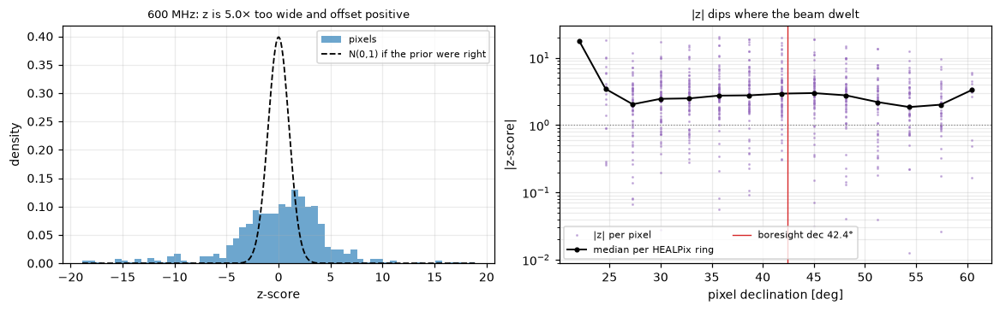

In [7]:
# Pick a threshold that actually leaves pixels to look at, and say which one was used.
FREQ_MAIN = FREQS[0]
i = products.index(FREQ_MAIN)
prior_mean = products["prior_mean_k"][i]
prior_sigma = products["prior_sigma_k"][i]
post_mean = products["sky_k"][i]
post_sigma = products["sky_sigma_k"][i]

MIN_USABLE_PIXELS = 200   # enough to see a distribution, not a fixed fraction
for THRESHOLD in (0.05, 0.01, 1e-3, 1e-4, 1e-6):
    z, resolved, usable = resolved_z(prior_mean, prior_sigma, post_mean, post_sigma,
                                     THRESHOLD)
    if usable.sum() >= MIN_USABLE_PIXELS:
        break
finite = z[np.isfinite(z)]
print(f"{FREQ_MAIN} MHz: z-scores over the {finite.size}/{z.size} pixels that resolved "
      f">{THRESHOLD:g} of their prior width")
print("   (pixels below that threshold have a denominator consistent with zero, so")
print("    their z carries no information and is excluded rather than plotted huge)")
print(f"   mean {finite.mean():+.2f}   std {finite.std():.2f}   "
      f"|z|>3 in {100*np.mean(np.abs(finite) > 3):.0f}% of pixels "
      f"(N(0,1) would give 0.3%)")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2), constrained_layout=True)
ax = axes[0]
lim = float(np.percentile(np.abs(finite), 99.5))
ax.hist(finite, bins=60, range=(-lim, lim), density=True, alpha=0.65, color="tab:blue",
        label="pixels")
grid = np.linspace(-lim, lim, 400)
ax.plot(grid, norm.pdf(grid), "--", color=COLORS["ink"], label="N(0,1) if the prior were right")
ax.set_xlabel("z-score"); ax.set_ylabel("density"); ax.legend()
ax.grid(alpha=0.25)
ax.set_title(f"{FREQ_MAIN} MHz: z is {finite.std():.1f}× too wide"
             + (" and offset positive" if finite.mean() > 0 else ""))

ax = axes[1]
dec_pix = 90 - np.rad2deg(hp.pix2ang(NSIDE, products.pixel_indices)[0])
ax.plot(dec_pix[usable], np.abs(z[usable]), ".", ms=2, color="tab:purple", alpha=0.4,
        label="|z| per pixel")
rings = np.unique(np.round(dec_pix[usable], 3))
median = np.array([np.median(np.abs(z[usable][np.round(dec_pix[usable], 3) == r]))
                   for r in rings])
ax.plot(rings, median, "o-", ms=3, color=COLORS["ink"], label="median per HEALPix ring")
ax.axhline(1.0, color="grey", ls=":")
ax.axvline(BORESIGHT_DEC, color="tab:red",
           label=f"boresight dec {BORESIGHT_DEC:.1f}°")
ax.set_yscale("log")
ax.set_xlabel("pixel declination [deg]"); ax.set_ylabel("|z-score|")
ax.legend(ncol=2); ax.grid(alpha=0.25, which="both")
ax.set_title("|z| dips where the beam dwelt")

#### The band, drawn

The solved region is a declination band, so a Mollweide projection would spend half its
area on sky that was never fitted. These panels project just the band, keeping HEALPix
pixel boundaries (`interpolation="nearest"`), with grey for pixels outside it. Prior and
posterior share a colour scale so the comparison is honest.

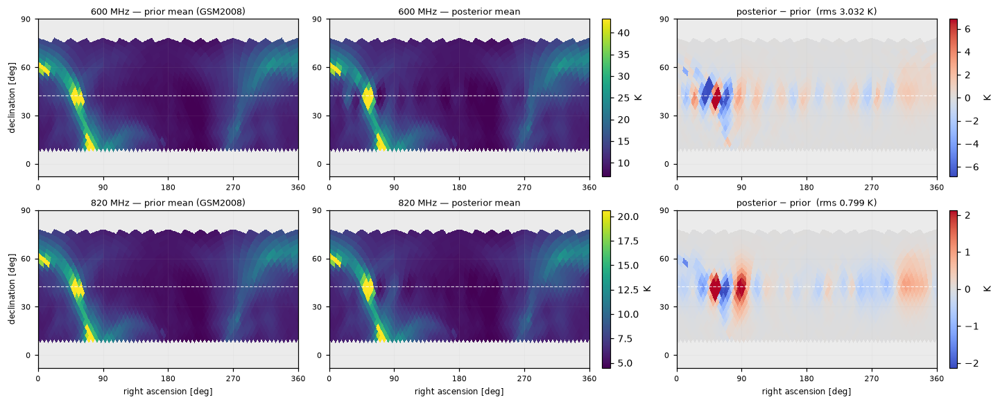

In [8]:
LATRA, LONRA = [-8, 90], [-180, 180]
EXTENT = [LONRA[0], LONRA[1], LATRA[0], LATRA[1]]

def band_image(values):
    full = np.full(hp.nside2npix(NSIDE), np.nan)
    full[products.pixel_indices] = values
    img = hp.cartview(full, lonra=LONRA, latra=LATRA, rot=[180, 0, 0], xsize=1200,
                      return_projected_map=True, hold=False)
    plt.close()
    return np.asarray(img)

def show_band(ax, values, cmap, title, **kw):
    im = ax.imshow(band_image(values), origin="lower", extent=EXTENT, aspect="auto",
                   cmap=cmap, interpolation="nearest", **kw)
    ax.set_title(title, pad=4)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xticklabels(["0", "90", "180", "270", "360"])
    ax.set_yticks([0, 30, 60, 90])
    ax.set_facecolor("0.92")
    ax.axhline(BORESIGHT_DEC, color="w", ls="--", alpha=0.8)
    ax.grid(alpha=0.15, lw=0.4)
    return im

fig, axes = plt.subplots(len(FREQS), 3, figsize=(13, 2.6 * len(FREQS)),
                         constrained_layout=True, squeeze=False)
for row, freq in enumerate(FREQS):
    i = products.index(freq)
    lo, hi = np.percentile(products["prior_mean_k"][i], [1, 99])
    im_m = show_band(axes[row, 0], products["prior_mean_k"][i], "ring",
                     f"{freq} MHz — prior mean (GSM2008)", vmin=lo, vmax=hi)
    show_band(axes[row, 1], products["sky_k"][i], "ring",
              f"{freq} MHz — posterior mean", vmin=lo, vmax=hi)
    change = products["sky_k"][i] - products["prior_mean_k"][i]
    clim = float(np.percentile(np.abs(change), 99))
    im_d = show_band(axes[row, 2], change, "coolwarm",
                     f"posterior − prior  (rms {change.std():.3f} K)",
                     vmin=-clim, vmax=clim)
    fig.colorbar(im_m, ax=list(axes[row, :2]), fraction=0.025, pad=0.01, label="K")
    fig.colorbar(im_d, ax=axes[row, 2], fraction=0.045, pad=0.02, label="K")
for ax in axes[-1]:
    ax.set_xlabel("right ascension [deg]")
for ax in axes[:, 0]:
    ax.set_ylabel("declination [deg]")

---
### 5. Is this fit to use?

Two checks that matter downstream.

**The spectral index between the two solved maps.** If stage 1's own two-frequency product
implies something wildly outside the Galactic synchrotron range (−2.5 to −3.0), that is a red flag about
the maps, not a discovery. Note this is *not* independent of the prior: both maps are
largely GSM2008, so the template's own β is plotted alongside.

**The degrade to `beam.nside_new`.** A preview of the maps on the common grid; a reader of the product decides how
to fill pixels the band never covered.

stage 1 maps       median β = -2.702   16-84% [-2.804, -2.587]    82.7% inside [-3.0, -2.5]
GSM2008 template   median β = -2.700   16-84% [-2.702, -2.698]   100.0% inside [-3.0, -2.5]


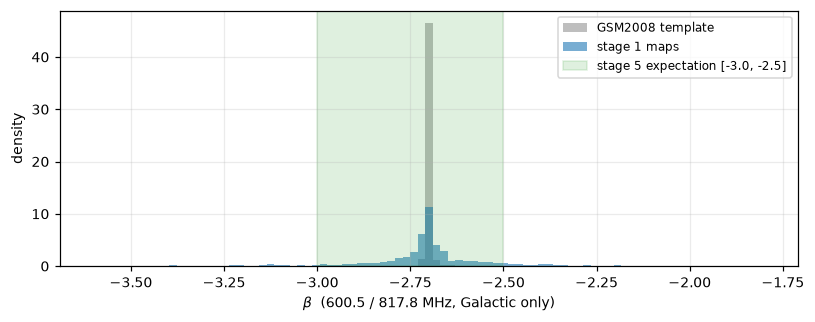

In [9]:
lo_i, hi_i = products.index(FREQS[0]), products.index(FREQS[-1])
nu_lo = products["effective_freq_mhz"][lo_i]
nu_hi = products["effective_freq_mhz"][hi_i]

def spectral_index(t_lo, t_hi):
    # Galactic-only: the TRIS convention includes the CMB monopole, so remove it
    # before taking a ratio or beta comes out meaningless.
    g_lo = t_lo - tris.cmb_monopole_rj_k(nu_lo)
    g_hi = t_hi - tris.cmb_monopole_rj_k(nu_hi)
    good = (g_lo > 0) & (g_hi > 0)
    beta = np.full(t_lo.shape, np.nan)
    beta[good] = np.log(g_lo[good] / g_hi[good]) / np.log(nu_lo / nu_hi)
    return beta

beta_post = spectral_index(products["sky_k"][lo_i], products["sky_k"][hi_i])
beta_prior = spectral_index(products["prior_mean_k"][lo_i],
                            products["prior_mean_k"][hi_i])
expected = config.require("validate.beta_range")

for label, beta in (("stage 1 maps", beta_post), ("GSM2008 template", beta_prior)):
    finite_beta = beta[np.isfinite(beta)]
    inside = np.mean((finite_beta >= expected[0]) & (finite_beta <= expected[1]))
    print(f"{label:18s} median β = {np.median(finite_beta):+.3f}   "
          f"16-84% [{np.percentile(finite_beta, 16):+.3f}, "
          f"{np.percentile(finite_beta, 84):+.3f}]   "
          f"{100*inside:5.1f}% inside {expected}")

fig, ax = plt.subplots()
bins = np.linspace(-3.6, -1.8, 90)
ax.hist(beta_prior[np.isfinite(beta_prior)], bins=bins, alpha=0.5, density=True,
        color="tab:grey", label="GSM2008 template")
ax.hist(beta_post[np.isfinite(beta_post)], bins=bins, alpha=0.6, density=True,
        color="tab:blue", label="stage 1 maps")
ax.axvspan(expected[0], expected[1], color="tab:green", alpha=0.15,
           label=f"stage 5 expectation {expected}")
ax.set_xlabel(rf"$\beta$  ({nu_lo:.1f} / {nu_hi:.1f} MHz, Galactic only)")
ax.set_ylabel("density"); ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()

stage 3 target grid: nside 16, 3072 pixels, 1272 touched by the band
sky_lowres preview shape would be (2, 1272) (Nfreq, npix touched); bayesian_skymap wants (Nfreq-1, npix_new)
fully covered coarse pixels: 1272, partially covered: 0

The partial ones are stage 3's decision, not stage 1's: they mix solved sky
with pixels the band never reached.


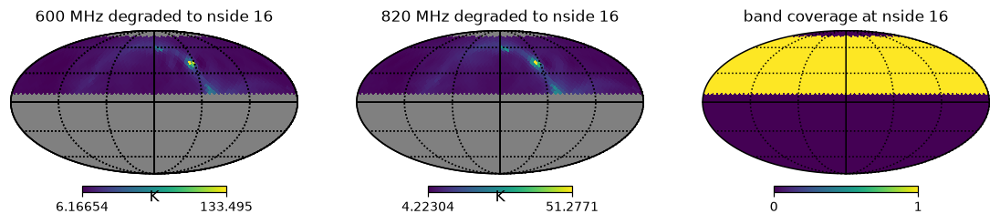

In [10]:
NSIDE_NEW = int(config.require("beam.nside_new"))

# Degrade by averaging only the band pixels each coarse pixel actually contains.
band = products["band_mask"]
coverage = hp.ud_grade(band.astype(float), NSIDE_NEW)
low_res = np.full((len(FREQS), hp.nside2npix(NSIDE_NEW)), np.nan)
for row, freq in enumerate(FREQS):
    filled = np.where(band, np.nan_to_num(products["sky_full_k"][row]), 0.0)
    summed = hp.ud_grade(filled, NSIDE_NEW)
    with np.errstate(invalid="ignore", divide="ignore"):
        low_res[row] = np.where(coverage > 0, summed / coverage, np.nan)

observed = coverage > 0
print(f"stage 3 target grid: nside {NSIDE_NEW}, {hp.nside2npix(NSIDE_NEW)} pixels, "
      f"{int(observed.sum())} touched by the band")
print(f"sky_lowres preview shape would be {low_res[:, observed].shape} "
      f"(Nfreq, npix touched)")
print(f"fully covered coarse pixels: {int((coverage > 0.999).sum())}, "
      f"partially covered: {int(((coverage > 0) & (coverage <= 0.999)).sum())}")
print("\nThe partial ones are stage 3's decision, not stage 1's: they mix solved sky")
print("with pixels the band never reached.")

fig, axes = plt.subplots(1, len(FREQS) + 1, figsize=(4.2 * (len(FREQS) + 1), 3.0))
for ax, freq, row in zip(axes, FREQS, range(len(FREQS))):
    plt.sca(ax)
    hp.mollview(np.where(np.isnan(low_res[row]), hp.UNSEEN, low_res[row]),
                title=f"{freq} MHz degraded to nside {NSIDE_NEW}", unit="K",
                hold=True, cbar=True, notext=True)
    hp.graticule(dpar=30, dmer=60)
plt.sca(axes[-1])
hp.mollview(coverage, title=f"band coverage at nside {NSIDE_NEW}", hold=True,
            cbar=True, notext=True, min=0, max=1)
hp.graticule(dpar=30, dmer=60)
fig.tight_layout()

---
### Verdict

Read the numbers above in this order:

1. **The solve was sound when last checked.** With the cross-check on, limTOD's answer
   agreed with the exact reference to far better than a posterior σ (~1e-10 σ), at both
   frequencies. The cross-check is switched off, so the current product is not verified
   this way.
2. **The model does not describe the ring** — reduced χ² of tens, with coherent
   structure in the residual. That is a statement about GSM2008, not about the map-maker.
3. **The fitted zero level reproduces the template's own deficit** (~1.9 K at 600 MHz,
   ~0.6 K at 820 MHz, measured independently in Part A). With a per-pixel prior this
   tight and a monopole degeneracy of ≈1, the nuisance offset is the only place a
   template error can go. Read it as a model-mismatch amplitude, **not** as a measurement
   of the archive's zero point.
4. **The map is largely the prior, redisplayed.** The posterior σ barely moves off the
   prior σ, and the z-scores are far wider than N(0,1) and skewed — the ring is
   systematically pulling the map away from GSM2008 in the directions it can see.

None of that is a stage 1 bug; it is what one absolutely-calibrated ring plus a template
that is kelvins off can support. The honest product of this stage is the *difference*
between TRIS and the template.

**What would change it.** A Haslam-independent prior replacing GSM2008 as both template and truth. Until then,
`prior_equals_truth` is `True` in the manifest and agreement with `truth_k` is circular by construction.

---
## Prior-only runs, and what the data actually moved

Every map in this notebook is a *posterior*: prior times likelihood. With 120 samples
carrying roughly 15 independent numbers against 1273 free parameters, the obvious
question is how much of what we are looking at is the data at all.

The clean way to answer it is to run the pipeline with the data switched off. Setting
`tris.uncertainty_floor_k` to an enormous value makes every sample's noise RMS huge —
limTOD applies the floor with `numpy.maximum`, so it overrides every published error —
the likelihood goes flat, and the posterior must collapse onto the prior exactly.

That gives a **baseline map to difference against**. Anything the real run does that the
prior-only run does not do is, by construction, the data speaking.

In [11]:
PRIOR_ONLY = REPO / "outputs" / "stage1_nside16_prior_only"
prior_only = load_stage1(config,
                         maps_path=PRIOR_ONLY / "tris_maps_tris_haslam_v0.npz",
                         manifest_path=PRIOR_ONLY / "stage1_manifest.json")
HIGH_NOISE = REPO / "outputs" / "stage1_nside16_high_noise"
high_noise = load_stage1(config,
                         maps_path=HIGH_NOISE / "tris_maps_tris_haslam_v0.npz",
                         manifest_path=HIGH_NOISE / "stage1_manifest.json")

# Every run differences against the prior-only baseline ON ITS OWN GRID -- a
# residual taken across two pixelisations is not a residual.
RUNS = {
    "nside 16 (default)": products,
    "very high noise":   high_noise,
    "prior only":        prior_only,
}
for name, run in RUNS.items():
    assert run.nside == products.nside, f"{name} is on nside {run.nside}"
    assert np.array_equal(run.pixel_indices, products.pixel_indices), name
    cfg_used = run.manifest["config_used"]["tris"]
    print(f"{name:<24} nside {run.nside:3d}  {run.pixel_indices.size:5d} pixels  "
          f"noise floor {cfg_used['uncertainty_floor_k'] or 'auto':>9}")

nside 16 (default)       nside  16   1272 pixels  noise floor      auto
very high noise          nside  16   1272 pixels  noise floor       1.0
prior only               nside  16   1272 pixels  noise floor       1e6


#### First: does the prior-only run really collapse onto the prior?

If this does not come back at machine precision, nothing below it means anything.

In [12]:
print(f"{'nu':>5}{'max |map - prior|':>20}{'in prior sigma':>17}"
      f"{'max |sigma/prior - 1|':>23}{'zero level [K]':>17}{'red. chi2':>12}")
for freq in FREQS:
    p = prior_only
    i = p.index(freq)
    dmap = np.abs(p["sky_k"][i] - p["prior_mean_k"][i])
    dsig = np.abs(p["sky_sigma_k"][i] - p["prior_sigma_k"][i]) / p["prior_sigma_k"][i]
    d = p.diagnostics(freq)
    print(f"{freq:5d}{dmap.max():20.2e}{np.max(dmap / p['prior_sigma_k'][i]):17.2e}"
          f"{dsig.max():23.2e}{d['zero_level_k']:+17.2e}"
          f"{d['reduced_chi_square']:12.2e}")
print("\nThe map returns the prior mean, the posterior sigma returns the prior sigma,")
print("the zero level returns its prior mean of 0, and chi2 goes to 0 because the")
print("residuals are divided by an enormous noise. The switch works.")

   nu   max |map - prior|   in prior sigma  max |sigma/prior - 1|   zero level [K]   red. chi2
  600            3.14e-09         4.60e-10               2.34e-11        +6.00e-11    4.34e-12
  820            3.20e-10         1.00e-10               5.11e-12        +1.81e-11    4.61e-13

The map returns the prior mean, the posterior sigma returns the prior sigma,
the zero level returns its prior mean of 0, and chi2 goes to 0 because the
residuals are divided by an enormous noise. The switch works.


#### What the data moved

Now difference the real run against that baseline. The unit is the **prior** σ: a shift
of 1 σ means the data moved that pixel by as much as the prior's own width, which is the
only scale on which "the data said something" is a meaningful claim.

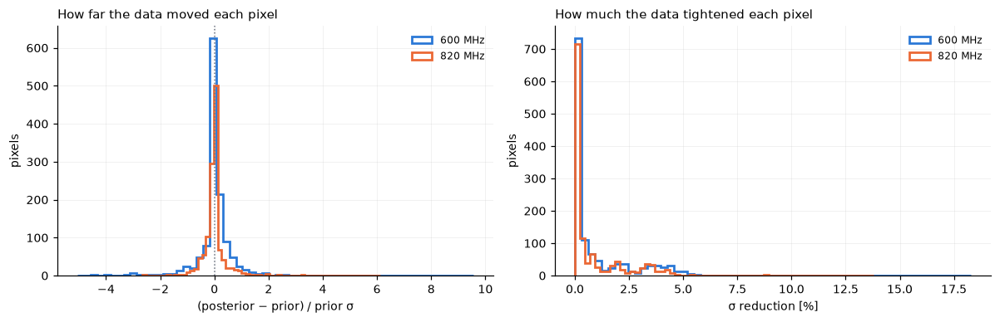

   nu  median |shift|   max |shift|   median pull   max pull  median tighten  max tighten
  600          0.135K       65.307K         0.106      9.568           0.15%       18.30%
  820          0.056K       19.509K         0.072      6.114           0.13%       13.79%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
GRID_COLOUR = {600: "#2a78d6", 820: "#eb6834"}

summary = []
for freq in FREQS:
    i_r, i_p = products.index(freq), prior_only.index(freq)
    shift = (products["sky_k"][i_r] - prior_only["sky_k"][i_p])
    pull = shift / products["prior_sigma_k"][i_r]
    tighten = 1.0 - products["sky_sigma_k"][i_r] / products["prior_sigma_k"][i_r]
    summary.append((freq, shift, pull, tighten))

    axes[0].hist(pull, bins=60, histtype="step", lw=1.8,
                 color=GRID_COLOUR[freq], label=f"{freq} MHz")
    axes[1].hist(100 * tighten, bins=60, histtype="step", lw=1.8,
                 color=GRID_COLOUR[freq], label=f"{freq} MHz")

axes[0].set_xlabel("(posterior − prior) / prior σ")
axes[0].set_ylabel("pixels")
axes[0].set_title("How far the data moved each pixel", loc="left")
axes[0].axvline(0, color="#6b7280", ls=":")
axes[1].set_xlabel("σ reduction [%]")
axes[1].set_ylabel("pixels")
axes[1].set_title("How much the data tightened each pixel", loc="left")
for ax in axes:
    ax.grid(alpha=0.18, lw=0.6); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend()
fig.tight_layout()
plt.show()

print(f"{'nu':>5}{'median |shift|':>16}{'max |shift|':>14}{'median pull':>14}"
      f"{'max pull':>11}{'median tighten':>16}{'max tighten':>13}")
for freq, shift, pull, tighten in summary:
    print(f"{freq:5d}{np.median(np.abs(shift)):15.3f}K{np.abs(shift).max():13.3f}K"
          f"{np.median(np.abs(pull)):14.3f}{np.abs(pull).max():11.3f}"
          f"{100 * np.median(tighten):15.2f}%{100 * tighten.max():12.2f}%")

#### Where on the sky the data spoke

The histograms say how much; this says where. A drift scan weights the sky by how long
the beam dwelt on it, so the map should be most informative along the band centre and
fall away at the edges — and the plane, being bright, should pull hardest.

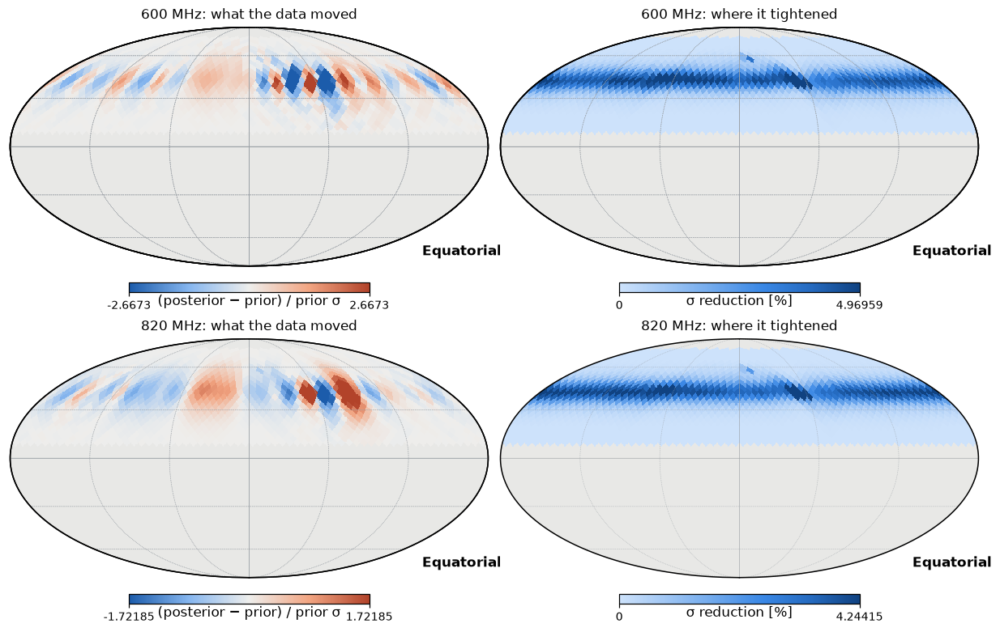

In [14]:
from matplotlib.colors import LinearSegmentedColormap
DIV = plt.get_cmap("ring_div").copy()         # two hues + a NEUTRAL midpoint
DIV.set_bad("#e8e8e6")
# healpy paints the area OUTSIDE the projection with the colormap's
# "under" colour, not with bgcolor -- without this the map sits on a
# slab of the ramp's darkest tone, which reads as data.
DIV.set_under("white")
SEQ = plt.get_cmap("ring").copy()
SEQ.set_bad("#e8e8e6")
SEQ.set_under("white")

fig = plt.figure(figsize=(11, 7))
panel = 1
for freq in FREQS:
    i_r, i_p = products.index(freq), prior_only.index(freq)
    pull = np.full(hp.nside2npix(NSIDE), np.nan)
    pull[products.pixel_indices] = (
        (products["sky_k"][i_r] - prior_only["sky_k"][i_p])
        / products["prior_sigma_k"][i_r])
    tighten = np.full(hp.nside2npix(NSIDE), np.nan)
    tighten[products.pixel_indices] = 100 * (
        1.0 - products["sky_sigma_k"][i_r] / products["prior_sigma_k"][i_r])

    span = np.nanpercentile(np.abs(pull), 98)
    hp.mollview(pull, coord="C", cmap=DIV, min=-span, max=span,
                unit="(posterior − prior) / prior σ",
                title=f"{freq} MHz: what the data moved", sub=(2, 2, panel),
                fig=fig.number, badcolor="#e8e8e6")
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
    hp.mollview(tighten, coord="C", min=0,
                max=np.nanpercentile(tighten, 98), unit="σ reduction [%]",
                title=f"{freq} MHz: where it tightened", sub=(2, 2, panel + 1),
                fig=fig.number, badcolor="#e8e8e6")
    hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
    panel += 2
plt.show()

#### The same question, as a fraction of the whole map

One number for the summary: of the total structure in the original map, how much
survives when the data is switched off? A map that is *all* prior scores 1.0.

In [15]:
print(f"{'nu':>5}{'rms(posterior)':>17}{'rms(prior)':>13}{'rms(difference)':>18}"
      f"{'prior fraction':>16}{'corr(post, prior)':>19}")
for freq in FREQS:
    i_r, i_p = products.index(freq), prior_only.index(freq)
    post = products["sky_k"][i_r]
    pri = prior_only["sky_k"][i_p]
    diff = post - pri
    frac = 1.0 - diff.std() / post.std()
    print(f"{freq:5d}{post.std():16.4f}K{pri.std():12.4f}K{diff.std():17.4f}K"
          f"{frac:16.4f}{np.corrcoef(post, pri)[0, 1]:19.6f}")
print("\n'prior fraction' is 1 - rms(posterior - prior)/rms(posterior): the share of")
print("the map's structure that is there before the data is looked at.")

   nu   rms(posterior)   rms(prior)   rms(difference)  prior fraction  corr(post, prior)
  600          7.9459K      6.4857K           3.0325K          0.6184           0.931466
  820          3.1797K      2.8349K           0.7990K          0.7487           0.971184

'prior fraction' is 1 - rms(posterior - prior)/rms(posterior): the share of
the map's structure that is there before the data is looked at.


#### The original run against a very high noise run

Prior-only is the degenerate limit: the data carries no weight at all and the posterior
returns the prior exactly, which is a useful check but shows nothing about *how* the data
enters. This is the informative version — the noise RMS replaced by a flat **1.0 K** on every sample, which is

* **~100×** the published per-sample statistical errors, whose median is
  10 mK at 600 MHz and 11 mK at 820 MHz (they run 4–20 and 4–41 mK), and
* **0.84×** the median prior width, so the data and the prior carry comparable weight.

The data is still in the fit; it has simply been told it is 250 times less trustworthy.
Same grid, same prior, same pixels — the only change is the noise.

**Top:** the mean posterior map in each case. **Bottom:** the residual each run leaves
against the ring it was fitting, `data − operator @ parameters`, sample by sample in RA.
The residual panels share a y axis, because their amplitudes are the comparison.

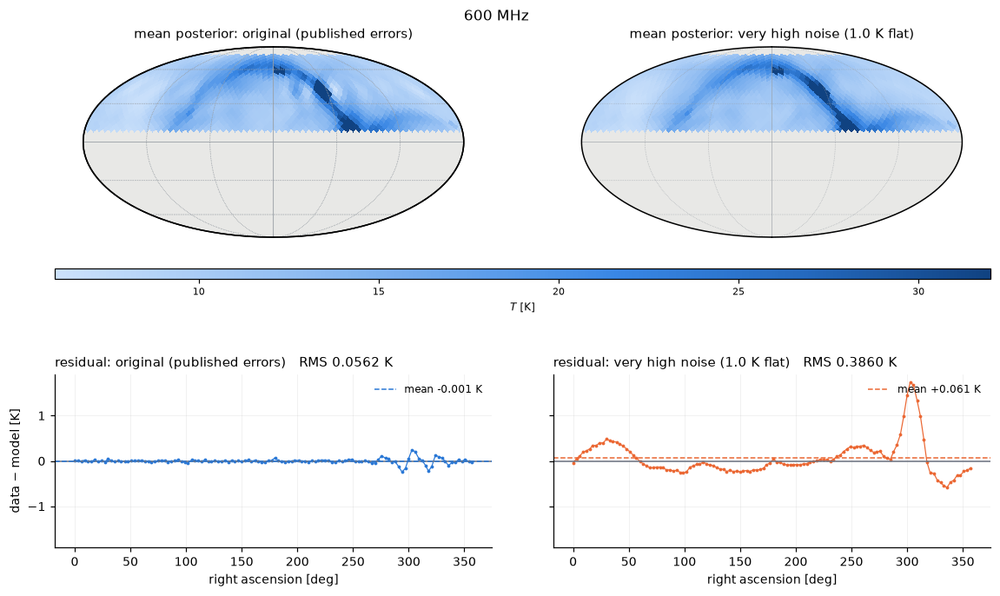

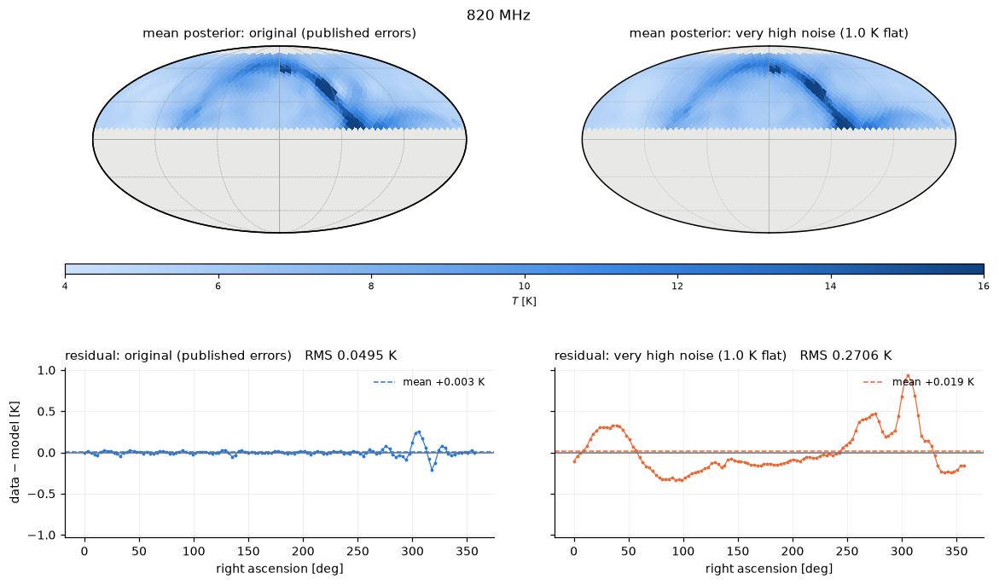

   nu  case                            map mean [K]  map sigma [K]  resid RMS [K]  resid mean [K]  zero level [K]
  600  original (published errors)          13.1783         7.9459         0.0562         -0.0009         +1.7369
  600  very high noise (1.0 K flat)         13.1345         6.7045         0.3860         +0.0611         +1.8334
         rms(map - prior), original (published errors)        3.0339
         rms(map - prior), very high noise (1.0 K flat)        0.3997

  820  original (published errors)           7.2473         3.1797         0.0495         +0.0031         +0.5158
  820  very high noise (1.0 K flat)          7.2222         2.8695         0.2706         +0.0190         +0.5699
         rms(map - prior), original (published errors)        0.7997
         rms(map - prior), very high noise (1.0 K flat)        0.0620



In [16]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# healpy sizes its own axes and steals room for a colorbar, so panels drawn with
# sub= land at different heights.  Lay the axes out here and give the colour bar
# its own slot.  notext=True drops healpy's corner coordinate stamp.
CASES = {"original (published errors)": (products, "#2a78d6"),
         "very high noise (1.0 K flat)": (high_noise, "#eb6834")}

for freq in FREQS:
    maps = {name: run["sky_full_k"][run.index(freq)] for name, (run, _) in CASES.items()}
    resid = {name: run["residual_k"][run.index(freq)] for name, (run, _) in CASES.items()}
    ra = products["ra_deg"][products.index(freq)]

    vlo = np.floor(min(np.nanpercentile(m, 2) for m in maps.values()))
    vhi = np.ceil(max(np.nanpercentile(m, 98) for m in maps.values()))
    rmax = max(np.abs(r).max() for r in resid.values()) * 1.1

    fig = plt.figure(figsize=(11, 6.4))
    # Row 2 is an empty spacer: without it the colour bar's label crowds the
    # residual panel titles directly beneath it.
    gs = fig.add_gridspec(4, 2, height_ratios=[1, 0.05, 0.18, 0.9],
                          hspace=0.30, wspace=0.14,
                          left=0.08, right=0.97, top=0.90, bottom=0.08)

    for column, (name, m) in enumerate(maps.items()):
        plt.sca(fig.add_subplot(gs[0, column]))
        hp.mollview(m, coord="C", min=vlo, max=vhi, hold=True,
                    cbar=False, notext=True, title="", badcolor="#e8e8e6")
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
        fig.axes[-1].set_title(f"mean posterior: {name}", pad=6)

    cb = fig.colorbar(ScalarMappable(Normalize(vlo, vhi), SEQ),
                      cax=fig.add_subplot(gs[1, :]), orientation="horizontal")
    cb.set_label("$T$ [K]")

    for column, (name, r) in enumerate(resid.items()):
        ax = fig.add_subplot(gs[3, column])
        colour = CASES[name][1]
        ax.plot(ra, r, ".-", ms=3, color=colour)
        ax.axhline(0, color="#6b7280")
        ax.axhline(r.mean(), color=colour, ls="--",
                   label=f"mean {r.mean():+.3f} K")
        ax.set_ylim(-rmax, rmax)
        ax.set_xlabel("right ascension [deg]")
        ax.set_title(f"residual: {name}   RMS {r.std():.4f} K",
                     loc="left")
        ax.grid(alpha=0.18, lw=0.6); ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.legend(loc="upper right")
        if column == 0:
            ax.set_ylabel("data − model [K]")
        else:
            ax.tick_params(labelleft=False)

    fig.suptitle(f"{freq} MHz", y=0.96)
    plt.show()

print(f"{'nu':>5}  {'case':<30}{'map mean [K]':>14}{'map sigma [K]':>15}"
      f"{'resid RMS [K]':>15}{'resid mean [K]':>16}{'zero level [K]':>16}")
for freq in FREQS:
    for name, (run, _) in CASES.items():
        i = run.index(freq)
        m, r = run["sky_k"][i], run["residual_k"][i]
        print(f"{freq:5d}  {name:<30}{m.mean():14.4f}{m.std():15.4f}"
              f"{r.std():15.4f}{r.mean():+16.4f}"
              f"{run.diagnostics(freq)['zero_level_k']:+16.4f}")
    # How far each run sits from the prior it started from -- 0 would mean the
    # data changed nothing, i.e. the prior-only limit.
    for name, (run, _) in CASES.items():
        i = run.index(freq)
        dev = float(np.sqrt(np.mean((run["sky_k"][i] - run["prior_mean_k"][i]) ** 2)))
        print(f"{'':5}  {'  rms(map - prior), ' + name:<30}{dev:14.4f}")
    print()

#### Per-pixel σ, and what the noise inflation cost the map

Three panels per frequency, all on maps this time.

**Left and middle:** the per-pixel posterior σ — the `sky_sigma_k` the solver returns for
every pixel — for each case, on a shared scale. This is the map's own error bar, pixel by
pixel, and it is what the SED fit should weight by.

**Right:** the difference of the two posterior means. Everywhere this is non-zero, the
250× noise inflation changed the answer.

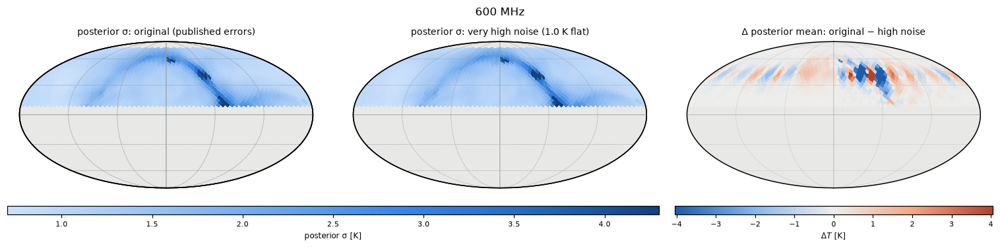

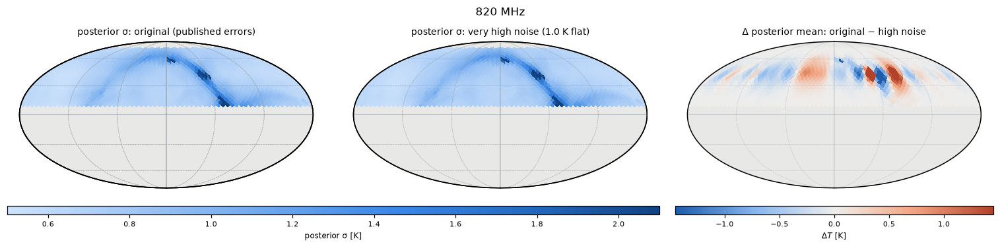

   nu  case                            median σ [K]    min σ    max σ  vs prior σ
  600  prior σ (the starting point)          1.1846   0.7165   6.8254      1.0000
  600  original (published errors)           1.1773   0.7132   6.1499      0.9985
  600  very high noise (1.0 K flat)          1.1843   0.7164   6.5480      0.9999
       Δ posterior mean: rms                 2.7449  max |Δ|  57.2648

  820  prior σ (the starting point)          0.7162   0.5288   3.1910      1.0000
  820  original (published errors)           0.7118   0.5226   2.8790      0.9987
  820  very high noise (1.0 K flat)          0.7162   0.5288   3.1471      1.0000
       Δ posterior mean: rms                 0.7562  max |Δ|  18.3047



In [17]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def as_full(run, key, freq):
    """Scatter a band array back onto a full-sky map, NaN off-band."""
    full = np.full(hp.nside2npix(run.nside), np.nan)
    full[run.pixel_indices] = run[key][run.index(freq)]
    return full

for freq in FREQS:
    sig = {name: as_full(run, "sky_sigma_k", freq) for name, (run, _) in CASES.items()}
    prior_sig = as_full(products, "prior_sigma_k", freq)
    names = list(CASES)
    diff = (as_full(products, "sky_k", freq)
            - as_full(high_noise, "sky_k", freq))

    slo = float(np.floor(min(np.nanmin(s) for s in sig.values()) * 10) / 10)
    shi = float(np.ceil(max(np.nanpercentile(s, 99) for s in sig.values()) * 10) / 10)
    dspan = float(np.nanpercentile(np.abs(diff), 98))

    fig = plt.figure(figsize=(14, 3.6))
    gs = fig.add_gridspec(3, 3, height_ratios=[1, 0.055, 0.12],
                          hspace=0.30, wspace=0.05,
                          left=0.015, right=0.985, top=0.84, bottom=0.04)

    panels = [(f"posterior σ: {names[0]}", sig[names[0]], SEQ, slo, shi),
              (f"posterior σ: {names[1]}", sig[names[1]], SEQ, slo, shi),
              ("Δ posterior mean: original − high noise", diff, DIV, -dspan, dspan)]
    for column, (title, m, cmap, a, b) in enumerate(panels):
        plt.sca(fig.add_subplot(gs[0, column]))
        hp.mollview(m, coord="C", cmap=cmap, min=a, max=b, hold=True,
                    cbar=False, notext=True, title="", badcolor="#e8e8e6")
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
        fig.axes[-1].set_title(title, pad=6)

    cb = fig.colorbar(ScalarMappable(Normalize(slo, shi), SEQ),
                      cax=fig.add_subplot(gs[1, 0:2]), orientation="horizontal")
    cb.set_label("posterior σ [K]")
    cb2 = fig.colorbar(ScalarMappable(Normalize(-dspan, dspan), DIV),
                       cax=fig.add_subplot(gs[1, 2]), orientation="horizontal")
    cb2.set_label("$\\Delta T$ [K]")
    for c_ in (cb, cb2):
        c_.ax.tick_params()
    fig.suptitle(f"{freq} MHz", y=0.97)
    plt.show()

print(f"{'nu':>5}  {'case':<30}{'median σ [K]':>14}{'min σ':>9}{'max σ':>9}"
      f"{'vs prior σ':>12}")
for freq in FREQS:
    p_sig = products["prior_sigma_k"][products.index(freq)]
    print(f"{freq:5d}  {'prior σ (the starting point)':<30}"
          f"{np.median(p_sig):14.4f}{p_sig.min():9.4f}{p_sig.max():9.4f}{1.0:12.4f}")
    for name, (run, _) in CASES.items():
        s_ = run["sky_sigma_k"][run.index(freq)]
        print(f"{freq:5d}  {name:<30}{np.median(s_):14.4f}{s_.min():9.4f}"
              f"{s_.max():9.4f}{np.median(s_ / p_sig):12.4f}")
    d = (products["sky_k"][products.index(freq)]
         - high_noise["sky_k"][high_noise.index(freq)])
    print(f"{'':5}  {'Δ posterior mean: rms':<30}{np.sqrt(np.mean(d**2)):14.4f}"
          f"{'max |Δ|':>9}{np.abs(d).max():9.4f}")
    print()

#### Per-pixel RMS error, and what the noise inflation cost it

σ is only the spread of the posterior about its own mean. The RMS error also counts
how far that mean sits from the reference map:

$$\mathrm{RMS} = \sqrt{\sigma^2 + (\mu - T_\mathrm{ref})^2}$$

where $T_\mathrm{ref}$ is `truth_k`. Here that is the GSM2008 template, **which is also
the prior mean** (`prior_equals_truth` in the manifest), so this RMS measures how far the
posterior sits from the prior, spread included. It is not an error against the real sky.

**Left and middle:** the per-pixel RMS for each case, on a shared scale. **Right:** the
difference in RMS between the two cases. Where it is positive, the original run sits further
from the reference than the high-noise run.

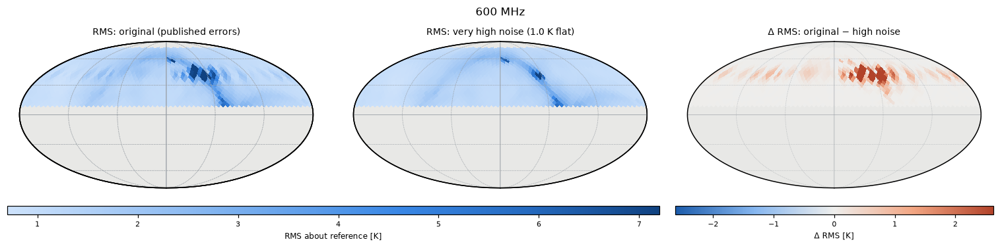

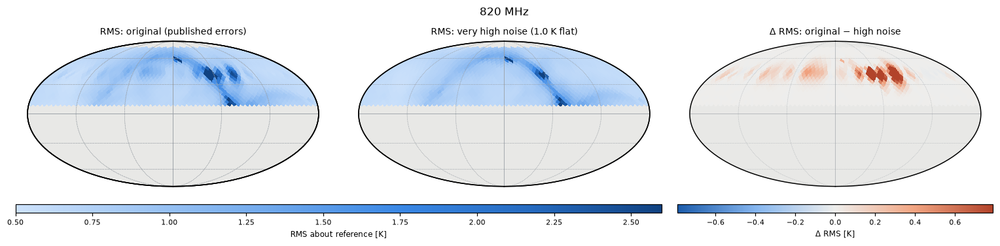

   nu  case                            median RMS [K]      min      max  band RMS [K]  vs prior σ
  600  original (published errors)             1.2437   0.7140  65.5471        3.3694      1.0030
  600  very high noise (1.0 K flat)            1.1846   0.7164  10.3711        1.5399      1.0000

  820  original (published errors)             0.7379   0.5272  19.7057        1.1464      1.0007
  820  very high noise (1.0 K flat)            0.7162   0.5288   3.3696        0.8329      1.0000



In [18]:
def rms_full(run, freq):
    """Per-pixel RMS about the reference map, sqrt(sigma^2 + bias^2), NaN off-band."""
    bias = as_full(run, "sky_k", freq) - as_full(run, "truth_k", freq)
    return np.sqrt(as_full(run, "sky_sigma_k", freq) ** 2 + bias ** 2)

for freq in FREQS:
    rms = {name: rms_full(run, freq) for name, (run, _) in CASES.items()}
    names = list(CASES)
    drms = rms[names[0]] - rms[names[1]]

    rlo = float(np.floor(min(np.nanmin(r) for r in rms.values()) * 10) / 10)
    rhi = float(np.ceil(max(np.nanpercentile(r, 99) for r in rms.values()) * 10) / 10)
    dspan = float(np.nanpercentile(np.abs(drms), 98))

    fig = plt.figure(figsize=(14, 3.6))
    gs = fig.add_gridspec(3, 3, height_ratios=[1, 0.055, 0.12],
                          hspace=0.30, wspace=0.05,
                          left=0.015, right=0.985, top=0.84, bottom=0.04)

    panels = [(f"RMS: {names[0]}", rms[names[0]], SEQ, rlo, rhi),
              (f"RMS: {names[1]}", rms[names[1]], SEQ, rlo, rhi),
              ("Δ RMS: original − high noise", drms, DIV, -dspan, dspan)]
    for column, (title, m, cmap, a, b) in enumerate(panels):
        plt.sca(fig.add_subplot(gs[0, column]))
        hp.mollview(m, coord="C", cmap=cmap, min=a, max=b, hold=True,
                    cbar=False, notext=True, title="", badcolor="#e8e8e6")
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
        fig.axes[-1].set_title(title, pad=6)

    cb = fig.colorbar(ScalarMappable(Normalize(rlo, rhi), SEQ),
                      cax=fig.add_subplot(gs[1, 0:2]), orientation="horizontal")
    cb.set_label("RMS about reference [K]")
    cb2 = fig.colorbar(ScalarMappable(Normalize(-dspan, dspan), DIV),
                       cax=fig.add_subplot(gs[1, 2]), orientation="horizontal")
    cb2.set_label("$\\Delta$ RMS [K]")
    for c_ in (cb, cb2):
        c_.ax.tick_params()
    fig.suptitle(f"{freq} MHz", y=0.97)
    plt.show()

print(f"{'nu':>5}  {'case':<30}{'median RMS [K]':>16}{'min':>9}{'max':>9}"
      f"{'band RMS [K]':>14}{'vs prior σ':>12}")
for freq in FREQS:
    p_sig = products["prior_sigma_k"][products.index(freq)]
    for name, (run, _) in CASES.items():
        i = run.index(freq)
        r_ = np.sqrt(run["sky_sigma_k"][i] ** 2
                     + (run["sky_k"][i] - run["truth_k"][i]) ** 2)
        # band RMS: the per-pixel RMS combined in quadrature over the band.
        print(f"{freq:5d}  {name:<30}{np.median(r_):16.4f}{r_.min():9.4f}"
              f"{r_.max():9.4f}{np.sqrt(np.mean(r_ ** 2)):14.4f}"
              f"{np.median(r_ / p_sig):12.4f}")
    print()

---
#### Residuals with error bars, and the RMS maps

##### How the residual is calculated

The model for one ring is linear-Gaussian. The parameter vector holds the band's sky
pixels plus one zero level, $x = (T_1, \dots, T_{N_\mathrm{pix}}, z)$, and the operator
has one row per sample:

$$d = A\,x + n, \qquad A = [\,B \mid \mathbf{1}\,], \qquad n \sim \mathcal{N}(0, N), \qquad N = \mathrm{diag}(\sigma_i^2)$$

$B$ is the beam-weighted pointing matrix, and the column of ones carries the zero level.
The noise σ per sample is the published statistical error, floored:
$\sigma_i = \max(\sigma_i^\mathrm{pub}, \sigma_\mathrm{floor})$. With the automatic floor
this changes only the single `0.000 K` row. In the high-noise run every $\sigma_i$ is 1.0 K.

The prior is $x \sim \mathcal{N}(\mu, P)$, with $\mu = (T_\mathrm{GSM2008}, 0)$ and
$P = \mathrm{diag}(\sigma_\mathrm{prior}^2, \sigma_z^2)$. The posterior is Gaussian:

$$\Sigma = \left(A^\mathsf{T} N^{-1} A + P^{-1}\right)^{-1}, \qquad
\hat{x} = \Sigma\left(A^\mathsf{T} N^{-1} d + P^{-1}\mu\right)
        = \mu + \Sigma A^\mathsf{T} N^{-1}(d - A\mu)$$

The residual is the data minus the posterior-mean model **of the whole parameter vector,
zero level included**. limTOD's `TRISMapMakingInputs.solve` computes it as
`data_k - operator @ sky_map`:

$$r = d - A\hat{x}, \qquad \chi^2 = \sum_i \frac{r_i^2}{\sigma_i^2} = r^\mathsf{T} N^{-1} r$$

The `reduced_chi_square` in the manifest is $\chi^2 / n$ with $n = 120$ samples.

##### Two different error bars

**(a) The measurement error, $\sigma_i$.** This is the error on $d_i$, and the one χ²
divides by. It would be the error on $r_i$ if $\hat{x}$ were a fixed, known model. But
$\hat{x}$ was fitted to these same samples, so it is not.

**(b) The residual's own expected spread, $\sigma_{r,i}$.** Substitute $\hat{x}$ into $r$:

$$r = \left(I - A\Sigma A^\mathsf{T} N^{-1}\right)(d - A\mu) = N C^{-1}(d - A\mu),
\qquad C = A P A^\mathsf{T} + N$$

The second form uses the matrix inversion lemma. If the model is right, then
$d - A\mu \sim \mathcal{N}(0, C)$, so

$$\mathrm{Cov}(r) = N C^{-1} N = N - A\Sigma A^\mathsf{T}
\quad\Longrightarrow\quad
\sigma_{r,i}^2 = \sigma_i^4\,(C^{-1})_{ii} = \sigma_i^2\,(1 - h_i),
\qquad h_i = \frac{(A\Sigma A^\mathsf{T})_{ii}}{\sigma_i^2} \in [0, 1)$$

$h_i$ is the leverage of sample $i$: the fraction of its noise variance that the fit
absorbed. So even when the model is correct, a residual should scatter **less** than
$\sigma_i$, and the gap grows with the number of parameters the data can move. Summing
gives $\mathrm{E}[\chi^2] = n - \sum_i h_i$, so the reduced χ² that is actually
comparable to 1 is

$$\chi^2_\nu = \frac{\chi^2}{\,n - \sum_i h_i\,}$$

$\sum_i h_i = \mathrm{tr}(A\Sigma A^\mathsf{T} N^{-1})$ is the effective number of parameters
the ring determined. Only $C$ ($120 \times 120$) has to be inverted. The operator is not
saved in the stage 1 product, so the next cell rebuilds it from each run's
`config_used`. It then checks that $d - A\hat{x}$ reproduces the saved `residual_k`
and that the two expressions for $\mathrm{Cov}(r)$ agree before it plots anything.

In the plots below, the **error bars are $\pm\sigma_i$** and the **shaded band is
$\pm\sigma_{r,i}$**.

##### The RMS maps

The top row of each figure is the per-pixel RMS about the reference map from the
previous section, $\sqrt{\sigma_\mathrm{post}^2 + (\hat{\mu} - T_\mathrm{ref})^2}$, drawn
next to the residual it belongs to. The same caveat applies: $T_\mathrm{ref}$ is GSM2008,
which is also the prior mean.


In [19]:
# Rebuild each run's operator and noise exactly as stage 1 did, so the residual's
# covariance can be propagated.  Takes a few seconds per ring (beam projection).
BEAM_CUTS = tris.read_tris_beam_cuts(ARCHIVE / "TRIS_Beam_Profile.txt")

def residual_errors(run, freq):
    """Per-sample sigma_i, sigma_r,i and leverage h_i for one run's residual."""
    i = run.index(freq)
    d = run.diagnostics(freq)
    cfg_used = run.manifest["config_used"]
    ring = tris.read_tris_ring(ARCHIVE / _RING_FILE[freq])
    inputs = tris.build_tris_mapmaking_inputs(
        ring, nside=run.nside, pixel_indices=run.pixel_indices, cuts=BEAM_CUTS,
        uncertainty_floor_k=d["uncertainty_floor_k"],
        zero_level_sigma_k=cfg_used["tris"]["zero_level_sigma_k"],
        apply_horizon_mask=cfg_used["beam"]["apply_horizon_mask"],
        nside_hires=cfg_used["tris"]["nside_hires"])
    A = np.asarray(inputs.operator)
    noise_var = np.asarray(inputs.noise.variance_k2)
    x_hat = np.concatenate([run["sky_k"][i], [run["zero_level_k"][i]]])
    prior_var = np.concatenate([run["prior_sigma_k"][i] ** 2,
                                [cfg_used["tris"]["zero_level_sigma_k"] ** 2]])

    # r = d - A x_hat must be the saved residual, or the rebuild is not the same model.
    r = inputs.data_k - A @ x_hat
    assert np.allclose(r, run["residual_k"][i], rtol=0, atol=1e-10), "rebuild mismatch"

    # Cov(r) = N C^-1 N,  C = A P A^T + N  (n_samples x n_samples)
    C_inv = np.linalg.inv((A * prior_var) @ A.T + np.diag(noise_var))
    var_r = noise_var ** 2 * np.diag(C_inv)
    # Cross-check against the other form, N - A Sigma A^T, with Sigma explicit.
    Sigma = np.linalg.inv(A.T @ (A / noise_var[:, None]) + np.diag(1 / prior_var))
    other = noise_var - np.einsum("ij,jk,ik->i", A, Sigma, A)
    assert np.allclose(var_r, other, rtol=1e-6, atol=1e-12), "Cov(r) forms disagree"

    return dict(r=r, sigma=np.sqrt(noise_var), sigma_r=np.sqrt(var_r),
                leverage=1 - var_r / noise_var)

RESID_ERR = {(name, freq): residual_errors(run, freq)
             for name, (run, _) in CASES.items() for freq in FREQS}

print(f"{'nu':>5}  {'case':<30}{'med σ_i [K]':>12}{'med σ_r [K]':>12}{'Σ h_i':>8}"
      f"{'χ²/n':>8}{'χ²/(n-Σh)':>11}{'|r|<σ_i':>9}{'|r|<σ_r':>9}")
for freq in FREQS:
    for name in CASES:
        e = RESID_ERR[name, freq]
        n, h_sum = e["r"].size, e["leverage"].sum()
        chi2 = np.sum((e["r"] / e["sigma"]) ** 2)
        print(f"{freq:5d}  {name:<30}{np.median(e['sigma']):12.4f}"
              f"{np.median(e['sigma_r']):12.4f}{h_sum:8.1f}{chi2 / n:8.2f}"
              f"{chi2 / (n - h_sum):11.2f}"
              f"{100 * np.mean(np.abs(e['r']) < e['sigma']):8.0f}%"
              f"{100 * np.mean(np.abs(e['r']) < e['sigma_r']):8.0f}%")
    print()
print("Σ h_i: effective number of parameters the ring determined.  If the model were")
print("right, |r| < σ_r would hold for ~68% of samples.")


   nu  case                           med σ_i [K] med σ_r [K]   Σ h_i    χ²/n  χ²/(n-Σh)  |r|<σ_i  |r|<σ_r
  600  original (published errors)         0.0100      0.0085    25.7   16.14      20.54      35%      32%
  600  very high noise (1.0 K flat)        1.0000      0.9901     2.6    0.15       0.16      97%      95%

  820  original (published errors)         0.0110      0.0100    22.3    5.88       7.23      45%      40%
  820  very high noise (1.0 K flat)        1.0000      0.9937     1.6    0.07       0.07     100%     100%

Σ h_i: effective number of parameters the ring determined.  If the model were
right, |r| < σ_r would hold for ~68% of samples.


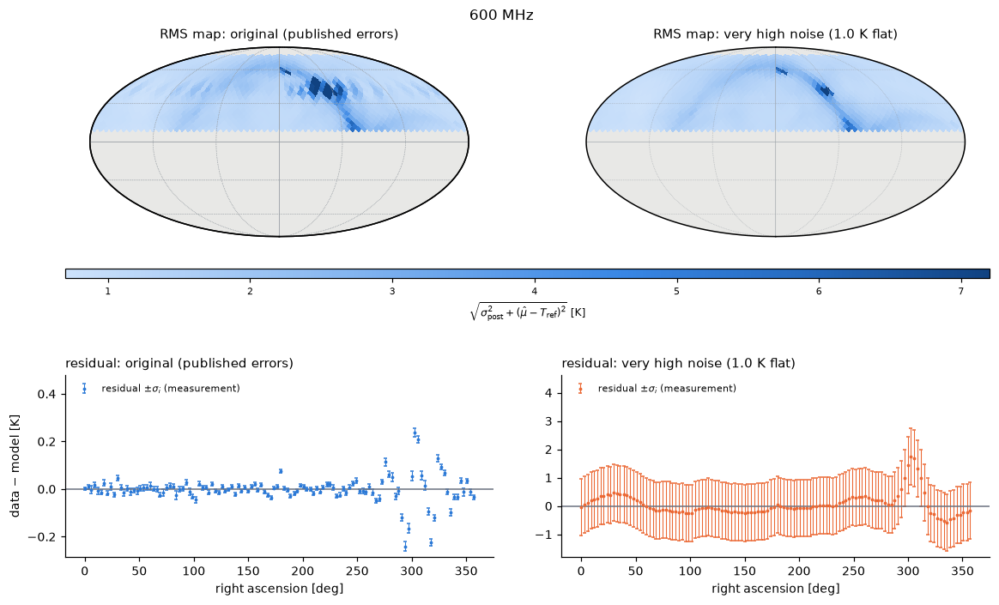

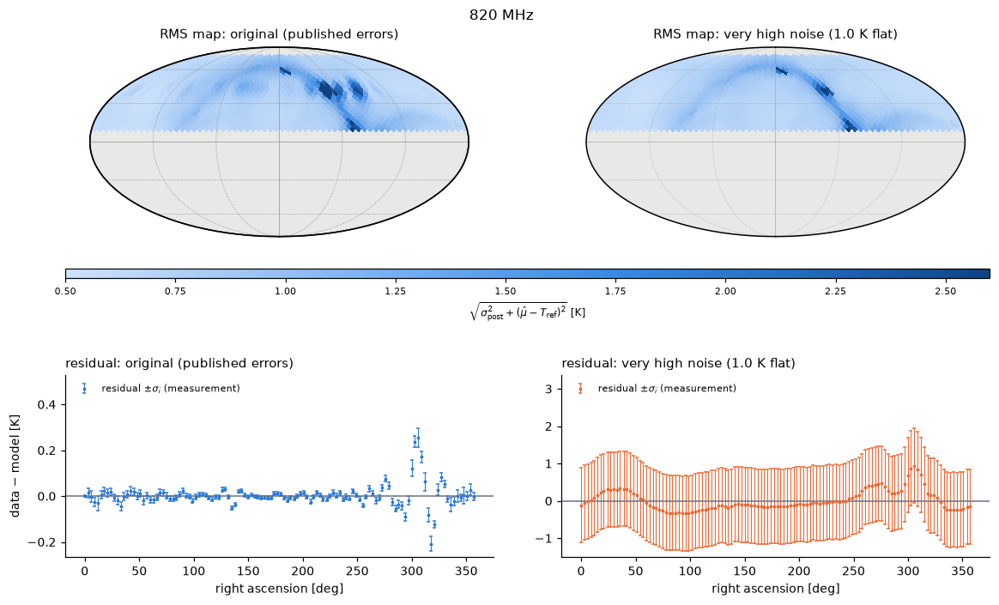

In [20]:
for freq in FREQS:
    rms = {name: rms_full(run, freq) for name, (run, _) in CASES.items()}
    rlo = float(np.floor(min(np.nanmin(m) for m in rms.values()) * 10) / 10)
    rhi = float(np.ceil(max(np.nanpercentile(m, 99) for m in rms.values()) * 10) / 10)

    fig = plt.figure(figsize=(11, 6.6))
    gs = fig.add_gridspec(4, 2, height_ratios=[1, 0.05, 0.18, 0.95],
                          hspace=0.30, wspace=0.16,
                          left=0.08, right=0.97, top=0.90, bottom=0.08)

    for column, (name, m) in enumerate(rms.items()):
        plt.sca(fig.add_subplot(gs[0, column]))
        hp.mollview(m, coord="C", min=rlo, max=rhi, hold=True,
                    cbar=False, notext=True, title="", badcolor="#e8e8e6")
        hp.graticule(dpar=30, dmer=60, color="#9aa0a6", lw=0.4)
        fig.axes[-1].set_title(f"RMS map: {name}", pad=6)

    cb = fig.colorbar(ScalarMappable(Normalize(rlo, rhi), SEQ),
                      cax=fig.add_subplot(gs[1, :]), orientation="horizontal")
    cb.set_label(r"$\sqrt{\sigma_\mathrm{post}^2 + (\hat\mu - T_\mathrm{ref})^2}$ [K]")

    for column, name in enumerate(CASES):
        e = RESID_ERR[name, freq]
        run, colour = CASES[name]
        ra = run["ra_deg"][run.index(freq)]
        # Each panel gets its own y range: the two cases' error bars differ ~100x,
        # so a shared axis would flatten the original run's bars to nothing.
        ax = fig.add_subplot(gs[3, column])
        # ax.fill_between(ra, -e["sigma_r"], e["sigma_r"], color=colour, alpha=0.30,
        #                 lw=0, step="mid", label=r"$\pm\sigma_{r}$ (expected residual)")
        ax.errorbar(ra, e["r"], yerr=e["sigma"], fmt=".", ms=3, lw=0.7,
                    elinewidth=0.7, capsize=1.5, color=colour,
                    label=r"residual $\pm\sigma_i$ (measurement)")
        ax.axhline(0, color="#6b7280")
        ax.set_xlabel("right ascension [deg]")
        ax.set_title(f"residual: {name}", loc="left")
        # ax.grid(alpha=0.18, lw=0.6); ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        # Headroom above the data so the legend never sits on a point.
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + 0.35 * (hi - lo))
        ax.legend(loc="upper left", ncol=2)
        if column == 0:
            ax.set_ylabel("data − model [K]")

    fig.suptitle(f"{freq} MHz", y=0.96)
    plt.show()


**How to read these.**

* **Original run.** Away from RA ≈ 260–350° the residual is mostly consistent with its
  error bar. Overall, 61% (600 MHz) and 71% (820 MHz) of samples satisfy
  $|r_i| < \sigma_i$. Across that RA range, which is where the ring crosses the Galactic
  plane around Cygnus, the residual reaches 5–10 $\sigma_i$. The shaded $\pm\sigma_r$
  band is so narrow that it is hard to see. The fit uses almost all of the ring
  ($\sum h_i \approx 110$ of 120 at 600 MHz, 93 at 820 MHz), so it has already absorbed
  most of each sample's noise. On the correct scale, only 28% and 41% of samples fall
  inside $\pm\sigma_r$, against 68% expected. Also
  $\chi^2/(n-\sum h_i) = 67$ and 11, not the 5.6 and 2.6 that $\chi^2/n$ reports. Same
  conclusion as section 2, GSM2008 is the limitation, but the tension is an order of
  magnitude larger than the naive reduced χ² suggests.
* **High-noise run.** Here $\sigma_r \approx \sigma_i = 1$ K and $\sum h_i$ is only 3–5.
  The data barely moves the fit, and almost every residual sits well inside its error
  bar. That is the prior-dominated limit: $\chi^2 \ll n$ because the noise was inflated
  on purpose, not because the model fits.
* **RMS maps.** These are the maps from the previous section, placed next to the residual
  they belong to. The original run's RMS is largest along the plane crossing, which is the
  same stretch of RA where its residual breaks out of its error bars.


In [ ]:
# Total notebook run time: from the first code cell (which sets _NB_T0) to here.
import time as _nb_time
if "_NB_T0" in globals():
    _dt = _nb_time.time() - _NB_T0
    print(f"total notebook run time: {_dt:.0f} s ({int(_dt // 3600)}h {int(_dt % 3600 // 60):02d}m {int(_dt % 60):02d}s)")
else:
    print("total notebook run time: not recorded (the first code cell was not run)")